# <h1 style="font-weight: bold;">OULAD Final Project Analysis</h1>

#### <h3 style="color: yellow; font : bold;">1. Set Up the SQL Server Connection Libraries</h3>

In [11]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

In [12]:
from sqlalchemy import create_engine, text  #  مكتبة (ORM) داعمة لقواعد البيانات في لغة بايثون لتجهيز الأدوات اللي هتمكننا من الاتصال بقاعدة البيانات
from sqlalchemy.engine import URL
server_name = r"DESKTOP-Q746O4J"     # اسم السيرفر   
database_name = "OULAD"              # اسم قاعدة البيانات 

connection_string = (
    "DRIVER={ODBC Driver 18 for SQL Server};"
    f"SERVER={server_name};"
    f"DATABASE={database_name};"
    "Trusted_Connection=yes;"
    "TrustServerCertificate=yes;"
)

connection_url = URL.create(
    "mssql+pyodbc",
    query={"odbc_connect": connection_string}
)

engine = create_engine(connection_url)

# اختبار الاتصال فقط
with engine.connect() as connection:
    result = pd.read_sql_query(
        text("SELECT @@SERVERNAME AS ServerName, DB_NAME() AS DatabaseName"),
        connection
    )

print(result)

        ServerName DatabaseName
0  DESKTOP-Q746O4J        OULAD


#### <h3 style="color: yellow; font : bold;">2. Load the Tables and Validate Their Relationships</h3>

##### Load the warehouse tables into the `tables` dictionary

In [13]:
from sqlalchemy import inspect

# تحديد الـ Schema المطلوب تحميل جداولها
schema_name = "dw"

# اكتشاف أسماء كل الجداول الموجودة داخل الـ Schema
inspector = inspect(engine)
table_names = inspector.get_table_names(schema=schema_name)

# تحميل كل جدول بكل أعمدته داخل DataFrame
# وتخزين الـ DataFrames في قاموس اسمه tables
with engine.connect() as connection:
    tables = {
        table_name: pd.read_sql_table(
            table_name=table_name,
            con=connection,
            schema=schema_name
        )
        for table_name in table_names
    }

# ملخص الجداول التي تم تحميلها
loaded_tables = pd.DataFrame(
    [
        {
            "Table": f"{schema_name}.{name}",
            "Rows": len(data),
            "Columns": data.shape[1]
        }
        for name, data in tables.items()
    ],
    columns=["Table", "Rows", "Columns"]
)
# عرض أسماء الجداول المحملة
print(list(tables.keys()))
print(loaded_tables.to_string(index=False))
# مثال للوصول إلى جدول وعرض أول 5 صفوف
tables["FactEnrollment"].head()

['DimAssessment', 'DimCourseOffering', 'DimFinalResult', 'DimLearningResource', 'DimRelativeDay', 'DimStudent', 'FactDailyInteraction', 'FactEnrollment', 'FactStudentAssessment']
                   Table    Rows  Columns
        dw.DimAssessment     206        4
    dw.DimCourseOffering      22        6
       dw.DimFinalResult       5        4
  dw.DimLearningResource    6364        4
       dw.DimRelativeDay     974        4
           dw.DimStudent   28785        6
 dw.FactDailyInteraction 8459320        7
       dw.FactEnrollment   32593       10
dw.FactStudentAssessment  173912        9


,EnrollmentID,StudentID,CourseOfferingCode,AgeBand,FinalResultKey,PreviousAttempts,StudiedCredits,RegistrationDay,UnregistrationDay,EnrollmentCount
0,1,52130,A2013J,0-35,1,0,90,-33.0,NaN,1
1,2,65002,A2013J,0-35,4,0,60,-180.0,96.0,1
2,3,102952,A2013J,0-35,1,0,60,-100.0,NaN,1
3,4,111717,A2013J,35-55,1,0,60,-43.0,NaN,1
4,5,129955,A2013J,0-35,4,0,60,-197.0,135.0,1


##### Check table keys for missing values and duplicates

In [14]:
from sqlalchemy import inspect, text

schema_name = "dw"

inspector = inspect(engine)
table_names = inspector.get_table_names(schema=schema_name)

quote = engine.dialect.identifier_preparer.quote

# مفاتيح إضافية نريد فحصها حتى لو لم تكن معرفة كـ UNIQUE
extra_keys = {
    "FactEnrollment": [
        ["StudentID", "CourseOfferingCode"]
    ]
}

results = []

with engine.connect() as connection:

    for table_name in table_names:

        keys = set()

        # 1) استخراج الـ Primary Key
        primary_key = inspector.get_pk_constraint(
            table_name,
            schema=schema_name
        )

        columns = primary_key.get("constrained_columns") or []

        if columns:
            keys.add(tuple(columns))

        # 2) استخراج الـ Unique Indexes
        indexes = inspector.get_indexes(
            table_name,
            schema=schema_name
        )

        for index in indexes:

            columns = index.get("column_names") or []
            options = index.get("dialect_options") or {}

            # استبعاد الفهارس المفلترة
            is_filtered = options.get("mssql_where") is not None

            if (
                index.get("unique")
                and not is_filtered
                and columns
                and all(col is not None for col in columns)
            ):
                keys.add(tuple(columns))

        # 3) إضافة مفاتيح الفحص اليدوية
        for columns in extra_keys.get(table_name, []):
            keys.add(tuple(columns))

        # تسجيل الجداول التي لم نكتشف لها مفتاحًا
        if not keys:
            results.append({
                "Table": table_name,
                "Key": "—",
                "Status": "NO KEY FOUND"
            })
            continue

        full_table_name = (
            f"{quote(schema_name)}.{quote(table_name)}"
        )

        # 4) فحص كل مفتاح
        for columns in sorted(keys):

            key_columns = ", ".join(
                quote(col) for col in columns
            )

            null_condition = " OR ".join(
                f"{quote(col)} IS NULL"
                for col in columns
            )

            has_null = connection.execute(
                text(f"""
                    SELECT CASE WHEN EXISTS (
                        SELECT 1
                        FROM {full_table_name}
                        WHERE {null_condition}
                    )
                    THEN 1 ELSE 0 END
                """)
            ).scalar_one()

            has_duplicates = connection.execute(
                text(f"""
                    SELECT CASE WHEN EXISTS (
                        SELECT 1
                        FROM {full_table_name}
                        GROUP BY {key_columns}
                        HAVING COUNT_BIG(*) > 1
                    )
                    THEN 1 ELSE 0 END
                """)
            ).scalar_one()

            issues = []

            if has_null:
                issues.append("NULL")

            if has_duplicates:
                issues.append("DUPLICATES")

            results.append({
                "Table": table_name,
                "Key": ", ".join(columns),
                "Status": " + ".join(issues) if issues else "PASS"
            })

# 5) عرض النتائج
key_check_summary = pd.DataFrame(
    results,
    columns=["Table", "Key", "Status"]
)

print(f"Tables discovered: {len(table_names)}")
print(key_check_summary.to_string(index=False))

# منع إعلان النجاح بدون نتائج
if key_check_summary.empty:
    raise ValueError(
        "No checks were recorded. Check schema_name and code execution."
    )

# التأكد من تسجيل نتيجة لكل جدول
if key_check_summary["Table"].nunique() != len(table_names):
    raise ValueError(
        "Some discovered tables have no recorded results."
    )

if key_check_summary["Status"].ne("PASS").any():
    raise ValueError(
        "Some keys failed or were not found. Review the summary."
    )

print("\nAll inspected keys passed.")

Tables discovered: 9
                Table                               Key Status
        DimAssessment                      AssessmentID   PASS
    DimCourseOffering                CourseOfferingCode   PASS
    DimCourseOffering      ModuleCode, PresentationCode   PASS
       DimFinalResult                       FinalResult   PASS
       DimFinalResult                    FinalResultKey   PASS
  DimLearningResource                            SiteID   PASS
       DimRelativeDay                       RelativeDay   PASS
           DimStudent                         StudentID   PASS
 FactDailyInteraction                     InteractionID   PASS
 FactDailyInteraction StudentID, SiteID, InteractionDay   PASS
       FactEnrollment                      EnrollmentID   PASS
       FactEnrollment     StudentID, CourseOfferingCode   PASS
FactStudentAssessment               StudentAssessmentID   PASS
FactStudentAssessment           StudentID, AssessmentID   PASS

All inspected keys passed.


##### Validate referential integrity between tables

In [15]:
from sqlalchemy import inspect, text

schema_name = "dw"

inspector = inspect(engine)
table_names = inspector.get_table_names(schema=schema_name)

quote = engine.dialect.identifier_preparer.quote
results = []

with engine.connect() as connection:

    for table_name in table_names:

        foreign_keys = inspector.get_foreign_keys(
            table_name,
            schema=schema_name
        )

        for fk in foreign_keys:

            child_columns = fk["constrained_columns"]
            parent_columns = fk["referred_columns"]

            parent_schema = fk.get("referred_schema") or schema_name
            parent_table = fk["referred_table"]

            child_full_name = (
                f"{quote(schema_name)}.{quote(table_name)}"
            )

            parent_full_name = (
                f"{quote(parent_schema)}.{quote(parent_table)}"
            )

            # شرط مطابقة أعمدة المفتاح بين الجدولين
            match_condition = " AND ".join(
                f"p.{quote(parent_col)} = c.{quote(child_col)}"
                for child_col, parent_col
                in zip(child_columns, parent_columns)
            )

            # فحص القيم المكتملة فقط؛ NULL يُراجع بشكل منفصل
            complete_condition = " AND ".join(
                f"c.{quote(col)} IS NOT NULL"
                for col in child_columns
            )

            missing_condition = " OR ".join(
                f"c.{quote(col)} IS NULL"
                for col in child_columns
            )

            query = text(f"""
                SELECT
                    (
                        SELECT COUNT_BIG(*)
                        FROM {child_full_name} AS c
                        WHERE {missing_condition}
                    ) AS NullKeyRows,

                    (
                        SELECT COUNT_BIG(*)
                        FROM {child_full_name} AS c
                        WHERE {complete_condition}
                          AND NOT EXISTS (
                              SELECT 1
                              FROM {parent_full_name} AS p
                              WHERE {match_condition}
                          )
                    ) AS OrphanRows
            """)

            counts = connection.execute(query).mappings().one()

            null_rows = int(counts["NullKeyRows"])
            orphan_rows = int(counts["OrphanRows"])

            results.append({
                "ChildTable": table_name,
                "ForeignKey": ", ".join(child_columns),
                "ParentTable": f"{parent_schema}.{parent_table}",
                "ParentKey": ", ".join(parent_columns),
                "NullKeyRows": null_rows,
                "OrphanRows": orphan_rows,
                "Status": (
                    "FAIL" if orphan_rows > 0
                    else "REVIEW NULL" if null_rows > 0
                    else "PASS"
                )
            })

fk_check_summary = pd.DataFrame(
    results,
    columns=[
        "ChildTable",
        "ForeignKey",
        "ParentTable",
        "ParentKey",
        "NullKeyRows",
        "OrphanRows",
        "Status"
    ]
)

print(f"Tables discovered: {len(table_names)}")
print(f"Relationships checked: {len(results)}")
print(fk_check_summary.to_string(index=False))

if fk_check_summary.empty:
    raise ValueError(
        "No declared foreign keys were found. "
        "Relationships must be specified manually."
    )

if fk_check_summary["OrphanRows"].gt(0).any():
    raise ValueError(
        "Unmatched foreign-key values found. Review fk_check_summary."
    )

if fk_check_summary["NullKeyRows"].gt(0).any():
    print(
        "\nNo orphan rows found, but NULL keys need review."
    )
else:
    print("\nAll declared foreign keys passed.")

Tables discovered: 9
Relationships checked: 12
           ChildTable         ForeignKey            ParentTable          ParentKey  NullKeyRows  OrphanRows Status
 FactDailyInteraction CourseOfferingCode   dw.DimCourseOffering CourseOfferingCode            0           0   PASS
 FactDailyInteraction     FinalResultKey      dw.DimFinalResult     FinalResultKey            0           0   PASS
 FactDailyInteraction     InteractionDay      dw.DimRelativeDay        RelativeDay            0           0   PASS
 FactDailyInteraction             SiteID dw.DimLearningResource             SiteID            0           0   PASS
 FactDailyInteraction          StudentID          dw.DimStudent          StudentID            0           0   PASS
       FactEnrollment CourseOfferingCode   dw.DimCourseOffering CourseOfferingCode            0           0   PASS
       FactEnrollment     FinalResultKey      dw.DimFinalResult     FinalResultKey            0           0   PASS
       FactEnrollment          St

##### Assign the tables to DataFrame variables

In [16]:
df_enrollment = tables["FactEnrollment"]
df_student = tables["DimStudent"]
df_course = tables["DimCourseOffering"]
df_result = tables["DimFinalResult"]
df_assessment = tables["DimAssessment"]
df_vle = tables["DimLearningResource"]
df_relativeday = tables["DimRelativeDay"]
df_studentassessment = tables["FactStudentAssessment"]
df_interaction = tables["FactDailyInteraction"]

#### <h3 style="color: yellow; font : bold;">3. Analysis One: Student Outcomes, Success and Withdrawal</h3>

##### Join FactEnrollment, DimStudent, DimCourseOffering and DimFinalResult

In [17]:
# إنشاء دالة لدمج الجداول مع حماية عدد الصفوف
merge_checks = []

def checked_merge(left, right, key, dimension_name):
    rows_before = len(left)

    merged = left.merge(
        right,
        on=key,
        how="left",
        validate="many_to_one",
        indicator="_merge_check"
    )

    unmatched = merged["_merge_check"].ne("both").sum()

    merge_checks.append({
        "Dimension": dimension_name,
        "RowsBefore": rows_before,
        "RowsAfter": len(merged),
        "UnmatchedRows": int(unmatched)
    })

    if len(merged) != rows_before:
        raise ValueError(
            f"{dimension_name}: merge changed the row count."
        )

    if unmatched > 0:
        examples = (
            merged.loc[merged["_merge_check"].ne("both"), [key]]
            .drop_duplicates()
            .head()
        )

        raise ValueError(
            f"{dimension_name}: {unmatched} unmatched rows.\n"
            f"{examples.to_string(index=False)}"
        )

    return merged.drop(columns="_merge_check")


df_analysis = checked_merge(
    df_enrollment,
    df_student,
    "StudentID",
    "DimStudent"
)

df_analysis = checked_merge(
    df_analysis,
    df_course,
    "CourseOfferingCode",
    "DimCourseOffering"
)

df_analysis = checked_merge(
    df_analysis,
    df_result,
    "FinalResultKey",
    "DimFinalResult"
)

merge_report = pd.DataFrame(merge_checks)

print(merge_report.to_string(index=False))
print("\nAnalysis table shape:", df_analysis.shape)
print(df_analysis.head().to_string(index=False))

        Dimension  RowsBefore  RowsAfter  UnmatchedRows
       DimStudent       32593      32593              0
DimCourseOffering       32593      32593              0
   DimFinalResult       32593      32593              0

Analysis table shape: (32593, 23)
 EnrollmentID  StudentID CourseOfferingCode AgeBand  FinalResultKey  PreviousAttempts  StudiedCredits  RegistrationDay  UnregistrationDay  EnrollmentCount Gender               Region      HighestEducation IMDBand Disability ModuleCode PresentationCode  PresentationLengthDays  PresentationYear PresentationTerm FinalResult  IsSuccess  IsWithdrawn
            1      52130             A2013J    0-35               1                 0              90            -33.0                NaN                1      F  EAST ANGLIAN REGION A LEVEL OR EQUIVALENT  70-80%          N        AAA            2013J                     268              2013                J        PASS       True        False
            2      65002             A2013J    

##### Add analytical flags to the analysis dataset

In [18]:
# Preserve original columns and create analytical versions.

df_analysis["Outcome"] = (
    df_analysis["FinalResult"]
    .astype("string")
    .str.strip()
    .str.upper()
)

# These flags are based on the recorded final result.
df_analysis["IsSuccessAnalysis"] = (
    df_analysis["Outcome"]
    .isin(["PASS", "DISTINCTION"])
)

df_analysis["IsWithdrawnAnalysis"] = (
    df_analysis["Outcome"].eq("WITHDRAWN").fillna(False)
)

df_analysis["IsFailAnalysis"] = (
    df_analysis["Outcome"].eq("FAIL").fillna(False)
)

df_analysis["IsDistinctionAnalysis"] = (
    df_analysis["Outcome"].eq("DISTINCTION").fillna(False)
)

df_analysis["IsKnownOutcome"] = (
    df_analysis["Outcome"]
    .isin(["PASS", "DISTINCTION", "FAIL", "WITHDRAWN"])
)

df_analysis["IMDBandAnalysis"] = (
    df_analysis["IMDBand"]
    .astype("string")
    .str.strip()
    .replace({"10-20": "10-20%"})
)


print(df_analysis.head().to_string(index=False))

 EnrollmentID  StudentID CourseOfferingCode AgeBand  FinalResultKey  PreviousAttempts  StudiedCredits  RegistrationDay  UnregistrationDay  EnrollmentCount Gender               Region      HighestEducation IMDBand Disability ModuleCode PresentationCode  PresentationLengthDays  PresentationYear PresentationTerm FinalResult  IsSuccess  IsWithdrawn   Outcome  IsSuccessAnalysis  IsWithdrawnAnalysis  IsFailAnalysis  IsDistinctionAnalysis  IsKnownOutcome IMDBandAnalysis
            1      52130             A2013J    0-35               1                 0              90            -33.0                NaN                1      F  EAST ANGLIAN REGION A LEVEL OR EQUIVALENT  70-80%          N        AAA            2013J                     268              2013                J        PASS       True        False      PASS               True                False           False                  False            True          70-80%
            2      65002             A2013J    0-35             

##### Overall performance indicators

In [19]:
# حساب المفاتيح الفريدة ونسب النتائج
total_enrollments = len(df_analysis)
unique_students = df_analysis["StudentID"].nunique()
course_offerings = df_analysis["CourseOfferingCode"].nunique()
modules = df_analysis["ModuleCode"].nunique()

success_count = int(df_analysis["IsSuccessAnalysis"].sum())
withdrawal_count = int(df_analysis["IsWithdrawnAnalysis"].sum())
failure_count = int(df_analysis["IsFailAnalysis"].sum())
distinction_count = int(df_analysis["IsDistinctionAnalysis"].sum())
unknown_count = int((~df_analysis["IsKnownOutcome"]).sum())

non_withdrawn_known_count = success_count + failure_count


def percentage(numerator, denominator):
    return (
        numerator / denominator * 100
        if denominator > 0
        else np.nan
    )


general_kpis = pd.DataFrame([
    ("Student Enrollments", f"{total_enrollments:,}", "count"),
    ("Unique Students", f"{unique_students:,}", "count"),
    ("Modules", f"{modules:,}", "count"),
    ("Course Offerings", f"{course_offerings:,}", "count"),
    ("Successful Enrollments", f"{success_count:,}", "count"),
    ("Withdrawn Enrollments", f"{withdrawal_count:,}", "count"),
    ("Failed Enrollments", f"{failure_count:,}", "count"),
    ("Distinction Enrollments", f"{distinction_count:,}", "count"),
    ("Unknown / Missing Outcomes", f"{unknown_count:,}", "count"),
    ("Success Rate", f"{percentage(success_count, total_enrollments):.2f}", "%"),
    ("Withdrawal Rate", f"{percentage(withdrawal_count, total_enrollments):.2f}", "%"),
    ("Failure Rate", f"{percentage(failure_count, total_enrollments):.2f}", "%"),
    ("Distinction Rate", f"{percentage(distinction_count, total_enrollments):.2f}", "%"),
    ("Success Rate Among Non-withdrawn", f"{percentage(success_count, non_withdrawn_known_count):.2f}", "%")
    ],
    columns=["KPI", "Value", "Unit"])

print(general_kpis.to_string(index=False))

                             KPI  Value  Unit
             Student Enrollments 32,593 count
                 Unique Students 28,785 count
                         Modules      7 count
                Course Offerings     22 count
          Successful Enrollments 15,385 count
           Withdrawn Enrollments 10,156 count
              Failed Enrollments  7,052 count
         Distinction Enrollments  3,024 count
      Unknown / Missing Outcomes      0 count
                    Success Rate  47.20     %
                 Withdrawal Rate  31.16     %
                    Failure Rate  21.64     %
                Distinction Rate   9.28     %
Success Rate Among Non-withdrawn  68.57     %


In [20]:
# عرض توزيع النتائج ومطابقته بإجمالي التسجيلات
outcome_distribution = (
    df_analysis["Outcome"]
    .fillna("MISSING")
    .value_counts(dropna=False)
    .rename_axis("FinalResult")
    .reset_index(name="Enrollments")
)

outcome_distribution["Percentage"] = (
    outcome_distribution["Enrollments"]
    .div(total_enrollments if total_enrollments > 0 else np.nan)
    .mul(100)
    .round(2)
)

if outcome_distribution["Enrollments"].sum() != total_enrollments:
    raise ValueError("Outcome counts do not match total enrollments.")

print(
    outcome_distribution.to_string(
        index=False,
    )
)

FinalResult  Enrollments  Percentage
       PASS        12361       37.93
  WITHDRAWN        10156       31.16
       FAIL         7052       21.64
DISTINCTION         3024        9.28


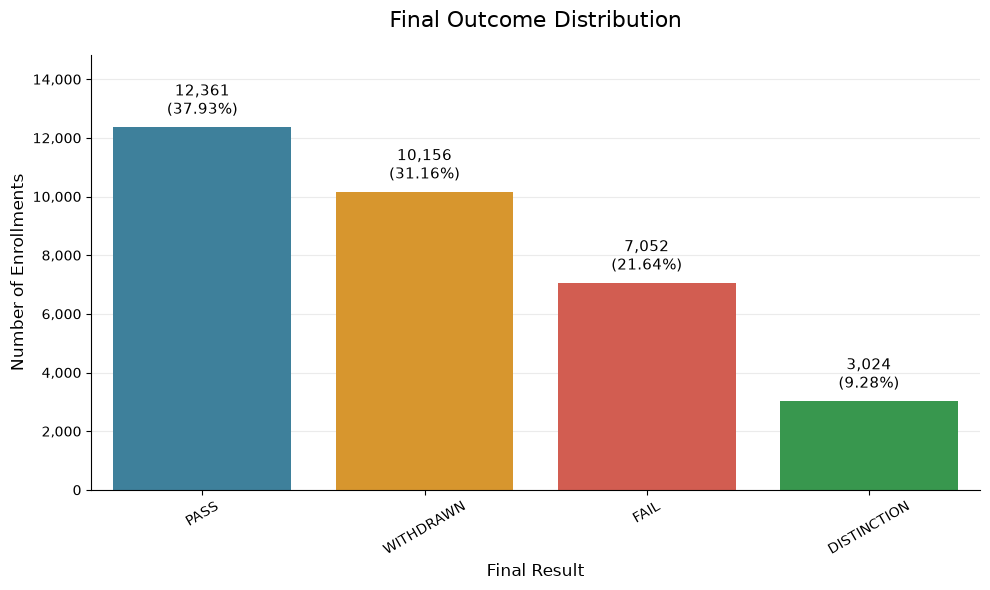

In [21]:
plot_data = outcome_distribution.sort_values(
    "Enrollments",
    ascending=False
)

colors = {
    "PASS": "#2E86AB",
    "DISTINCTION": "#28A745",
    "FAIL": "#E74C3C",
    "WITHDRAWN": "#F39C12",
    "UNKNOWN": "#95A5A6"
}

fig, ax = plt.subplots(figsize=(10, 6))

sns.barplot(
    data=plot_data,
    x="FinalResult",
    y="Enrollments",
    hue="FinalResult",
    palette={
        result: colors.get(str(result).upper(), "#95A5A6")
        for result in plot_data["FinalResult"]
    },
    dodge=False,
    legend=False,
    ax=ax
)

# كتابة العدد والنسبة فوق كل عمود
for position, row in enumerate(plot_data.itertuples(index=False)):
    ax.annotate(
        f"{row.Enrollments:,.0f}\n({row.Percentage:.2f}%)",
        xy=(position, row.Enrollments),
        xytext=(0, 6),
        textcoords="offset points",
        ha="center",
        va="bottom",
        fontsize=11
    )

ax.set_title("Final Outcome Distribution", fontsize=16, pad=20)
ax.set_xlabel("Final Result", fontsize=12)
ax.set_ylabel("Number of Enrollments", fontsize=12)

# مساحة إضافية لعرض الأرقام فوق الأعمدة
ax.margins(y=0.20)
ax.yaxis.set_major_formatter(
    plt.FuncFormatter(lambda value, _: f"{value:,.0f}")
)

ax.set_axisbelow(True)
ax.grid(axis="y", alpha=0.25)
sns.despine(ax=ax)

plt.xticks(rotation=30)
plt.tight_layout()
plt.show()

##### Initial finding

<h5 style="color: red;">Withdrawal accounts for roughly one-third of outcomes and is more common than failure, making it a priority for further analysis.</h5>

##### Compare outcomes across student characteristics

In [22]:
%pip install Jinja2                          #  لتنسيق جداول العرض بعد التشغيل بشكل أفضل

Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 26.2.1 -> 26.2.2
[notice] To update, run: python.exe -m pip install --upgrade pip
ERROR: Invalid requirement: '#': Expected package name at the start of dependency specifier
    #
    ^


In [23]:
# اختيار الخصائص الموجودة بالفعل
property_candidates = {
    "Gender": ["Gender"],
    "Age Band": ["AgeBand"],
    "Region": ["Region"],
    "Highest Education": ["HighestEducation"],
    "IMD Band": ["IMDBandAnalysis", "IMDBand"],
    "Disability": ["Disability"]
}

properties = {}

for label, candidates in property_candidates.items():
    for column in candidates:
        if column in df_analysis.columns:
            properties[label] = column
            break

if not properties:
    raise ValueError("No student characteristics found.")

# نسخة مستقلة للتحليل
data = df_analysis.copy()

data["Outcome"] = (
    data["Outcome"]
    .astype("string")
    .str.strip()
    .str.upper()
    .fillna("UNKNOWN")
    .replace("", "UNKNOWN")
)

data["Successful"] = data["Outcome"].isin(["PASS"])
data["Failed"] = data["Outcome"].eq("FAIL")
data["Withdrawn"] = data["Outcome"].eq("WITHDRAWN")
data["Distinction"] = data["Outcome"].eq("DISTINCTION")
data["UnknownOutcome"] = ~data["Outcome"].isin(
    ["PASS", "DISTINCTION", "FAIL", "WITHDRAWN"]
)

# قاموس يحتوي على جدول مقارنة لكل خاصية
outcome_by_property = {}

for label, column in properties.items():

    grouped_data = data.assign(
        Category=(
            data[column]
            .astype("string")
            .str.strip()
            .fillna("Unknown")
            .replace("", "Unknown")
        )
    )

    summary = (
        grouped_data
        .groupby("Category", as_index=False)
        .agg(
            Enrollments=("Outcome", "size"),
            Successful=("Successful", "sum"),
            Failed=("Failed", "sum"),
            Withdrawn=("Withdrawn", "sum"),
            Distinction=("Distinction", "sum"),
            UnknownOutcome=("UnknownOutcome", "sum")
        )
    )

    rate_columns = {
        "SuccessRate": "Successful",
        "FailureRate": "Failed",
        "WithdrawalRate": "Withdrawn",
        "DistinctionRate": "Distinction",
        "UnknownOutcomeRate": "UnknownOutcome"
    }

    for rate, count in rate_columns.items():
        summary[rate] = (
            summary[count]
            .div(summary["Enrollments"].replace(0, np.nan))
            .mul(100)
        )

    # التأكد من أن جميع التسجيلات ممثلة
    if summary["Enrollments"].sum() != len(data):
        raise ValueError(f"{label}: enrollment counts do not match.")

    outcome_by_property[label] = (
        summary
        .sort_values("Enrollments", ascending=False)
        .reset_index(drop=True)
    )
# -----------------------------------------------------------------------------------------------------------------------------
# عرض المقارنات كلها بدون رسوم
from IPython.display import display

# تدرج مناسب لمعنى كل مؤشر (تم إزالة UnknownOutcomeRate)
rate_colors = {
    "SuccessRate": "Greens",
    "FailureRate": "Reds",
    "WithdrawalRate": "Oranges",
    "DistinctionRate": "Blues"
}

for label, summary_df in outcome_by_property.items():

    # 1. إلغاء أعمدة Unknown من النسخة المعروضة فقط
    display_summary = summary_df.drop(
        columns=["UnknownOutcome", "UnknownOutcomeRate"], 
        errors="ignore"
    )

    # تنسيق الأعداد بفواصل، والنسب بعلامة %
    number_formats = {
        column: (
            "{:.2f}%"
            if column in rate_colors
            else "{:,.0f}"
        )
        for column in display_summary.columns
        if column != "Category"
    }

    styled_table = (
        display_summary.style
        .hide(axis="index")
        .format(number_formats, na_rep="—")
        .set_caption(f"Final Outcomes by {label}")
        .set_table_styles([
            {
                "selector": "caption",
                "props": [
                    ("font-size", "12px"),
                    ("font-weight", "bold"),
                    ("color", "#2E86AB"),
                    ("text-align", "left"),
                    ("padding", "16px 0 8px")
                ]
            },
            {
                "selector": "th",
                "props": [
                    ("background-color", "#16324F"),
                    ("color", "white"),
                    ("padding", "16px"),
                    ("text-align", "center"),
                    ("border", "1px solid #DCE3EA"),
                    ("font-size", "12px"),     # تم تصغير حجم خط العناوين قليلاً ليناسب الجدول
                    ("white-space", "nowrap") # يمنع التفاف النص
                ]
            },
            {
                "selector": "td",
                "props": [
                    ("padding", "16px 8px"),  # تقليل المسافات لضبط الحجم
                    ("text-align", "center"),
                    ("border", "1px solid #DCE3EA"),
                    ("font-size", "12px")      # تصغير حجم خط الخلايا للمساعدة في منع الـ Scroll
                ]
            },
            {
                "selector": "tbody tr:hover td",
                "props": [
                    ("background-color", "#EAF3FA"),
                    ("color", "#16324F")
                ]
            }
        ])
        .set_properties(
            subset=["Category"],
            **{
                "font-weight": "bold",
                "text-align": "left",
                "background-color": "#EEF3F8",
                "color": "#16324F"
            }
        )
    )

    # مقياس ثابت من 0% إلى 100% لجميع الجداول
    for column, color_map in rate_colors.items():
        if column in display_summary.columns:
            styled_table = styled_table.background_gradient(
                subset=[column],
                cmap=color_map,
                vmin=0,
                vmax=100
            )

    display(styled_table)

Category,Enrollments,Successful,Failed,Withdrawn,Distinction,SuccessRate,FailureRate,WithdrawalRate,DistinctionRate
M,"17,875","6,626","3,949","5,670","1,630",37.07%,22.09%,31.72%,9.12%
F,"14,718","5,735","3,103","4,486","1,394",38.97%,21.08%,30.48%,9.47%


Category,Enrollments,Successful,Failed,Withdrawn,Distinction,SuccessRate,FailureRate,WithdrawalRate,DistinctionRate
0-35,"22,944","8,469","5,231","7,381","1,863",36.91%,22.80%,32.17%,8.12%
35-55,"9,433","3,800","1,792","2,721","1,120",40.28%,19.00%,28.85%,11.87%
55<=,216,92,29,54,41,42.59%,13.43%,25.00%,18.98%


Category,Enrollments,Successful,Failed,Withdrawn,Distinction,SuccessRate,FailureRate,WithdrawalRate,DistinctionRate
SCOTLAND,"3,446","1,359",852,907,328,39.44%,24.72%,26.32%,9.52%
EAST ANGLIAN REGION,"3,340","1,309",698,"1,006",327,39.19%,20.90%,30.12%,9.79%
LONDON REGION,"3,216","1,099",744,"1,110",263,34.17%,23.13%,34.51%,8.18%
SOUTH REGION,"3,092","1,287",544,928,333,41.62%,17.59%,30.01%,10.77%
NORTH WESTERN REGION,"2,906",955,704,"1,034",213,32.86%,24.23%,35.58%,7.33%
WEST MIDLANDS REGION,"2,582",936,551,913,182,36.25%,21.34%,35.36%,7.05%
SOUTH WEST REGION,"2,436",949,465,758,264,38.96%,19.09%,31.12%,10.84%
EAST MIDLANDS REGION,"2,365",881,462,822,200,37.25%,19.53%,34.76%,8.46%
SOUTH EAST REGION,"2,111",843,375,649,244,39.93%,17.76%,30.74%,11.56%
WALES,"2,086",765,620,524,177,36.67%,29.72%,25.12%,8.49%


Category,Enrollments,Successful,Failed,Withdrawn,Distinction,SuccessRate,FailureRate,WithdrawalRate,DistinctionRate
A LEVEL OR EQUIVALENT,"14,045","5,812","2,707","4,030","1,496",41.38%,19.27%,28.69%,10.65%
LOWER THAN A LEVEL,"13,158","4,385","3,426","4,620",727,33.33%,26.04%,35.11%,5.53%
HE QUALIFICATION,"4,730","1,960",790,"1,283",697,41.44%,16.70%,27.12%,14.74%
NO FORMAL QUALS,347,87,95,149,16,25.07%,27.38%,42.94%,4.61%
POST GRADUATE QUALIFICATION,313,117,34,74,88,37.38%,10.86%,23.64%,28.12%


Category,Enrollments,Successful,Failed,Withdrawn,Distinction,SuccessRate,FailureRate,WithdrawalRate,DistinctionRate
20-30%,"3,654","1,226",844,"1,321",263,33.55%,23.10%,36.15%,7.20%
30-40%,"3,539","1,345",784,"1,095",315,38.01%,22.15%,30.94%,8.90%
10-20%,"3,516","1,167",912,"1,246",191,33.19%,25.94%,35.44%,5.43%
0-10%,"3,311",996,916,"1,231",168,30.08%,27.67%,37.18%,5.07%
40-50%,"3,256","1,224",697,"1,042",293,37.59%,21.41%,32.00%,9.00%
50-60%,"3,124","1,227",701,899,297,39.28%,22.44%,28.78%,9.51%
60-70%,"2,905","1,209",538,859,299,41.62%,18.52%,29.57%,10.29%
70-80%,"2,879","1,170",599,797,313,40.64%,20.81%,27.68%,10.87%
80-90%,"2,762","1,165",495,774,328,42.18%,17.92%,28.02%,11.88%
90-100%,"2,536","1,101",421,656,358,43.41%,16.60%,25.87%,14.12%


Category,Enrollments,Successful,Failed,Withdrawn,Distinction,SuccessRate,FailureRate,WithdrawalRate,DistinctionRate
N,"29,429","11,377","6,340","8,911","2,801",38.66%,21.54%,30.28%,9.52%
Y,"3,164",984,712,"1,245",223,31.10%,22.50%,39.35%,7.05%


In [24]:
# مثال لعرض تصنيف واحد
# النتائج حسب المقاطعة
display(outcome_by_property["Region"].round(2))

,Category,Enrollments,Successful,Failed,Withdrawn,Distinction,UnknownOutcome,SuccessRate,FailureRate,WithdrawalRate,DistinctionRate,UnknownOutcomeRate
0,SCOTLAND,3446,1359,852,907,328,0,39.44,24.72,26.32,9.52,0.0
1,EAST ANGLIAN REGION,3340,1309,698,1006,327,0,39.19,20.9,30.12,9.79,0.0
2,LONDON REGION,3216,1099,744,1110,263,0,34.17,23.13,34.51,8.18,0.0
3,SOUTH REGION,3092,1287,544,928,333,0,41.62,17.59,30.01,10.77,0.0
4,NORTH WESTERN REGION,2906,955,704,1034,213,0,32.86,24.23,35.58,7.33,0.0
5,WEST MIDLANDS REGION,2582,936,551,913,182,0,36.25,21.34,35.36,7.05,0.0
6,SOUTH WEST REGION,2436,949,465,758,264,0,38.96,19.09,31.12,10.84,0.0
7,EAST MIDLANDS REGION,2365,881,462,822,200,0,37.25,19.53,34.76,8.46,0.0
8,SOUTH EAST REGION,2111,843,375,649,244,0,39.93,17.76,30.74,11.56,0.0
9,WALES,2086,765,620,524,177,0,36.67,29.72,25.12,8.49,0.0


In [25]:
%pip install ipywidgets                      # لعمل الفلاتر

Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 26.2.1 -> 26.2.2
[notice] To update, run: python.exe -m pip install --upgrade pip
ERROR: Invalid requirement: '#': Expected package name at the start of dependency specifier
    #
    ^


In [26]:
import matplotlib.pyplot as plt
import ipywidgets as widgets
from IPython.display import display

# الخصائص المتاحة للتحليل
property_candidates = {
    "Gender": ["Gender"],
    "Age Band": ["AgeBand"],
    "Region": ["Region"],
    "Highest Education": ["HighestEducation"],
    "IMD Band": ["IMDBandAnalysis", "IMDBand"],
    "Disability": ["Disability"]
}

properties = {}

for label, candidates in property_candidates.items():
    for column in candidates:
        if column in df_analysis.columns:
            properties[label] = column
            break

if not properties:
    raise ValueError("No student characteristics found in df_analysis.")

# نسخة مستقلة من الأعمدة المطلوبة
columns = list(dict.fromkeys(["Outcome", *properties.values()]))
bar_data = df_analysis[columns].copy()

bar_data["Outcome"] = (
    bar_data["Outcome"]
    .astype("string")
    .str.strip()
    .str.upper()
    .fillna("UNKNOWN")
    .replace("", "UNKNOWN")
)

for column in properties.values():
    bar_data[column] = (
        bar_data[column]
        .astype("string")
        .str.strip()
        .fillna("Unknown")
        .replace("", "Unknown")
    )

# تسميات واضحة
if "Gender" in bar_data.columns:
    bar_data["Gender"] = bar_data["Gender"].replace({
        "M": "Male",
        "F": "Female"
    })

if "Disability" in bar_data.columns:
    bar_data["Disability"] = bar_data["Disability"].replace({
        "Y": "Yes",
        "N": "No"
    })

# تجميع الأعداد مرة واحدة لتسريع الفلاتر
counts_by_property = {
    label: pd.crosstab(
        bar_data["Outcome"],
        bar_data[column]
    )
    for label, column in properties.items()
}

import numpy as np
from matplotlib.ticker import PercentFormatter

# ترتيب النتائج وألوانها
preferred_order = [
    "PASS", "DISTINCTION", "FAIL", "WITHDRAWN", "UNKNOWN"
]

available_outcomes = bar_data["Outcome"].unique().tolist()

outcomes = [
    value for value in preferred_order
    if value in available_outcomes
] + sorted(
    value for value in available_outcomes
    if value not in preferred_order
)

outcome_colors = {
    "PASS": "#2E8B57",
    "DISTINCTION": "#4169E1",
    "FAIL": "#E74C3C",
    "WITHDRAWN": "#F39C12",
    "UNKNOWN": "#95A5A6"
}

# ألوان لأي نتائج إضافية
palette = plt.get_cmap("tab20")

for index, outcome in enumerate(outcomes):
    if outcome not in outcome_colors:
        outcome_colors[outcome] = palette(index % 20)

# الفلاتر
outcome_filter = widgets.Dropdown(
    options=[("All outcomes", None)] + [
        (outcome, outcome) for outcome in outcomes
    ],
    description="Outcome:"
)

property_filter = widgets.Dropdown(
    options=list(properties),
    description="Property:"
)

output = widgets.Output()


def draw_stacked_bar(change=None):

    selected_outcome = outcome_filter.value
    property_name = property_filter.value

    # الصفوف = فئات الخاصية، الأعمدة = النتائج
    counts = (
        counts_by_property[property_name]
        .reindex(index=outcomes, fill_value=0)
        .T
    )

    # إجمالي التسجيلات داخل كل فئة، شامل جميع النتائج
    category_totals = counts.sum(axis=1)

    counts = counts.loc[category_totals > 0]
    category_totals = category_totals.loc[counts.index]

    # نسب النتائج داخل كل فئة
    percentages = (
        counts
        .div(category_totals, axis=0)
        .mul(100)
    )

    shown_outcomes = (
        outcomes
        if selected_outcome is None
        else [selected_outcome]
    )

    with output:
        output.clear_output(wait=True)

        if counts.empty:
            print("No data for this selection.")
            return

        fig, ax = plt.subplots(figsize=(12, 7))

        positions = np.arange(len(counts))
        bottom = np.zeros(len(counts))

        for outcome in shown_outcomes:

            values = percentages[outcome].to_numpy()

            bars = ax.bar(
                positions,
                values,
                bottom=bottom,
                label=outcome,
                color=outcome_colors[outcome],
                edgecolor="white",
                linewidth=0.8,
                width=0.65
            )

            # كتابة النسبة داخل كل جزء إذا كانت المساحة مناسبة
            for index, (bar, value) in enumerate(zip(bars, values)):
                if value >= 3:
                    ax.text(
                        bar.get_x() + bar.get_width() / 2,
                        bottom[index] + value / 2,
                        f"{value:.1f}%",
                        ha="center",
                        va="center",
                        fontsize=10,
                        color="white",
                        fontweight="bold"
                    )

            bottom += values

        # عدد التسجيلات الكلي لكل فئة أسفل اسمها
        category_labels = [
            f"{category}\n(n={int(category_totals.loc[category]):,})"
            for category in counts.index
        ]

        ax.set_xticks(positions)
        ax.set_xticklabels(
            category_labels,
            rotation=35 if len(counts) > 4 else 0,
            ha="right" if len(counts) > 4 else "center"
        )

        outcome_title = (
            "All outcomes"
            if selected_outcome is None
            else selected_outcome
        )

        ax.set_title(
            f"Outcome Distribution by {property_name} — {outcome_title}",
            fontsize=14,
            pad=20
        )

        ax.set_xlabel(property_name, fontsize=12)
        ax.set_ylabel("Percentage of category enrollments", fontsize=12)

        ax.set_ylim(0, 100)
        ax.yaxis.set_major_formatter(PercentFormatter(xmax=100))

        ax.legend(
            title="Outcome",
            bbox_to_anchor=(1.02, 1),
            loc="upper left"
        )

        ax.set_axisbelow(True)
        ax.grid(axis="y", alpha=0.25)

        ax.spines["top"].set_visible(False)
        ax.spines["right"].set_visible(False)

        plt.tight_layout()
        plt.show()
        

        # جدول يوضح النسب الدقيقة، بما فيها الأجزاء الصغيرة
        print("Outcome percentages within each category:")
        display(percentages[shown_outcomes].round(2))


outcome_filter.observe(draw_stacked_bar, names="value")
property_filter.observe(draw_stacked_bar, names="value")

display(
    widgets.HBox([outcome_filter, property_filter]),
    output
)

draw_stacked_bar()

Output()

##### Deprivation, region and academic outcomes

,Enrollments,Withdrawn,Failed,WithdrawalRate,FailureRate,IMD 0-10%,IMD 10-20%,IMD 20-30%,IMD 30-40%,IMD 40-50%,IMD 50-60%,IMD 60-70%,IMD 70-80%,IMD 80-90%,IMD 90-100%,Unknown
Region,,,,,,,,,,,,,,,,
NORTH WESTERN REGION,"2,906","1,034",704,35.6%,24.2%,25.1%,12.8%,13.9%,11.1%,7.9%,8.3%,6.3%,6.7%,5.0%,2.8%,0.2%
WEST MIDLANDS REGION,"2,582",913,551,35.4%,21.3%,18.8%,14.3%,11.7%,10.0%,10.1%,7.2%,8.6%,8.1%,5.1%,4.5%,1.5%
LONDON REGION,"3,216","1,110",744,34.5%,23.1%,11.4%,21.5%,18.4%,14.4%,9.6%,7.9%,5.3%,4.4%,4.6%,2.5%,0.0%
YORKSHIRE REGION,"2,006",657,449,32.8%,22.4%,19.5%,13.0%,12.3%,10.6%,9.5%,9.5%,7.8%,8.8%,5.7%,3.0%,0.2%
WALES,"2,086",524,620,25.1%,29.7%,12.3%,11.3%,12.5%,11.1%,9.7%,10.0%,8.8%,8.7%,8.6%,7.0%,0.0%
NORTH REGION,"1,823",575,327,31.5%,17.9%,10.2%,13.3%,8.0%,6.6%,5.9%,3.6%,3.8%,4.2%,3.9%,0.4%,40.1%
EAST MIDLANDS REGION,"2,365",822,462,34.8%,19.5%,7.7%,13.0%,11.7%,10.7%,10.1%,10.1%,9.9%,8.8%,10.6%,7.4%,0.0%
IRELAND,"1,184",273,261,23.1%,22.0%,10.3%,9.5%,6.8%,7.7%,6.2%,9.1%,7.3%,7.4%,7.1%,6.1%,22.5%
SCOTLAND,"3,446",907,852,26.3%,24.7%,8.1%,8.1%,10.4%,10.9%,10.5%,11.7%,10.9%,9.7%,10.2%,9.1%,0.3%


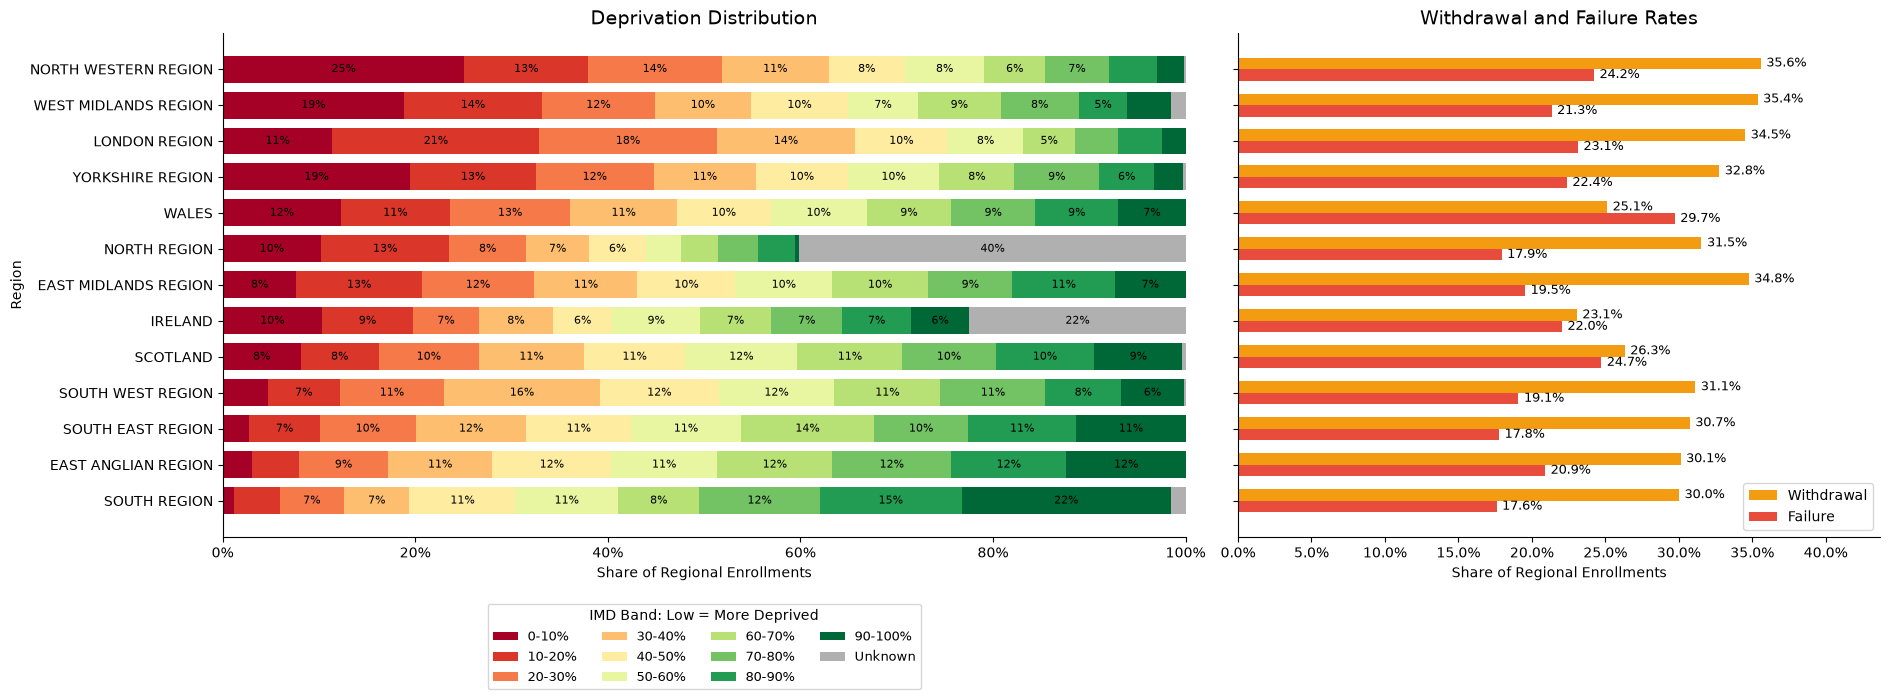

In [27]:
from matplotlib.ticker import PercentFormatter
from IPython.display import display

# اختيار عمود الحرمان
imd_column = (
    "IMDBandAnalysis"
    if "IMDBandAnalysis" in df_analysis.columns
    else "IMDBand"
)

data = df_analysis[["Region", imd_column]].copy()

data["Region"] = (
    data["Region"]
    .astype("string")
    .str.strip()
    .fillna("Unknown")
    .replace("", "Unknown")
)

# توحيد شكل فئات الحرمان
data["IMDBand"] = (
    data[imd_column]
    .astype("string")
    .str.strip()
    .str.replace(" ", "", regex=False)
    .str.replace("%", "", regex=False)
    .fillna("Unknown")
    .replace({
        "": "Unknown",
        "UNKNOWN": "Unknown",
        "unknown": "Unknown"
    })
)

imd_order = [
    "0-10", "10-20", "20-30", "30-40", "40-50",
    "50-60", "60-70", "70-80", "80-90", "90-100"
]

# منع إسقاط أي تصنيف غير متوقع بصمت
unexpected = set(data["IMDBand"]) - set(imd_order) - {"Unknown"}

if unexpected:
    raise ValueError(f"Review unexpected IMD categories: {unexpected}")

# عدد التسجيلات لكل منطقة وفئة حرمان
region_imd_counts = pd.crosstab(
    data["Region"],
    data["IMDBand"]
).reindex(
    columns=imd_order + ["Unknown"],
    fill_value=0
)

# النسب داخل كل منطقة، مع إبقاء القيم المفقودة فئة مستقلة
region_totals = region_imd_counts.sum(axis=1)

region_imd_pct = (
    region_imd_counts
    .div(region_totals, axis=0)
    .mul(100)
)

# ترتيب المناطق حسب نسبة التسجيلات في أكثر 20% حرمانًا
region_order = (
    region_imd_pct[["0-10", "10-20"]]
    .sum(axis=1)
    .sort_values(ascending=False)
    .index
)

region_imd_pct = region_imd_pct.loc[region_order]
region_totals = region_totals.loc[region_order]

# جدول العرض
import numpy as np
from matplotlib.ticker import PercentFormatter

# حساب النتائج لكل منطقة بنفس طريقة توحيد أسماء المناطق
outcome_data = df_analysis[["Region", "Outcome"]].copy()

outcome_data["Region"] = (
    outcome_data["Region"]
    .astype("string")
    .str.strip()
    .fillna("Unknown")
    .replace("", "Unknown")
)

outcome_data["Outcome"] = (
    outcome_data["Outcome"]
    .astype("string")
    .str.strip()
    .str.upper()
    .fillna("UNKNOWN")
)

outcome_data["IsWithdrawn"] = outcome_data["Outcome"].eq("WITHDRAWN")
outcome_data["IsFailed"] = outcome_data["Outcome"].eq("FAIL")

region_outcomes = (
    outcome_data
    .groupby("Region")
    .agg(
        Enrollments=("Outcome", "size"),
        Withdrawn=("IsWithdrawn", "sum"),
        Failed=("IsFailed", "sum")
    )
    .reindex(region_imd_pct.index)
)

region_outcomes["WithdrawalRate"] = (
    region_outcomes["Withdrawn"]
    .div(region_outcomes["Enrollments"])
    .mul(100)
)

region_outcomes["FailureRate"] = (
    region_outcomes["Failed"]
    .div(region_outcomes["Enrollments"])
    .mul(100)
)

# دمج توزيع الحرمان مع نتائج المناطق
display_table = (
    region_outcomes[[
        "Enrollments",
        "Withdrawn",
        "Failed",
        "WithdrawalRate",
        "FailureRate"
    ]]
    .join(
        region_imd_pct.rename(
            columns={band: f"IMD {band}%" for band in imd_order}
        ),
        validate="one_to_one"
    )
)

percentage_columns = [
    column for column in display_table.columns
    if column not in ["Enrollments", "Withdrawn", "Failed"]
]

display(
    display_table.style
    .format({
        "Enrollments": "{:,.0f}",
        "Withdrawn": "{:,.0f}",
        "Failed": "{:,.0f}",
        **{column: "{:.1f}%" for column in percentage_columns}
    })
    .background_gradient(
        subset=["WithdrawalRate"],
        cmap="Oranges",
        vmin=0,
        vmax=100
    )
    .background_gradient(
        subset=["FailureRate"],
        cmap="Reds",
        vmin=0,
        vmax=100
    )
    .set_caption("Deprivation and Final Outcomes by Region")
)

# رسمان متجاوران، بنفس ترتيب المناطق
fig, (ax_imd, ax_outcomes) = plt.subplots(
    1, 2,
    figsize=(19, max(7, len(region_imd_pct) * 0.55)),
    gridspec_kw={"width_ratios": [1.5, 1]},
    sharey=True
)

y = np.arange(len(region_imd_pct))

# 1) توزيع الحرمان
cmap = plt.get_cmap("RdYlGn")
imd_colors = {
    band: cmap(index / 9)
    for index, band in enumerate(imd_order)
}
imd_colors["Unknown"] = "#B0B0B0"

left = np.zeros(len(region_imd_pct))

for band in region_imd_pct.columns:
    values = region_imd_pct[band].to_numpy()

    bars = ax_imd.barh(
        y,
        values,
        left=left,
        color=imd_colors[band],
        label=f"{band}%" if band != "Unknown" else "Unknown",
        height=0.75
    )

    ax_imd.bar_label(
        bars,
        labels=[
            f"{value:.0f}%" if value >= 5 else ""
            for value in values
        ],
        label_type="center",
        fontsize=8
    )

    left += values

ax_imd.set_yticks(y)
ax_imd.set_yticklabels(region_imd_pct.index)
ax_imd.invert_yaxis()
ax_imd.set_xlim(0, 100)
ax_imd.set_title("Deprivation Distribution", fontsize=14)
ax_imd.set_xlabel("Share of Regional Enrollments")
ax_imd.set_ylabel("Region")

ax_imd.legend(
    title="IMD Band: Low = More Deprived",
    loc="upper center",
    bbox_to_anchor=(0.5, -0.12),
    ncol=4,
    fontsize=9
)

# 2) نسب الانسحاب والفشل
height = 0.32

withdrawal_bars = ax_outcomes.barh(
    y - height / 2,
    region_outcomes["WithdrawalRate"],
    height=height,
    color="#F39C12",
    label="Withdrawal"
)

failure_bars = ax_outcomes.barh(
    y + height / 2,
    region_outcomes["FailureRate"],
    height=height,
    color="#E74C3C",
    label="Failure"
)

for bars in [withdrawal_bars, failure_bars]:
    ax_outcomes.bar_label(
        bars,
        labels=[
            f"{bar.get_width():.1f}%"
            for bar in bars
        ],
        padding=4,
        fontsize=9
    )

max_rate = region_outcomes[
    ["WithdrawalRate", "FailureRate"]
].max().max()

ax_outcomes.set_xlim(0, max_rate * 1.2 + 1)
ax_outcomes.set_title("Withdrawal and Failure Rates", fontsize=14)
ax_outcomes.set_xlabel("Share of Regional Enrollments")
ax_outcomes.legend(loc="lower right")

for ax in [ax_imd, ax_outcomes]:
    ax.xaxis.set_major_formatter(PercentFormatter(xmax=100))
    ax.spines[["top", "right"]].set_visible(False)

plt.tight_layout()
plt.show()

Findings: Deprivation, Region and Academic Outcomes

This descriptive comparison suggests that some regions with a greater concentration of enrollments in more deprived bands also have higher withdrawal and failure rates. However, this pattern is not consistent across all regions.

- In **North Western Region**, approximately **37.9%** of enrollments fall within the two most deprived bands, `0–20%`, alongside a withdrawal rate of **35.6%** and a failure rate of **24.2%**. In **South Region**, only **5.9%** fall within the same bands, with withdrawal at **30.0%** and failure at **17.6%**.
- Deprivation alone does not explain regional differences. **Wales** has the highest failure rate among the regions shown (**29.7%**), despite a smaller share of enrollments in the two most deprived bands than North Western Region.
- Comparisons involving **North Region** and **Ireland** require caution: deprivation band is missing for **40.1%** and **22.5%** of their enrollments, respectively.

**Interpretation:** These descriptive patterns warrant further investigation, but do not establish that deprivation causes withdrawal or failure. A more informative assessment would compare outcomes across deprivation bands within each region, accounting for differences in modules and presentations.

> Percentages describe enrollments in the project sample. They do not represent regional populations or counts of unique students.

##### HighestEducation

In [104]:
from matplotlib.ticker import PercentFormatter

# 1) تجهيز البيانات
df_education = df_analysis[
    ["StudentID", "CourseOfferingCode", "HighestEducation", "Outcome"]
].copy()

df_education["HighestEducation"] = (
    df_education["HighestEducation"]
    .astype("string")
    .str.strip()
    .str.upper()
    .fillna("UNKNOWN")
    .replace("", "UNKNOWN")
)

df_education["Outcome"] = (
    df_education["Outcome"]
    .astype("string")
    .str.strip()
    .str.upper()
)

df_education["IsSuccess"] = (
    df_education["Outcome"].isin(["PASS", "DISTINCTION"])
)

df_education["IsFail"] = (
    df_education["Outcome"].eq("FAIL").fillna(False)
)

df_education["IsWithdrawn"] = (
    df_education["Outcome"].eq("WITHDRAWN").fillna(False)
)

df_education["IsKnownOutcome"] = (
    df_education["Outcome"]
    .isin(["PASS", "DISTINCTION", "FAIL", "WITHDRAWN"])
)

# 2) المعدلات العامة: التسجيلات ذات النتائج المعروفة
known_count = df_education["IsKnownOutcome"].sum()

if known_count == 0:
    raise ValueError("لا توجد نتائج معروفة لحساب النسب.")

overall_failure_rate = (
    df_education["IsFail"].sum() / known_count * 100
)

overall_withdrawal_rate = (
    df_education["IsWithdrawn"].sum() / known_count * 100
)

# 3) النتائج حسب المستوى التعليمي
education_summary = (
    df_education.groupby("HighestEducation")
    .agg(
        EnrollmentCount=("StudentID", "size"),
        KnownOutcomeCount=("IsKnownOutcome", "sum"),
        SuccessCount=("IsSuccess", "sum"),
        FailCount=("IsFail", "sum"),
        WithdrawnCount=("IsWithdrawn", "sum")
    )
)

education_summary["UnknownOutcomeCount"] = (
    education_summary["EnrollmentCount"]
    - education_summary["KnownOutcomeCount"]
)

denominator = (
    education_summary["KnownOutcomeCount"].replace(0, np.nan)
)

for count_column, rate_column in [
    ("SuccessCount", "SuccessRatePct"),
    ("FailCount", "FailRatePct"),
    ("WithdrawnCount", "WithdrawalRatePct")
]:
    education_summary[rate_column] = (
        education_summary[count_column] / denominator * 100
    )

# الفرق عن المعدل العام بالنقاط المئوية
education_summary["FailureGapPP"] = (
    education_summary["FailRatePct"] - overall_failure_rate
)

education_summary["WithdrawalGapPP"] = (
    education_summary["WithdrawalRatePct"] - overall_withdrawal_rate
)

education_summary = education_summary.sort_values(
    "WithdrawalRatePct",
    ascending=False
)

display(education_summary.round(2))

print(f"Overall failure rate: {overall_failure_rate:.2f}%")
print(f"Overall withdrawal rate: {overall_withdrawal_rate:.2f}%")

,EnrollmentCount,KnownOutcomeCount,SuccessCount,FailCount,WithdrawnCount,UnknownOutcomeCount,SuccessRatePct,FailRatePct,WithdrawalRatePct,FailureGapPP,WithdrawalGapPP
HighestEducation,,,,,,,,,,,
NO FORMAL QUALS,347,347,103,95,149,0,29.68,27.38,42.94,5.74,11.78
LOWER THAN A LEVEL,13158,13158,5112,3426,4620,0,38.85,26.04,35.11,4.4,3.95
A LEVEL OR EQUIVALENT,14045,14045,7308,2707,4030,0,52.03,19.27,28.69,-2.36,-2.47
HE QUALIFICATION,4730,4730,2657,790,1283,0,56.17,16.7,27.12,-4.93,-4.04
POST GRADUATE QUALIFICATION,313,313,205,34,74,0,65.50,10.86,23.64,-10.77,-7.52


Overall failure rate: 21.64%
Overall withdrawal rate: 31.16%


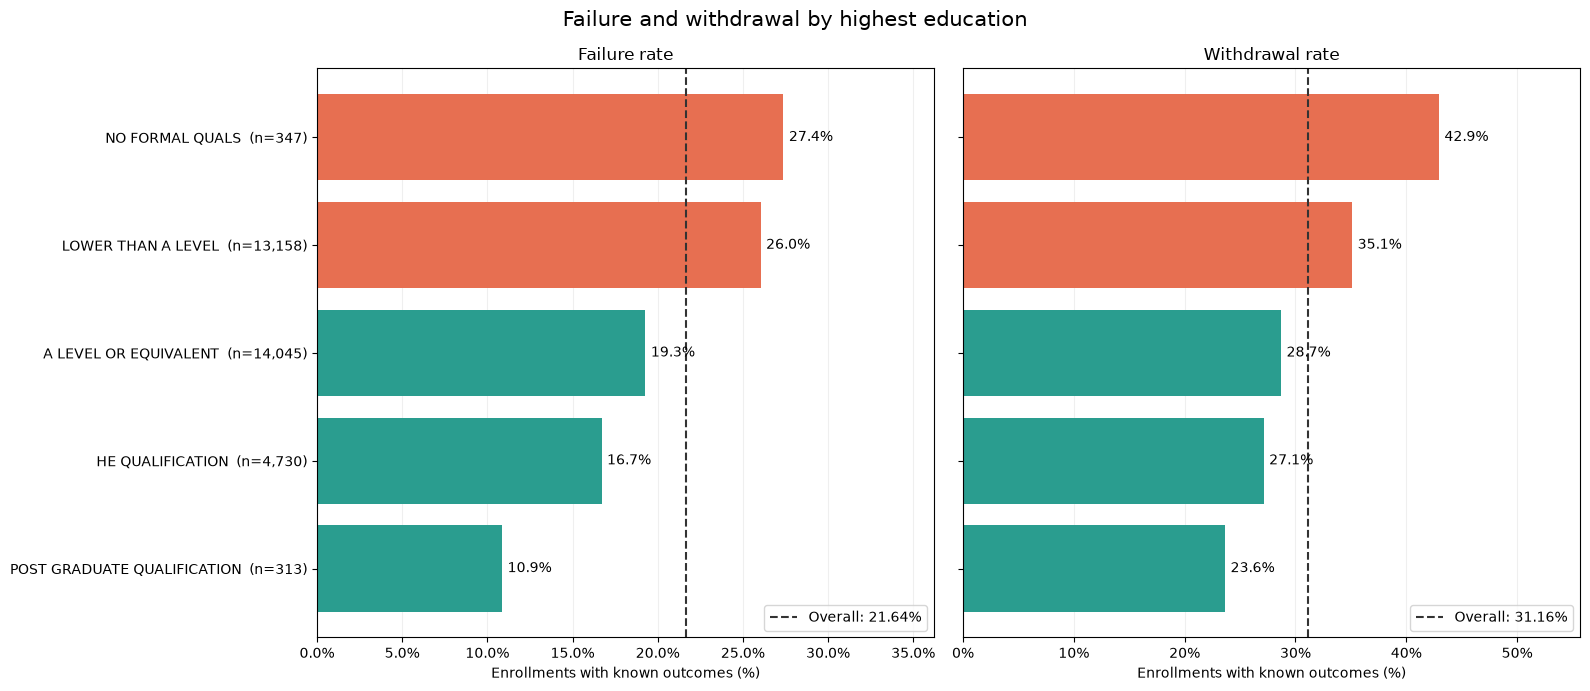

In [105]:
fig, axes = plt.subplots(
    1, 2,
    figsize=(16, 7),
    sharey=True
)

metrics = [
    ("FailRatePct", overall_failure_rate, "Failure rate"),
    ("WithdrawalRatePct", overall_withdrawal_rate, "Withdrawal rate")
]

positions = np.arange(len(education_summary))

category_labels = [
    f"{level}  (n={count:,})"
    for level, count in zip(
        education_summary.index,
        education_summary["EnrollmentCount"]
    )
]

for ax, (column, baseline, title) in zip(axes, metrics):
    values = education_summary[column]

    colors = [
        "#E76F51" if value > baseline else "#2A9D8F"
        for value in values
    ]

    bars = ax.barh(
        positions,
        values,
        color=colors
    )

    ax.bar_label(bars, fmt="%.1f%%", padding=4)

    ax.axvline(
        baseline,
        color="#333333",
        linestyle="--",
        linewidth=1.5,
        label=f"Overall: {baseline:.2f}%"
    )

    ax.set_title(title)
    ax.set_xlabel("Enrollments with known outcomes (%)")
    ax.xaxis.set_major_formatter(PercentFormatter(xmax=100))
    ax.grid(axis="x", alpha=0.2)
    ax.set_axisbelow(True)
    ax.legend(loc="lower right")

    valid_values = values.dropna()
    maximum = max(
        baseline,
        valid_values.max() if not valid_values.empty else baseline
    )
    ax.set_xlim(0, maximum * 1.25 + 2)

axes[0].set_yticks(positions)
axes[0].set_yticklabels(category_labels)
axes[0].invert_yaxis()

fig.suptitle(
    "Failure and withdrawal by highest education",
    fontsize=15
)

plt.tight_layout()
plt.show()

Lower prior educational attainment was associated with lower success rates and higher rates of failure and withdrawal. Enrollments with no formal qualifications recorded the highest failure and withdrawal rates, while those with qualifications below A Level accounted for a substantial number of both outcomes. These findings support further assessment of academic and foundational learning support needs among these groups. However, the relationship is descriptive and should be examined within individual modules, taking account of study load, previous attempts and deprivation.

##### Identify modules and presentations with higher withdrawal and failure rates

In [28]:

course_summary = (
    df_analysis
    .groupby(
        ["ModuleCode", "PresentationCode"],
        as_index=False
    )
    .agg(
        Enrollments=("EnrollmentID", "size"),      # size: بتعد كل الصفوف داخل المجموعة بلا استثناء (حتى لو فيه قيم فارغة NaN)
        Successful=("IsSuccessAnalysis", "sum"),
        Withdrawn=("IsWithdrawnAnalysis", "sum"),
        Failed=("IsFailAnalysis", "sum"),
        Distinction=("IsDistinctionAnalysis", "sum")
    )
)

rate_columns = {
    "SuccessRate": "Successful",
    "WithdrawalRate": "Withdrawn",
    "FailureRate": "Failed",
    "DistinctionRate": "Distinction"
}

for rate, count in rate_columns.items():   # حساب النسبة المئوية لأعداد الطلبة بالنسبة للنتيجة النهائية
    course_summary[rate] = (
        course_summary[count]
        .div(course_summary["Enrollments"])
        .mul(100)
    )

course_summary = course_summary.sort_values(
    ["WithdrawalRate", "Enrollments"],
    ascending=[False, False]
).reset_index(drop=True)

print(
    course_summary.to_string(
        index=False,
        float_format="{:.2f}".format
    )
)

ModuleCode PresentationCode  Enrollments  Successful  Withdrawn  Failed  Distinction  SuccessRate  WithdrawalRate  FailureRate  DistinctionRate
       CCC            2014B         1936         663        898     375          192        34.25           46.38        19.37             9.92
       CCC            2014J         2498        1015       1077     406          306        40.63           43.11        16.25            12.25
       DDD            2014B         1228         479        490     259          119        39.01           39.90        21.09             9.69
       FFF            2014J         2365        1117        855     393          258        47.23           36.15        16.62            10.91
       DDD            2014J         1803         792        647     364          112        43.93           35.88        20.19             6.21
       DDD            2013J         1938         829        681     428           98        42.78           35.14        22.08          

| Measure | Finding | Interpretation |
|---|---|---|
| Highest withdrawal rate | `CCC 2014B`: **46.38%**, or 898 enrollments | Prioritize withdrawal timing and early engagement analysis |
| Largest withdrawal count | `CCC 2014J`: **1,077**, at a rate of 43.11% | Combines a large number of cases with a high withdrawal rate |
| Highest success rate | `AAA 2013J`: **72.58%** | A useful descriptive benchmark, subject to differences in module content and enrollment size |
| Highest failure rate | `GGG 2013J`: **30.88%** | Low withdrawal does not necessarily imply low failure |
| Highest distinction rate | `GGG 2014J`: **16.96%** | Distinction forms part of this presentation's overall success rate |

In [29]:
# متوسط نسبة الإنسحاب العام
overall_withdrawal_rate = (
    df_analysis["IsWithdrawnAnalysis"].mean() * 100
)
print (f'overall_withdrawal_rate : {overall_withdrawal_rate:.2f}')

overall_withdrawal_rate : 31.16


##### Summarize outcomes by module

In [30]:
# تلخيص النتائج على مستوى المقرر
module_summary = (
    course_summary
    .groupby("ModuleCode", as_index=False)
    .agg(
        CourseOfferings=("PresentationCode", "nunique"),
        Enrollments=("Enrollments", "sum"),
        Successful=("Successful", "sum"),
        Withdrawn=("Withdrawn", "sum"),
        Failed=("Failed", "sum"),
        Distinction=("Distinction", "sum")
    )
)

for rate, count in rate_columns.items():
    module_summary[rate] = (
        module_summary[count]
        .div(module_summary["Enrollments"])
        .mul(100)
    )

# Percentage-point difference from the overall withdrawal rate.
overall_withdrawal_rate = (
    df_analysis["IsWithdrawnAnalysis"].mean() * 100
)

module_summary["WithdrawalGapPP"] = (
    module_summary["WithdrawalRate"]
    - overall_withdrawal_rate
)

module_summary = module_summary.sort_values(
    "WithdrawalRate",
    ascending=False
).reset_index(drop=True)

print(
    module_summary.to_string(
        index=False,
        float_format="{:.2f}".format
    )
)

ModuleCode  CourseOfferings  Enrollments  Successful  Withdrawn  Failed  Distinction  SuccessRate  WithdrawalRate  FailureRate  DistinctionRate  WithdrawalGapPP
       CCC                2         4434        1678       1975     781          498        37.84           44.54        17.61            11.23            13.38
       DDD                4         6272        2610       2250    1412          383        41.61           35.87        22.51             6.11             4.71
       FFF                4         7762        3648       2403    1711          670        47.00           30.96        22.04             8.63            -0.20
       BBB                4         7909        3754       2388    1767          677        47.46           30.19        22.34             8.56            -0.97
       EEE                3         2934        1650        722     562          356        56.24           24.61        19.15            12.13            -6.55
       AAA                2       

| Module | Main finding | Implication |
|---|---|---|
| **CCC** | Withdrawal of **44.54%**, **13.38 percentage points** above the overall rate | Prioritize understanding high withdrawal in both presentations |
| **DDD** | Withdrawal of **35.87%**, involving **2,250** enrollments | Combines a high rate with a large number of cases |
| **FFF** | Largest withdrawal count: **2,403**, with a rate of **30.96%** | Allocate attention to case volume and investigate differences between presentations |
| **BBB** | **2,388** withdrawals, at a rate of **30.19%** | A large enrollment base also produces a substantial number of cases |
| **EEE** | Success of **56.24%** and withdrawal of **24.61%** | Overall outcomes are more favorable than the project-wide rates |
| **AAA** | Highest success at **70.99%** and lowest failure at **12.17%** | A useful descriptive comparison, with a relatively small base of **748 enrollments** |
| **GGG** | Lowest withdrawal at **11.52%**, but highest failure at **28.73%** | Academic performance and assessment support matter alongside retention |

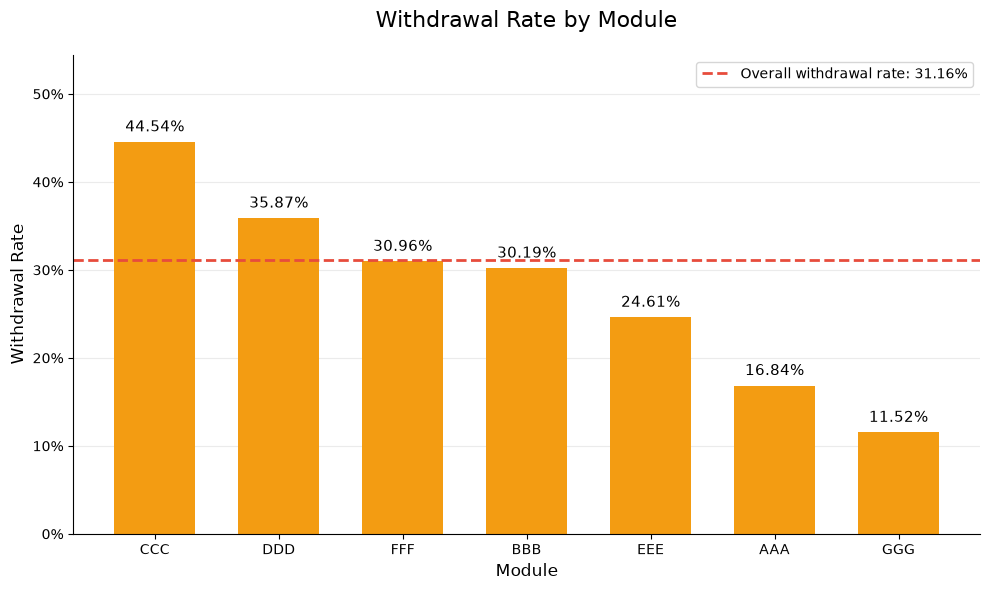

In [31]:
from matplotlib.ticker import PercentFormatter

plot_data = module_summary.sort_values(
    "WithdrawalRate",
    ascending=False
)

fig, ax = plt.subplots(figsize=(10, 6))

bars = ax.bar(
    plot_data["ModuleCode"],
    plot_data["WithdrawalRate"],
    color="#F39C12",
    width=0.65
)

# النسبة فوق كل عمود
ax.bar_label(
    bars,
    labels=[
        f"{value:.2f}%"
        for value in plot_data["WithdrawalRate"]
    ],
    padding=5,
    fontsize=11
)

# خط نسبة الانسحاب العامة
ax.axhline(
    y=overall_withdrawal_rate,
    color="#E74C3C",
    linestyle="--",
    linewidth=2,
    label=f"Overall withdrawal rate: {overall_withdrawal_rate:.2f}%"
)

ax.set_title("Withdrawal Rate by Module", fontsize=16, pad=20)
ax.set_xlabel("Module", fontsize=12)
ax.set_ylabel("Withdrawal Rate", fontsize=12)

ax.yaxis.set_major_formatter(PercentFormatter(xmax=100))
ax.set_ylim(
    0,
    max(
        plot_data["WithdrawalRate"].max(),
        overall_withdrawal_rate
    ) * 1.20 + 1
)

ax.set_axisbelow(True)
ax.grid(axis="y", alpha=0.25)
ax.spines[["top", "right"]].set_visible(False)
ax.legend()

plt.tight_layout()
plt.show()

Show each outcome within each module, with percentages calculated using that module's total enrollments.

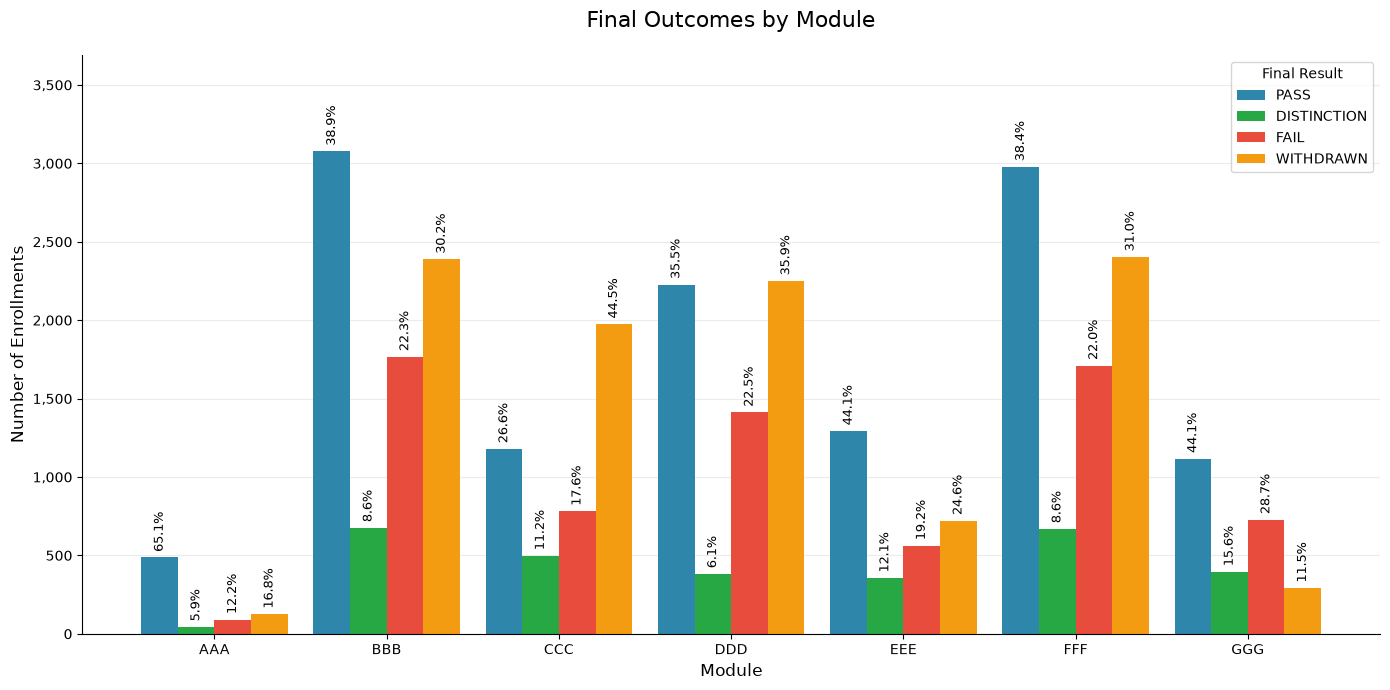

In [32]:
import matplotlib.pyplot as plt
from matplotlib.ticker import StrMethodFormatter

colors = {
    "PASS": "#2E86AB",
    "DISTINCTION": "#28A745",
    "FAIL": "#E74C3C",
    "WITHDRAWN": "#F39C12",
    "UNKNOWN": "#95A5A6"
}

# حساب عدد التسجيلات لكل نتيجة داخل كل مقرر
chart_data = pd.crosstab(
    df_analysis["ModuleCode"],
    df_analysis["Outcome"].fillna("UNKNOWN").astype(str).str.upper()
)

# ترتيب النتائج، مع الاحتفاظ بأي تصنيف إضافي موجود
outcome_order = [
    outcome for outcome in colors
    if outcome in chart_data.columns
]

outcome_order += [
    outcome for outcome in chart_data.columns
    if outcome not in colors
]

chart_data = (
    chart_data
    .reindex(columns=outcome_order)
    .sort_index()
)

# مواقع المقررات وعرض الأعمدة
x = np.arange(len(chart_data))
number_of_outcomes = len(chart_data.columns)

group_width = 0.85
bar_width = group_width / number_of_outcomes

fig, ax = plt.subplots(figsize=(14, 7))

# نسبة كل نتيجة من إجمالي تسجيلات المقرر
chart_percentages = (
    chart_data
    .div(chart_data.sum(axis=1).replace(0, np.nan), axis=0)
    .mul(100)
)

for index, outcome in enumerate(chart_data.columns):

    positions = (
        x
        - group_width / 2
        + bar_width / 2
        + index * bar_width
    )

    bars = ax.bar(
        positions,
        chart_data[outcome],
        width=bar_width,
        color=colors.get(outcome, "#95A5A6"),
        label=outcome,
        linewidth=0
    )

    # كتابة النسبة فوق كل عمود، وإخفاؤها للأعمدة ذات العدد صفر
    ax.bar_label(
        bars,
        labels=[
            f"{percentage:.1f}%" if count > 0 else ""
            for count, percentage in zip(
                chart_data[outcome],
                chart_percentages[outcome]
            )
        ],
        padding=4,
        fontsize=9,
        rotation=90
    )

# مساحة إضافية للنسب فوق الأعمدة
ax.margins(y=0.20)

ax.set_xticks(x)
ax.set_xticklabels(chart_data.index)

ax.set_title("Final Outcomes by Module", fontsize=16, pad=20)
ax.set_xlabel("Module", fontsize=12)
ax.set_ylabel("Number of Enrollments", fontsize=12)

ax.yaxis.set_major_formatter(StrMethodFormatter("{x:,.0f}"))

ax.set_axisbelow(True)
ax.grid(axis="y", alpha=0.25)
ax.spines[["top", "right"]].set_visible(False)

ax.legend(title="Final Result")
plt.tight_layout()
plt.show()

##### Withdrawal timing: before the course starts or during study?

In [33]:
# تحليل توقيت الانسحاب: هل حدث قبل بداية المقرر أم أثناءه؟ سنحسبه للتسجيلات ذات النتيجة WITHDRAWN فقط، ونُظهر يوم الانسحاب المفقود كفئة مستقلة، وفق قرار الجودة الساب
df_withdrawn = df_analysis.loc[
    df_analysis["IsWithdrawnAnalysis"]   # فلتر فى الجدول التحليلى للمنسحبين فقط   
].copy()     # لعمل نسخة مستقلة تماماً يسهل التعديل عليها بدون المساس بالجدول الأصلى

day = df_withdrawn["UnregistrationDay"]

df_withdrawn["WithdrawalTiming"] = np.select(
    [
        day.isna(),                            # none
        day.lt(0),                             # Less Than 0
        day.between(0, 27, inclusive="both"),
        day.ge(28)                             # Greater Than 28
    ],
    [
        "Unknown day",
        "Before start",
        "Days 0-27",
        "Day 28 onward"
    ],
    default="Unclassified"
)

withdrawal_timing = (
    df_withdrawn
    .groupby("WithdrawalTiming")
    .size()
    .reindex(
        ["Before start", "Days 0-27",
         "Day 28 onward", "Unknown day", "Unclassified"],
        fill_value=0
    )
    .rename("WithdrawnEnrollments")
    .reset_index()
)
# يعرض حصة كل فترة من إجمالي المنسحبين؛ وليس معدل الانسحاب من إجمالي المسجلين ["ShareOfWithdrawalsPct"]
withdrawal_timing["ShareOfWithdrawalsPct"] = (              
    withdrawal_timing["WithdrawnEnrollments"]
    .div(len(df_withdrawn) if len(df_withdrawn) else np.nan)
    .mul(100)
)

if withdrawal_timing["WithdrawnEnrollments"].sum() != withdrawal_count:   # فى المؤشرات العامة
    raise ValueError("Withdrawal timing counts do not match total withdrawals.")

print(
    withdrawal_timing.to_string(
        index=False,
        float_format="{:.2f}".format
    )
)

WithdrawalTiming  WithdrawnEnrollments  ShareOfWithdrawalsPct
    Before start                  2676                  26.35
       Days 0-27                  2356                  23.20
   Day 28 onward                  5031                  49.54
     Unknown day                    93                   0.92
    Unclassified                     0                   0.00


| Withdrawal period | Count | Share of withdrawals | Interpretation |
|---|---:|---:|---|
| Before course start | 2,676 | 26.35% | More than one-quarter of withdrawals occurred before day 0 |
| Days 0–27 | 2,356 | 23.20% | Almost one-quarter occurred during the first four weeks |
| Day 28 onward | 5,031 | 49.54% | Approximately half occurred during the rest of the course |
| Unknown withdrawal day | 93 | 0.92% | Retained in the total without assuming when withdrawal occurred |

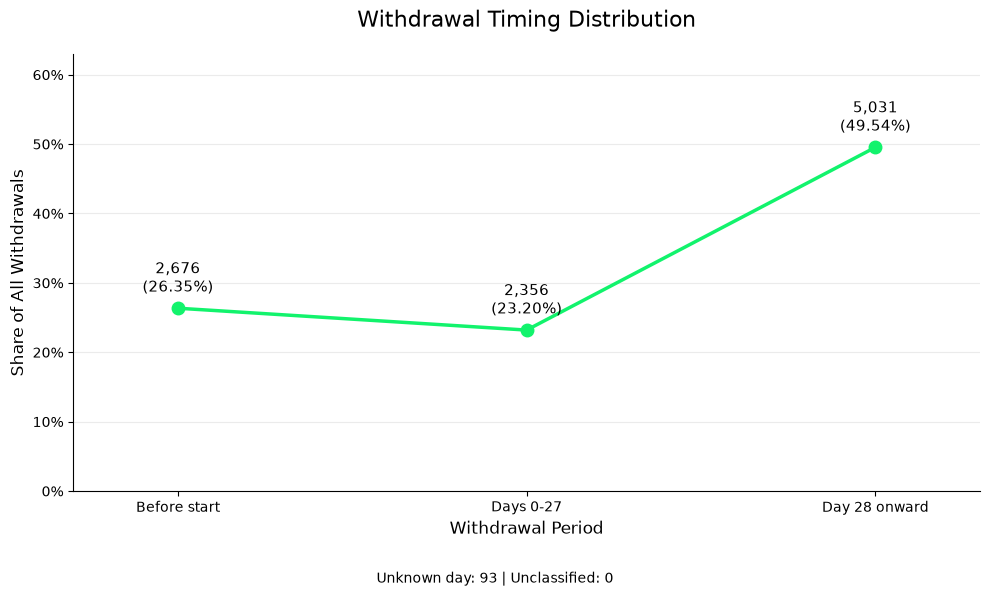

In [34]:
from matplotlib.ticker import PercentFormatter

timing_order = [
    "Before start",
    "Days 0-27",
    "Day 28 onward"
]

plot_data = (
    withdrawal_timing
    .set_index("WithdrawalTiming")
    .reindex(timing_order)
)

fig, ax = plt.subplots(figsize=(10, 6))

ax.plot(
    plot_data.index,
    plot_data["ShareOfWithdrawalsPct"],
    marker="o",
    markersize=9,
    linewidth=2.5,
    color="#12F36C"
)

# عرض العدد والنسبة عند كل نقطة
for position, row in enumerate(plot_data.itertuples()):
    ax.annotate(
        f"{row.WithdrawnEnrollments:,.0f}\n"
        f"({row.ShareOfWithdrawalsPct:.2f}%)",
        xy=(position, row.ShareOfWithdrawalsPct),
        xytext=(0, 12),
        textcoords="offset points",
        ha="center",
        fontsize=11
    )

# الفئات التي ليس لها موضع زمني
other_counts = (
    withdrawal_timing
    .set_index("WithdrawalTiming")["WithdrawnEnrollments"]
)

unknown_count = other_counts.get("Unknown day", 0)
unclassified_count = other_counts.get("Unclassified", 0)

fig.text(
    0.5, 0.02,
    f"Unknown day: {unknown_count:,.0f} | "
    f"Unclassified: {unclassified_count:,.0f}",
    ha="center",
    fontsize=10
)

ax.set_title("Withdrawal Timing Distribution", fontsize=16, pad=20)
ax.set_xlabel("Withdrawal Period", fontsize=12)
ax.set_ylabel("Share of All Withdrawals", fontsize=12)

ax.yaxis.set_major_formatter(PercentFormatter(xmax=100))
ax.set_ylim(
    0,
    plot_data["ShareOfWithdrawalsPct"].max() * 1.25 + 1
)
ax.margins(x=0.15)

ax.set_axisbelow(True)
ax.grid(axis="y", alpha=0.25)
ax.spines[["top", "right"]].set_visible(False)

plt.tight_layout(rect=[0, 0.07, 1, 1])
plt.show()

CCC has the highest withdrawal rate, while FFF has the largest withdrawal count. Both measures matter when prioritizing follow-up: the rate indicates how widespread withdrawal is within a module, while the count indicates the volume of cases.

Withdrawals during the first month account for approximately one-quarter of all withdrawals, even though the remaining course period is much longer.

**Pre-start withdrawal as a percentage of all enrollments, and first-four-week withdrawal among enrollments eligible at the start**

In [35]:
registration = df_analysis["RegistrationDay"]
unregistration = df_analysis["UnregistrationDay"]
is_withdrawn = df_analysis["IsWithdrawnAnalysis"]

# Confirmed withdrawals before the course starts.
pre_start_withdrawal = (
    is_withdrawn
    & unregistration.lt(0)
)

# Timing cannot be established for these withdrawn enrollments.
unknown_withdrawal_day = (
    is_withdrawn
    & unregistration.isna()
)

# Enrollments confirmed to be registered at day 0.
# Keep the recorded unregistration day even for non-WITHDRAWN outcomes.
# هيرجع جدول أو سلسلة من نوع Boolean (True أو False) لكل طالب، بحيث تكون القيمة True فقط للطلاب المستوفين لكل شروط الاستمرار والبداية عند اليوم صفر
eligible_at_start = (
    registration.notna()
    & registration.le(0)                     # Less than or Equal
    & (
        unregistration.isna()
        | unregistration.ge(0)               # Greater than or Equal
    )
    & ~unknown_withdrawal_day                # العلامة ~ تعني النفي (NOT)
)

# Early withdrawals among that same eligible population.
early_withdrawal = (
    eligible_at_start
    & is_withdrawn
    & unregistration.between(0, 27, inclusive="both")
)

withdrawal_kpis = pd.DataFrame([
    {
        "KPI": "Pre-start Withdrawal Rate",                  # نسبة الإنسحاب قبل البداية من إجمالى التسجيلات
        "Numerator": int(pre_start_withdrawal.sum()),
        "Denominator": len(df_analysis)
    },
    {
        "KPI": "First 4 Weeks Withdrawal Rate - Known Eligibility",  # نسبة الإنسحاب خلال أول 4 أسابيع من التسجيلات القائمة عند البداية
        "Numerator": int(early_withdrawal.sum()),
        "Denominator": int(eligible_at_start.sum())
    }
])

withdrawal_kpis["RatePct"] = [
    percentage(n, d)                     # دالة من خطوة سابقة
    for n, d in zip(
        withdrawal_kpis["Numerator"],
        withdrawal_kpis["Denominator"]
    )
]

print(
    withdrawal_kpis.to_string(
        index=False,
        float_format="{:.2f}".format
    )
)

print(
    "\nMissing registration day:",
    int(registration.isna().sum())
)

print(
    "Withdrawn with unknown withdrawal day:",
    int(unknown_withdrawal_day.sum())
)

                                              KPI  Numerator  Denominator  RatePct
                        Pre-start Withdrawal Rate       2676        32593     8.21
First 4 Weeks Withdrawal Rate - Known Eligibility       2343        29580     7.92

Missing registration day: 45
Withdrawn with unknown withdrawal day: 93


The difference between the 2,356 withdrawals in the timing summary and the 2,343 counted here consists of 13 enrollments that did not meet the day 0 eligibility criteria. Their exclusion reasons should not be assumed without reviewing the records.

Both 23.20% and 7.92% are valid, but they use different denominators:

- **23.20%:** withdrawals during days 0–27 as a share of all withdrawals.
- **7.92%:** the withdrawal rate during days 0–27 among enrollments eligible at the start.

There are 45 enrollments with a missing registration day and 93 withdrawals with a missing withdrawal day. The second indicator therefore applies to enrollments with known eligibility. These counts should not be added as if they represented distinct cases, because they may overlap.

In [36]:
#   مراجعة التسجيلات الـ13 لتوثيق سبب الفرق قبل الانتقال لتحليل التفاعل
# All withdrawals during days 0–27, regardless of eligibility at day 0.
all_early_withdrawals = (
    is_withdrawn
    & unregistration.between(0, 27, inclusive="both")
)

excluded_early = df_analysis.loc[
    all_early_withdrawals & ~eligible_at_start,
    [
        "EnrollmentID",
        "StudentID",
        "CourseOfferingCode",
        "RegistrationDay",
        "UnregistrationDay"
    ]
].copy()

excluded_early["ExclusionReason"] = np.select(
    [
        excluded_early["RegistrationDay"].isna(),
        excluded_early["RegistrationDay"].gt(0)
    ],
    [
        "Missing registration day",
        "Registered after day 0"
    ],
    default="Review required"
)

print(excluded_early.to_string(index=False))

print(
    "\n",
    excluded_early["ExclusionReason"].value_counts()
)

 EnrollmentID  StudentID CourseOfferingCode  RegistrationDay  UnregistrationDay          ExclusionReason
         1580     547267             B2013B              9.0               27.0   Registered after day 0
         5894     636807             B2014J             16.0               17.0   Registered after day 0
         7164     695035             B2014J             16.0               24.0   Registered after day 0
         7165     695125             B2014J             17.0               25.0   Registered after day 0
         7801     694329             B2014J             16.0               25.0   Registered after day 0
         7821     699875             B2014J             13.0               25.0   Registered after day 0
        12749    2716795             D2014J              NaN                5.0 Missing registration day
        17604     604632             D2014J              NaN               12.0 Missing registration day
        18163    2702660             F2014J            

##### Do success, failure and withdrawal rates differ between lower and higher study loads?

**Prepare the data and inspect the distribution of studied credits**

In [37]:
# نسخة مستقلة لتحليل العبء الدراسي
df_workload = df_analysis[
    ["StudentID", "CourseOfferingCode", "StudiedCredits", "Outcome"]
].copy()

df_workload["StudiedCredits"] = pd.to_numeric(
    df_workload["StudiedCredits"],
    errors="coerce"
)

df_workload["Outcome"] = (
    df_workload["Outcome"]
    .astype("string")
    .str.strip()
    .str.upper()
)

# عرض القيم الموجودة وعدد التسجيلات لكل قيمة
credits_distribution = (
    df_workload["StudiedCredits"]
    .value_counts(dropna=False)
    .sort_index()
    .rename_axis("StudiedCredits")
    .reset_index(name="EnrollmentCount")
)

display(credits_distribution)

print(
    "Missing or non-positive credits:",
    (
        df_workload["StudiedCredits"].isna()
        | df_workload["StudiedCredits"].le(0)
    ).sum()
)

,StudiedCredits,EnrollmentCount
0,30,3749
1,40,22
2,45,36
3,50,7
4,55,3
...,...,...
56,480,1
57,540,1
58,585,1
59,630,1


Missing or non-positive credits: 0


**Define workload bands and calculate outcome rates**

In [38]:
# استبعاد الوحدات المفقودة أو غير الموجبة من المقارنة
df_workload_valid = df_workload.loc[
    df_workload["StudiedCredits"].gt(0)
].copy()

df_workload_valid["WorkloadBand"] = pd.cut(
    df_workload_valid["StudiedCredits"],
    bins=[0, 60, 120, np.inf],
    labels=["1–60 credits", "61–120 credits", ">120 credits"]
)

# النجاح يشمل PASS + DISTINCTION
df_workload_valid["IsSuccess"] = (
    df_workload_valid["Outcome"]
    .isin(["PASS", "DISTINCTION"])
)

df_workload_valid["IsFail"] = (
    df_workload_valid["Outcome"].eq("FAIL").fillna(False)
)

df_workload_valid["IsWithdrawn"] = (
    df_workload_valid["Outcome"].eq("WITHDRAWN").fillna(False)
)

df_workload_valid["IsKnownOutcome"] = (
    df_workload_valid["Outcome"]
    .isin(["PASS", "DISTINCTION", "FAIL", "WITHDRAWN"])
)

workload_summary = (
    df_workload_valid
    .groupby("WorkloadBand", observed=False)
    .agg(
        EnrollmentCount=("StudentID", "size"),
        KnownOutcomeCount=("IsKnownOutcome", "sum"),
        SuccessCount=("IsSuccess", "sum"),
        FailCount=("IsFail", "sum"),
        WithdrawnCount=("IsWithdrawn", "sum")
    )
)

workload_summary["UnknownOutcomeCount"] = (
    workload_summary["EnrollmentCount"]
    - workload_summary["KnownOutcomeCount"]
)

# مقام النسب: التسجيلات ذات النتيجة المعروفة داخل كل فئة
denominator = workload_summary["KnownOutcomeCount"].replace(0, np.nan)

for count_column, rate_column in [
    ("SuccessCount", "SuccessRatePct"),
    ("FailCount", "FailRatePct"),
    ("WithdrawnCount", "WithdrawalRatePct")
]:
    workload_summary[rate_column] = (
        workload_summary[count_column]
        .div(denominator)
        .mul(100)
    )

display(workload_summary.round(2))

,EnrollmentCount,KnownOutcomeCount,SuccessCount,FailCount,WithdrawnCount,UnknownOutcomeCount,SuccessRatePct,FailRatePct,WithdrawalRatePct
WorkloadBand,,,,,,,,,
1–60 credits,20568,20568,10654,4700,5214,0,51.80,22.85,25.35
61–120 credits,9769,9769,4046,1938,3785,0,41.42,19.84,38.75
>120 credits,2256,2256,685,414,1157,0,30.36,18.35,51.29


**Plot outcome rates by study load**

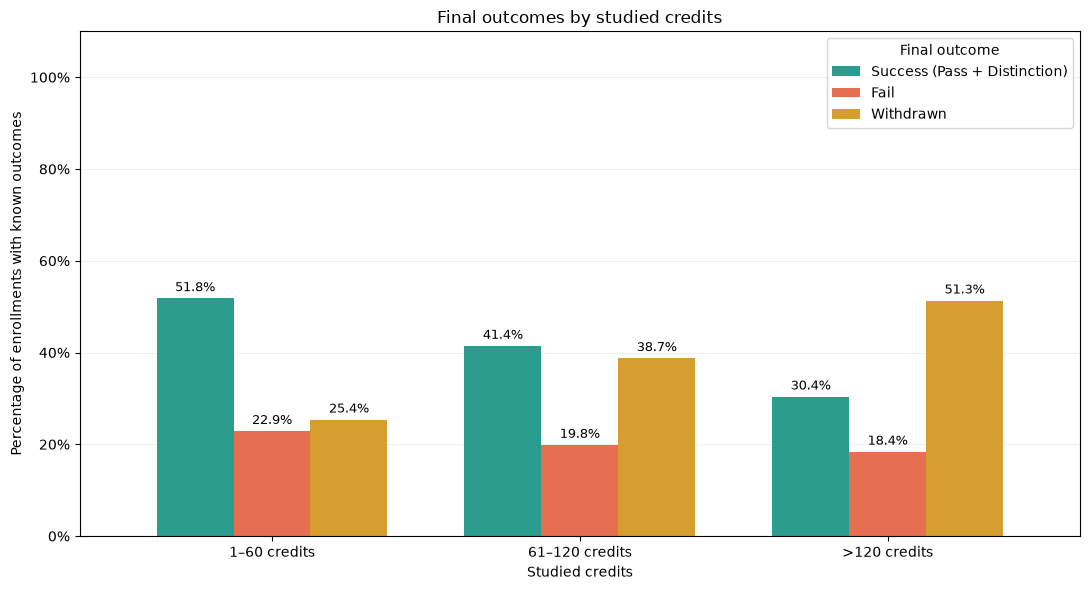

In [39]:
plot_data = workload_summary[
    ["SuccessRatePct", "FailRatePct", "WithdrawalRatePct"]
].rename(columns={
    "SuccessRatePct": "Success (Pass + Distinction)",
    "FailRatePct": "Fail",
    "WithdrawalRatePct": "Withdrawn"
})

ax = plot_data.plot(
    kind="bar",
    figsize=(11, 6),
    color=["#2A9D8F", "#E76F51", "#D69E2E"],
    width=0.75,
    rot=0
)

for container in ax.containers:
    ax.bar_label(
        container,
        fmt="%.1f%%",
        padding=3,
        fontsize=9
    )

ax.set_title("Final outcomes by studied credits")
ax.set_xlabel("Studied credits")
ax.set_ylabel("Percentage of enrollments with known outcomes")

ax.set_ylim(0, 110)
ax.yaxis.set_major_formatter(
    plt.FuncFormatter(lambda value, _: f"{value:.0f}%")
)

ax.grid(axis="y", alpha=0.2)
ax.set_axisbelow(True)
ax.legend(title="Final outcome")

plt.tight_layout()
plt.show()

Higher studied credits were associated with lower success and higher withdrawal, with the clearest pattern among enrollments above 120 credits. This supports reviewing study load as part of retention support. However, the comparison does not establish that study load causes withdrawal. The pattern should be examined within each module and presentation, taking previous attempts and student characteristics into account.

**Examine study load and outcomes across modules**

In [40]:
# إضافة المقرر لكل تسجيل
df_workload_module = df_workload_valid.merge(
    df_analysis[
        ["StudentID", "CourseOfferingCode", "ModuleCode"]
    ],
    on=["StudentID", "CourseOfferingCode"],
    how="left",
    validate="one_to_one"
)

assert df_workload_module["ModuleCode"].notna().all(), \
    "توجد تسجيلات لم يتم تحديد المقرر الخاص بها."

# 1) الانسحاب حسب المقرر وفئة العبء الدراسي
workload_by_module = (
    df_workload_module
    .groupby(["ModuleCode", "WorkloadBand"], observed=True)
    .agg(
        EnrollmentCount=("StudentID", "size"),
        KnownOutcomeCount=("IsKnownOutcome", "sum"),
        WithdrawnCount=("IsWithdrawn", "sum")
    )
    .reset_index()
)

# المقام: التسجيلات ذات النتيجة المعروفة داخل المقرر وفئة العبء
workload_by_module["WithdrawalRatePct"] = (
    workload_by_module["WithdrawnCount"]
    .div(
        workload_by_module["KnownOutcomeCount"]
        .replace(0, np.nan)
    )
    .mul(100)
)

display(workload_by_module.round(2))

,ModuleCode,WorkloadBand,EnrollmentCount,KnownOutcomeCount,WithdrawnCount,WithdrawalRatePct
0,AAA,1–60 credits,520,520,69,13.27
1,AAA,61–120 credits,171,171,38,22.22
2,AAA,>120 credits,57,57,19,33.33
3,BBB,1–60 credits,5152,5152,1364,26.48
4,BBB,61–120 credits,2271,2271,794,34.96
5,BBB,>120 credits,486,486,230,47.33
6,CCC,1–60 credits,2622,2622,976,37.22
7,CCC,61–120 credits,1481,1481,791,53.41
8,CCC,>120 credits,331,331,208,62.84
9,DDD,1–60 credits,3638,3638,1040,28.59


**Does withdrawal increase with study load within the same module?**

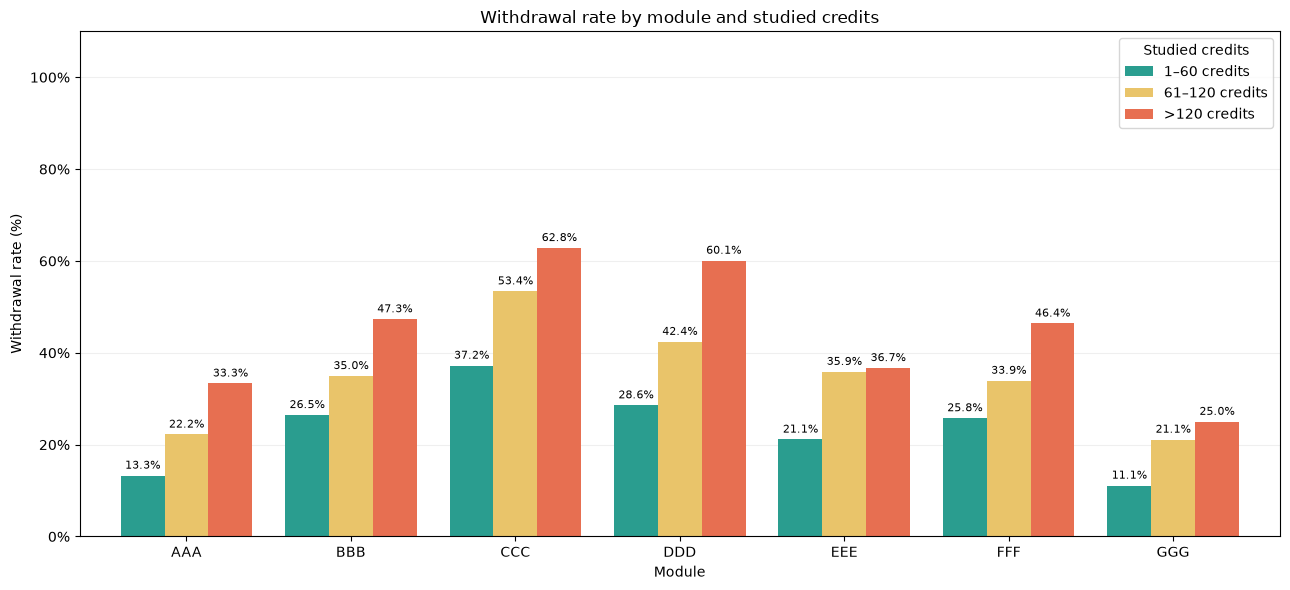

In [41]:
withdrawal_matrix = workload_by_module.pivot(
    index="ModuleCode",
    columns="WorkloadBand",
    values="WithdrawalRatePct"
)

ax = withdrawal_matrix.plot(
    kind="bar",
    figsize=(13, 6),
    color=["#2A9D8F", "#E9C46A", "#E76F51"],
    width=0.8,
    rot=0
)

for container in ax.containers:
    ax.bar_label(
        container,
        labels=[
            f"{bar.get_height():.1f}%"
            if np.isfinite(bar.get_height()) else ""
            for bar in container
        ],
        padding=3,
        fontsize=8
    )

ax.set_title("Withdrawal rate by module and studied credits")
ax.set_xlabel("Module")
ax.set_ylabel("Withdrawal rate (%)")
ax.set_ylim(0, 110)

ax.yaxis.set_major_formatter(
    plt.FuncFormatter(lambda value, _: f"{value:.0f}%")
)

ax.legend(title="Studied credits")
ax.grid(axis="y", alpha=0.2)
ax.set_axisbelow(True)

plt.tight_layout()
plt.show()

**Do modules with higher withdrawal rates have a larger share of enrollments above 120 credits?**

In [42]:
module_workload_profile = (
    df_workload_module
    .assign(
        Above120Credits=lambda x: x["StudiedCredits"].gt(120)
    )
    .groupby("ModuleCode")
    .agg(
        EnrollmentCount=("StudentID", "size"),
        KnownOutcomeCount=("IsKnownOutcome", "sum"),
        WithdrawnCount=("IsWithdrawn", "sum"),
        Above120Count=("Above120Credits", "sum"),
        MedianCredits=("StudiedCredits", "median")
    )
)

module_workload_profile["WithdrawalRatePct"] = (
    module_workload_profile["WithdrawnCount"]
    .div(
        module_workload_profile["KnownOutcomeCount"]
        .replace(0, np.nan)
    )
    .mul(100)
)

module_workload_profile["Above120SharePct"] = (
    module_workload_profile["Above120Count"]
    .div(module_workload_profile["EnrollmentCount"])
    .mul(100)
)

display(
    module_workload_profile
    .sort_values("WithdrawalRatePct", ascending=False)
    .round(2)
)

,EnrollmentCount,KnownOutcomeCount,WithdrawnCount,Above120Count,MedianCredits,WithdrawalRatePct,Above120SharePct
ModuleCode,,,,,,,
CCC,4434,4434,1975,331,60.0,44.54,7.47
DDD,6272,6272,2250,526,60.0,35.87,8.39
FFF,7762,7762,2403,735,60.0,30.96,9.47
BBB,7909,7909,2388,486,60.0,30.19,6.14
EEE,2934,2934,722,109,60.0,24.61,3.72
AAA,748,748,126,57,60.0,16.84,7.62
GGG,2534,2534,292,12,30.0,11.52,0.47


Higher study load was associated with higher withdrawal within all seven modules, so the pattern remained after separating enrollments by module. DDD had the largest difference between workload bands, while CCC had the highest withdrawal rate in every band. These findings support considering study load when prioritizing support, particularly in CCC and DDD. They do not establish causality, as presentation, previous attempts and student characteristics may also contribute to the differences.

##### Do enrollments with previous attempts have different outcomes from first attempts?

In [43]:
# تجهيز بيانات المحاولات السابقة
df_attempts = df_analysis[
    ["StudentID", "CourseOfferingCode", "PreviousAttempts", "Outcome"]
].copy()

df_attempts["PreviousAttempts"] = pd.to_numeric(
    df_attempts["PreviousAttempts"],
    errors="coerce"
)

df_attempts["Outcome"] = (
    df_attempts["Outcome"]
    .astype("string")
    .str.strip()
    .str.upper()
)

# العدد يجب أن يكون صحيحًا وغير سالب
valid_attempts = (
    df_attempts["PreviousAttempts"].notna()
    & df_attempts["PreviousAttempts"].ge(0)
    & df_attempts["PreviousAttempts"].mod(1).eq(0)
)

print("Excluded invalid / missing attempts:", (~valid_attempts).sum())

df_attempts = df_attempts.loc[valid_attempts].copy()

df_attempts["AttemptGroup"] = np.where(
    df_attempts["PreviousAttempts"].eq(0),
    "No previous attempts",
    "With previous attempts"
)

df_attempts["IsSuccess"] = (
    df_attempts["Outcome"].isin(["PASS", "DISTINCTION"])
)

df_attempts["IsFail"] = (
    df_attempts["Outcome"].eq("FAIL").fillna(False)
)

df_attempts["IsWithdrawn"] = (
    df_attempts["Outcome"].eq("WITHDRAWN").fillna(False)
)

df_attempts["IsKnownOutcome"] = (
    df_attempts["Outcome"]
    .isin(["PASS", "DISTINCTION", "FAIL", "WITHDRAWN"])
)

# تلخيص النتائج
attempts_summary = (
    df_attempts
    .groupby("AttemptGroup")
    .agg(
        EnrollmentCount=("StudentID", "size"),
        KnownOutcomeCount=("IsKnownOutcome", "sum"),
        SuccessCount=("IsSuccess", "sum"),
        FailCount=("IsFail", "sum"),
        WithdrawnCount=("IsWithdrawn", "sum")
    )
    .reindex([
        "No previous attempts",
        "With previous attempts"
    ], fill_value=0)
)

attempts_summary["UnknownOutcomeCount"] = (
    attempts_summary["EnrollmentCount"]
    - attempts_summary["KnownOutcomeCount"]
)

# مقام النسب: التسجيلات ذات النتيجة المعروفة داخل كل مجموعة
denominator = attempts_summary["KnownOutcomeCount"].replace(0, np.nan)

for count_column, rate_column in [
    ("SuccessCount", "SuccessRatePct"),
    ("FailCount", "FailRatePct"),
    ("WithdrawnCount", "WithdrawalRatePct")
]:
    attempts_summary[rate_column] = (
        attempts_summary[count_column]
        .div(denominator)
        .mul(100)
    )

display(attempts_summary.round(2))

Excluded invalid / missing attempts: 0


,EnrollmentCount,KnownOutcomeCount,SuccessCount,FailCount,WithdrawnCount,UnknownOutcomeCount,SuccessRatePct,FailRatePct,WithdrawalRatePct
AttemptGroup,,,,,,,,,
No previous attempts,28421,28421,14005,5731,8685,0,49.28,20.16,30.56
With previous attempts,4172,4172,1380,1321,1471,0,33.08,31.66,35.26


**Plot outcomes by previous-attempt status**

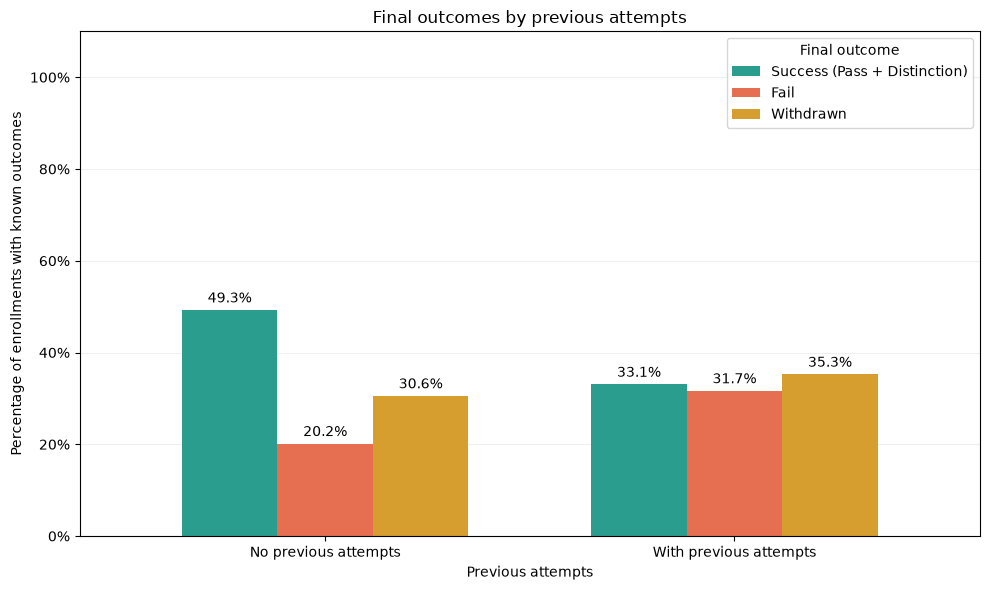

In [44]:
plot_data = attempts_summary[
    ["SuccessRatePct", "FailRatePct", "WithdrawalRatePct"]
].rename(columns={
    "SuccessRatePct": "Success (Pass + Distinction)",
    "FailRatePct": "Fail",
    "WithdrawalRatePct": "Withdrawn"
})

ax = plot_data.plot(
    kind="bar",
    figsize=(10, 6),
    color=["#2A9D8F", "#E76F51", "#D69E2E"],
    width=0.7,
    rot=0
)

for container in ax.containers:
    ax.bar_label(container, fmt="%.1f%%", padding=3)

ax.set_title("Final outcomes by previous attempts")
ax.set_xlabel("Previous attempts")
ax.set_ylabel("Percentage of enrollments with known outcomes")
ax.set_ylim(0, 110)

ax.yaxis.set_major_formatter(
    plt.FuncFormatter(lambda value, _: f"{value:.0f}%")
)

ax.legend(title="Final outcome")
ax.grid(axis="y", alpha=0.2)
ax.set_axisbelow(True)

plt.tight_layout()
plt.show()

Enrollments with previous attempts at the module had less favorable outcomes: success was 33.08%, compared with 49.28% among enrollments without previous attempts, alongside higher failure and withdrawal. These findings support reviewing the academic support needs of students repeating a module. The comparison remains descriptive; it does not establish that repeat attempts cause difficulty. The differences should be examined within modules and across study loads.

##### Do outcomes differ between 2013 and 2014, and between B and J presentations within the same module?

**Extract the presentation year and term, then calculate outcomes**

In [45]:
# نسخة مستقلة للتحليل
df_presentations = df_analysis[
    ["StudentID", "CourseOfferingCode",
     "ModuleCode", "PresentationCode", "Outcome"]
].copy()

df_presentations["PresentationCode"] = (
    df_presentations["PresentationCode"]
    .astype("string")
    .str.strip()
    .str.upper()
)

# مثال: 2013J → Year = 2013, Term = J
presentation_parts = (
    df_presentations["PresentationCode"]
    .str.extract(r"^(?P<Year>\d{4})(?P<Term>[BJ])$")
)

df_presentations["Year"] = presentation_parts["Year"].astype("Int64")
df_presentations["Term"] = presentation_parts["Term"]

invalid_codes = df_presentations["Year"].isna()

if invalid_codes.any():
    display(
        df_presentations.loc[
            invalid_codes, ["PresentationCode"]
        ].drop_duplicates()
    )
    raise ValueError("راجع أكواد التقديم غير الصالحة قبل التحليل.")

df_presentations["Outcome"] = (
    df_presentations["Outcome"]
    .astype("string")
    .str.strip()
    .str.upper()
)

df_presentations["IsSuccess"] = (
    df_presentations["Outcome"].isin(["PASS", "DISTINCTION"])
)

df_presentations["IsFail"] = (
    df_presentations["Outcome"].eq("FAIL").fillna(False)
)

df_presentations["IsWithdrawn"] = (
    df_presentations["Outcome"].eq("WITHDRAWN").fillna(False)
)

df_presentations["IsKnownOutcome"] = (
    df_presentations["Outcome"]
    .isin(["PASS", "DISTINCTION", "FAIL", "WITHDRAWN"])
)

presentation_summary = (
    df_presentations
    .groupby(["ModuleCode", "Year", "Term"], as_index=False)
    .agg(
        EnrollmentCount=("StudentID", "size"),
        KnownOutcomeCount=("IsKnownOutcome", "sum"),
        SuccessCount=("IsSuccess", "sum"),
        FailCount=("IsFail", "sum"),
        WithdrawnCount=("IsWithdrawn", "sum")
    )
)

presentation_summary["UnknownOutcomeCount"] = (
    presentation_summary["EnrollmentCount"]
    - presentation_summary["KnownOutcomeCount"]
)

# المقام: التسجيلات ذات النتيجة المعروفة داخل كل تقديم
denominator = (
    presentation_summary["KnownOutcomeCount"].replace(0, np.nan)
)

for count_column, rate_column in [
    ("SuccessCount", "SuccessRatePct"),
    ("FailCount", "FailRatePct"),
    ("WithdrawnCount", "WithdrawalRatePct")
]:
    presentation_summary[rate_column] = (
        presentation_summary[count_column]
        .div(denominator)
        .mul(100)
    )

display(presentation_summary.round(2))

,ModuleCode,Year,Term,EnrollmentCount,KnownOutcomeCount,SuccessCount,FailCount,WithdrawnCount,UnknownOutcomeCount,SuccessRatePct,FailRatePct,WithdrawalRatePct
0,AAA,2013,J,383,383,278,45,60,0,72.58,11.75,15.67
1,AAA,2014,J,365,365,253,46,66,0,69.32,12.6,18.08
2,BBB,2013,B,1767,1767,803,459,505,0,45.44,25.98,28.58
3,BBB,2013,J,2237,2237,1072,521,644,0,47.92,23.29,28.79
4,BBB,2014,B,1613,1613,727,396,490,0,45.07,24.55,30.38
5,BBB,2014,J,2292,2292,1152,391,749,0,50.26,17.06,32.68
6,CCC,2014,B,1936,1936,663,375,898,0,34.25,19.37,46.38
7,CCC,2014,J,2498,2498,1015,406,1077,0,40.63,16.25,43.11
8,DDD,2013,B,1303,1303,510,361,432,0,39.14,27.71,33.15
9,DDD,2013,J,1938,1938,829,428,681,0,42.78,22.08,35.14


**Compare 2013 with 2014**

In [46]:
comparison_columns = [
    "EnrollmentCount",
    "SuccessRatePct",
    "FailRatePct",
    "WithdrawalRatePct"
]

year_2013 = presentation_summary.loc[
    presentation_summary["Year"].eq(2013),
    ["ModuleCode", "Term", *comparison_columns]
]

year_2014 = presentation_summary.loc[
    presentation_summary["Year"].eq(2014),
    ["ModuleCode", "Term", *comparison_columns]
]

# المقارنة تشمل التقديمات الموجودة في السنتين فقط
year_comparison = year_2013.merge(
    year_2014,
    on=["ModuleCode", "Term"],
    how="inner",
    suffixes=("_2013", "_2014"),
    validate="one_to_one"
)

for metric, difference in [
    ("SuccessRatePct", "SuccessChangePP"),
    ("FailRatePct", "FailChangePP"),
    ("WithdrawalRatePct", "WithdrawalChangePP")
]:
    year_comparison[difference] = (
        year_comparison[f"{metric}_2014"]
        - year_comparison[f"{metric}_2013"]
    )

display(year_comparison.round(2))

,ModuleCode,Term,EnrollmentCount_2013,SuccessRatePct_2013,FailRatePct_2013,WithdrawalRatePct_2013,EnrollmentCount_2014,SuccessRatePct_2014,FailRatePct_2014,WithdrawalRatePct_2014,SuccessChangePP,FailChangePP,WithdrawalChangePP
0,AAA,J,383,72.58,11.75,15.67,365,69.32,12.6,18.08,-3.27,0.85,2.42
1,BBB,B,1767,45.44,25.98,28.58,1613,45.07,24.55,30.38,-0.37,-1.43,1.8
2,BBB,J,2237,47.92,23.29,28.79,2292,50.26,17.06,32.68,2.34,-6.23,3.89
3,DDD,B,1303,39.14,27.71,33.15,1228,39.01,21.09,39.9,-0.13,-6.61,6.75
4,DDD,J,1938,42.78,22.08,35.14,1803,43.93,20.19,35.88,1.15,-1.9,0.75
5,EEE,J,1052,57.89,19.01,23.1,1188,57.58,16.67,25.76,-0.31,-2.34,2.66
6,FFF,B,1614,48.45,26.08,25.46,1500,43.60,25.6,30.8,-4.85,-0.48,5.34
7,FFF,J,2283,47.96,22.47,29.57,2365,47.23,16.62,36.15,-0.73,-5.85,6.59
8,GGG,J,952,62.18,30.88,6.93,749,59.28,23.9,16.82,-2.91,-6.98,9.89


**Compare J with B within the same module and year**

In [47]:
term_b = presentation_summary.loc[
    presentation_summary["Term"].eq("B"),
    ["ModuleCode", "Year", *comparison_columns]
]

term_j = presentation_summary.loc[
    presentation_summary["Term"].eq("J"),
    ["ModuleCode", "Year", *comparison_columns]
]

# المقارنة تشمل المقررات التي لديها B وJ في السنة نفسها
term_comparison = term_b.merge(
    term_j,
    on=["ModuleCode", "Year"],
    how="inner",
    suffixes=("_B", "_J"),
    validate="one_to_one"
)

for metric, difference in [
    ("SuccessRatePct", "SuccessChangePP"),
    ("FailRatePct", "FailChangePP"),
    ("WithdrawalRatePct", "WithdrawalChangePP")
]:
    term_comparison[difference] = (
        term_comparison[f"{metric}_J"]
        - term_comparison[f"{metric}_B"]
    )

display(term_comparison.round(2))

,ModuleCode,Year,EnrollmentCount_B,SuccessRatePct_B,FailRatePct_B,WithdrawalRatePct_B,EnrollmentCount_J,SuccessRatePct_J,FailRatePct_J,WithdrawalRatePct_J,SuccessChangePP,FailChangePP,WithdrawalChangePP
0,BBB,2013,1767,45.44,25.98,28.58,2237,47.92,23.29,28.79,2.48,-2.69,0.21
1,BBB,2014,1613,45.07,24.55,30.38,2292,50.26,17.06,32.68,5.19,-7.49,2.3
2,CCC,2014,1936,34.25,19.37,46.38,2498,40.63,16.25,43.11,6.39,-3.12,-3.27
3,DDD,2013,1303,39.14,27.71,33.15,1938,42.78,22.08,35.14,3.64,-5.62,1.99
4,DDD,2014,1228,39.01,21.09,39.9,1803,43.93,20.19,35.88,4.92,-0.9,-4.02
5,EEE,2014,694,51.44,23.63,24.93,1188,57.58,16.67,25.76,6.13,-6.96,0.83
6,FFF,2013,1614,48.45,26.08,25.46,2283,47.96,22.47,29.57,-0.49,-3.61,4.1
7,FFF,2014,1500,43.60,25.6,30.8,2365,47.23,16.62,36.15,3.63,-8.98,5.35
8,GGG,2014,833,57.38,30.61,12.0,749,59.28,23.9,16.82,1.90,-6.71,4.82


In every available comparison holding module and presentation term constant, withdrawal was higher in 2014 than in 2013. When comparing terms within the same year, J had lower failure and generally higher success, but did not consistently have lower withdrawal. The assessment of performance therefore depends on the outcome being considered. GGG–2014J, DDD–2014B and the FFF presentations in 2014 warrant further investigation into increased withdrawal.

These descriptive differences do not establish an effect of year or presentation term. Student characteristics, study load and previous attempts may also differ. CCC cannot be compared across years in the current dataset.

### <h3 style="color: yellow; font : bold;">4. Analysis Two: Assessment Submission and Final Outcomes</h3>

##### Build the expected-assessment dataset and determine eligibility at each due date

In [48]:
# كودلمعرفة اسماء الأعمدة فى الجداول
# بسبب عدم وجود courseofferingcode فى dw.DimAssessment
with engine.connect() as connection:
    assessment_columns = pd.read_sql_query(text("""
        SELECT TABLE_SCHEMA, TABLE_NAME,
               COLUMN_NAME, DATA_TYPE
        FROM INFORMATION_SCHEMA.COLUMNS
        WHERE (TABLE_SCHEMA = 'dw'
               AND TABLE_NAME = 'DimAssessment')
           OR (TABLE_SCHEMA = 'ods'
               AND TABLE_NAME = 'Assessment')
        ORDER BY TABLE_SCHEMA, ORDINAL_POSITION
    """), connection)

display(assessment_columns)

,TABLE_SCHEMA,TABLE_NAME,COLUMN_NAME,DATA_TYPE
0,dw,DimAssessment,AssessmentID,int
1,dw,DimAssessment,AssessmentType,nvarchar
2,dw,DimAssessment,AssessmentDay,int
3,dw,DimAssessment,Weight,decimal
4,ods,Assessment,AssessmentID,int
5,ods,Assessment,CourseOfferingCode,nvarchar
6,ods,Assessment,AssessmentType,nvarchar
7,ods,Assessment,AssessmentDay,int
8,ods,Assessment,Weight,decimal


In [49]:
# 1) بيانات التسجيل اللازمة لتحديد أهلية كل تقييم
with engine.connect() as connection:

    enrollment_quality = pd.read_sql_query(text("""
        SELECT
            e.StudentID,
            e.CourseOfferingCode,
            r.FinalResult,
            e.RegistrationDay,
            e.UnregistrationDay,
            c.PresentationLengthDays
        FROM dw.FactEnrollment AS e
        LEFT JOIN dw.DimFinalResult AS r
            ON r.FinalResultKey = e.FinalResultKey
        LEFT JOIN dw.DimCourseOffering AS c
            ON c.CourseOfferingCode = e.CourseOfferingCode
    """), connection)

    # 2) التسليمات المسجلة ومواعيد التقييمات
    assessment_quality = pd.read_sql_query(text("""
        SELECT
            f.StudentAssessmentID,
            f.StudentID,
            f.CourseOfferingCode,
            f.AssessmentID,
            f.SubmittedDay,
            f.IsBanked,
            f.Score,
            a.AssessmentDay,
            c.PresentationLengthDays
        FROM dw.FactStudentAssessment AS f
        LEFT JOIN dw.DimAssessment AS a
            ON a.AssessmentID = f.AssessmentID
        LEFT JOIN dw.DimCourseOffering AS c
            ON c.CourseOfferingCode = f.CourseOfferingCode
    """), connection)

# التأكد من عدم تضاعف الصفوف بعد الربط
assert not enrollment_quality.duplicated(
    ["StudentID", "CourseOfferingCode"]
).any(), "يوجد تكرار في تسجيلات الطلاب"

assert assessment_quality["StudentAssessmentID"].is_unique, \
    "يوجد تكرار في سجلات التسليم"

assert not assessment_quality.duplicated(
    ["StudentID", "CourseOfferingCode", "AssessmentID"]
).any(), "يوجد أكثر من سجل لنفس الطالب والتقييم"

# 3) إعادة تجهيز صلاحية توقيت التسليم داخل هذا الملف
q = assessment_quality

submitted = q["SubmittedDay"]
due = q["AssessmentDay"]
length = q["PresentationLengthDays"]

q["CanUseSubmissionDelay"] = (
    q["IsBanked"].eq(0)
    & length.notna()
    & length.gt(0)
    & submitted.notna()
    & submitted.le(length)
    & due.notna()
    & due.ge(0)
    & due.le(length)
)

# موجب = متأخر، صفر = في الموعد، سالب = مبكر
q["SubmissionDelayDays"] = (
    submitted - due
).where(q["CanUseSubmissionDelay"])

print("عدد التسجيلات:", len(enrollment_quality))
print("عدد سجلات التسليم:", len(assessment_quality))

عدد التسجيلات: 32593
عدد سجلات التسليم: 173912


In [50]:
# 1) جميع تقييمات TMA وCMA مع تقديم المقرر
with engine.connect() as connection:
    assessment_catalog = pd.read_sql_query(text("""             
        SELECT
            a.AssessmentID,
            o.CourseOfferingCode,
            a.AssessmentType,
            a.AssessmentDay,
            a.Weight
        FROM dw.DimAssessment AS a
        LEFT JOIN ods.Assessment AS o
            ON o.AssessmentID = a.AssessmentID
        WHERE a.AssessmentType IN ('TMA', 'CMA')
    """), connection)

assert assessment_catalog["AssessmentID"].is_unique
assert assessment_catalog["CourseOfferingCode"].notna().all()
# assessment_catalog = 182 rows

# 2) إنشاء صف لكل تسجيل × تقييم في نفس تقديم المقرر
expected_assessments = enrollment_quality.merge(
    assessment_catalog,
    on="CourseOfferingCode",
    how="inner",
    validate="many_to_many"
)

pair_key = ["StudentID", "CourseOfferingCode", "AssessmentID"]   # للتأكد أن كل طالب في كل تقديم له صف واحد فقط لكل تقييم

assert not expected_assessments.duplicated(pair_key).any()
# expected_assessments = 286,898 rows

# 3) إضافة سجلات التسليم
submission_columns = pair_key + [
    "StudentAssessmentID", "IsBanked", "Score",
    "SubmittedDay", "CanUseSubmissionDelay",
    "SubmissionDelayDays"
]

expected_assessments = expected_assessments.merge(
    assessment_quality[submission_columns],
    on=pair_key,
    how="left",
    validate="one_to_one",
    indicator="SubmissionMatch"
)

q = expected_assessments

q["HasSubmissionRecord"] = q["SubmissionMatch"].eq("both")

# 4) تحديد أهلية التسجيل عند موعد التقييم
# الأهلية لا تعني أنه سلّم؛ معناها أن التقييم يدخل ضمن التقييمات المتوقعة منه زمنيًا، ثم نفحص حالة التسليم في خطوة مستقل
reg = q["RegistrationDay"]
unreg = q["UnregistrationDay"]
due = q["AssessmentDay"]
length = q["PresentationLengthDays"]
withdrawn = q["FinalResult"].eq("WITHDRAWN")

invalid_timing = (
    length.isna() | length.le(0)                             # مدة المقرر مفقودة - المدة صفر أو أقل
    | reg.isna() | reg.gt(length)                            # يوم التسجيل مفقود - التسجيل بعد نهاية التقديم
    | due.isna() | due.lt(0) | due.gt(length)                # موعد التقييم مفقود - موعد التقييم قبل البداية؛ نستبعده من تقرير الأهلية وفق سياستنا الحالية
    | (unreg.notna() & (unreg.lt(reg) | unreg.gt(length)))   # موعد التقييم بعد نهاية التقديم - يوجد يوم انسحاب، لكنه قبل التسجيل أو بعد نهاية التقديم
)

uncertain_enrollment = (                                     # في الحالات دي نتعامل بتحفّظ: لا نحسم الأهلية قبل مراجعة البيانات
    q["FinalResult"].isna()
    | q["FinalResult"].eq("UNKNOWN")                         # النتيجة النهائية مفقودة أو UNKNOWN
    | (withdrawn & unreg.isna())                             # الطالب مسجّل كمنسحب، لكن يوم الانسحاب مفقود
    | (~withdrawn & unreg.notna())                           # النتيجة ليست انسحابًا، ومع ذلك يوجد يوم انسحاب
)

q["EligibilityStatus"] = np.select(                          # فحص الشروط بالترتيب ويختار أول شرط متحقق
    [
        invalid_timing | uncertain_enrollment,               
        due.lt(reg),                
        withdrawn & unreg.lt(due),           
        withdrawn & unreg.eq(due)                            
    ],
    [
        "Unknown - timing or enrollment quality",            # أهلية غير محسومة بسبب جودة البيانات 
        "Not eligible - due before registration",            # غير مؤهل: موعد التقييم قبل تسجيل الطالب
        "Not eligible - withdrawn before due",               # غير مؤهل: انسحب قبل موعد التقييم
        "Unknown - withdrawal on due day"                    # غير محسوم: الانسحاب في نفس يوم الموعد
    ],
    default="Eligible"                                       # مؤهل
)

# 5) فصل التسليم الحالي عن المرحّل وغياب السجل
q["RecordStatus"] = np.select(                               # تحديد حالة سجل التسليم بشكل مستقل
    [
        ~q["HasSubmissionRecord"],                           # لا يوجد سجل مطابق - علامة ~ تعكس الشرط
        q["IsBanked"].eq(1),                                 # يوجد سجل مرحل
        q["IsBanked"].eq(0)                                  # يوجد سجل غير مرحل
    ],
    [
        "No submission record",                              
        "Banked",
        "Current submission"
    ],
    default="Unknown IsBanked"
)

# 6) إنشاء الملخص وعرضه
eligibility_summary = pd.crosstab(                          # يعدّ الصفوف لكل تقاطع بين: - الصفوف: حالة الأهلية - - الأعمدة: حالة التسليم.
    q["EligibilityStatus"],
    q["RecordStatus"],
    margins=True,
    margins_name="Total"
)

display(eligibility_summary)

RecordStatus,Banked,Current submission,No submission record,Total
EligibilityStatus,,,,
Eligible,1741,165413,49214,216368
Not eligible - due before registration,29,10,21,60
Not eligible - withdrawn before due,132,1524,67154,68810
Unknown - timing or enrollment quality,6,66,1212,1284
Unknown - withdrawal on due day,1,31,344,376
Total,1909,167044,117945,286898


| Indicator | Value |
|---|---:|
| Eligible assessment opportunities | 216,368 |
| Eligible banked assessments, excluded from current submission requirements | 1,741 |
| Assessment opportunities eligible for current submission | **214,627** |
| With a current submission record | 165,413 |
| Without a submission record | 49,214 |
| **Current submission rate** | **77.07%** |
| **Share without a submission record** | **22.93%** |

##### Assess on-time submission and delays among eligible assessments

In [51]:
# تصفية التقييمات المؤهلة الحالية
eligible_current = expected_assessments.loc[
    expected_assessments["EligibilityStatus"].eq("Eligible")
    & expected_assessments["RecordStatus"].eq("Current submission")
].copy()

# تصفية التقييمات ذات التوقيت الصالح
timed_submissions = eligible_current.loc[
    eligible_current["CanUseSubmissionDelay"].eq(True)
].copy()

delay = timed_submissions["SubmissionDelayDays"]

total_current = len(eligible_current)
usable_count = len(timed_submissions)
on_time_count = int(delay.le(0).sum())
late_count = int(delay.gt(0).sum())

# حساب المؤشرات العددية
timing_summary = pd.DataFrame([{
    "EligibleCurrentSubmissions": total_current,             # إجمالي التقييمات المؤهلة الحالية
    "UsableTiming": usable_count,                            # عدد التقييمات اللي قدرنا نحسب لها التوقيت بدقة
    "UnavailableTiming": total_current - usable_count,       # التقييمات اللي ماقدرناش نحسب توقيتها (الفرق بين الإجمالي والمستخدَم)
    "OnTimeOrEarly": on_time_count,                          # عدد الطلاب اللي سلموا في الموعد أو قبل الموعد
    "Late": late_count,                                      # عدد الطلاب اللي سلموا متأخرين

    "OnTimePct": (
        round(on_time_count / usable_count * 100, 2)
        if usable_count else np.nan
    ),
    "LatePct": (
        round(late_count / usable_count * 100, 2)
        if usable_count else np.nan
    ),

    # بين المتأخرين فقط
    "MedianLateDays": delay.loc[delay.gt(0)].median()       # الوسيط لعدد أيام التأخير بين الطلاب اللي سلموا متأخرين
}])

display(timing_summary)

,EligibleCurrentSubmissions,UsableTiming,UnavailableTiming,OnTimeOrEarly,Late,OnTimePct,LatePct,MedianLateDays
0,165413,165410,3,116388,49022,70.36,29.64,3.0


The current submission rate among eligible assessment opportunities is 77.07%. Among submissions with usable timing, approximately three in ten were late.

##### Submission rates and scores by final outcome

Calculate the indicators for each enrollment first, then summarize them by final outcome. This prevents enrollments with more assessments from receiving greater weight.

In [52]:
# الربط بشكل مباشر بين سلوك الطالب في تسليم التقييمات (نسبة التسليم) ومتوسط درجاته وبين النتيجة النهائية التي حققها في المقرر (Final Result)
# التقييمات المؤهلة للتسليم الحالي؛ استبعاد المرحّل
eligible_required = expected_assessments.loc[
    expected_assessments["EligibilityStatus"].eq("Eligible")
    & expected_assessments["RecordStatus"].isin([
        "Current submission", "No submission record"
    ])       # يختار التقييمات المؤهلة (Eligible) والتي تعتبر مطلوبة كـ "تسليم حالي" أو "ليس لها سجل تسليم"
].copy()

eligible_required["IsSubmitted"] = (                                 # الطالب قام بتسليم هذا التقييم الفعلي أم لا
    eligible_required["RecordStatus"].eq("Current submission")
)

# الدرجة المسجلة للتسليم الحالي فقط؛ المفقود يظل مفقودًا
eligible_required["CurrentScore"] = (                                   # درجة التقييم فقط إذا تم تسليمه فعلياً
    eligible_required["Score"]
    .where(eligible_required["IsSubmitted"])                            
)
# تجميع البيانات على مستوى الطالب والمقرر
# صف واحد لكل تسجيل له تقييم مؤهل واحد على الأقل
enrollment_assessment_summary = (
    eligible_required
    .groupby(
        ["StudentID", "CourseOfferingCode", "FinalResult"],
        as_index=False
    )
    .agg(
        RequiredAssessments=("AssessmentID", "size"),
        SubmittedAssessments=("IsSubmitted", "sum"),
        MeanRecordedScore=("CurrentScore", "mean")
    )
)

enrollment_assessment_summary["SubmissionRatePct"] = (
    enrollment_assessment_summary["SubmittedAssessments"]
    / enrollment_assessment_summary["RequiredAssessments"]
    * 100
)

# مقارنة النتائج النهائية
outcome_summary = (
    enrollment_assessment_summary
    .groupby("FinalResult")
    .agg(
        Enrollments=("StudentID", "size"),
        MeanSubmissionRatePct=("SubmissionRatePct", "mean"),
        MedianSubmissionRatePct=("SubmissionRatePct", "median"),
        EnrollmentsWithScore=("MeanRecordedScore", "count"),
        MeanEnrollmentScore=("MeanRecordedScore", "mean")
    )
    .round(2)
    .reset_index()
)

display(outcome_summary)

,FinalResult,Enrollments,MeanSubmissionRatePct,MedianSubmissionRatePct,EnrollmentsWithScore,MeanEnrollmentScore
0,DISTINCTION,3021,96.68,100.00,3019,88.39
1,FAIL,7029,43.67,33.33,5615,64.32
2,PASS,12351,95.52,100.00,12337,76.50
3,WITHDRAWN,5285,58.17,66.67,4203,63.66


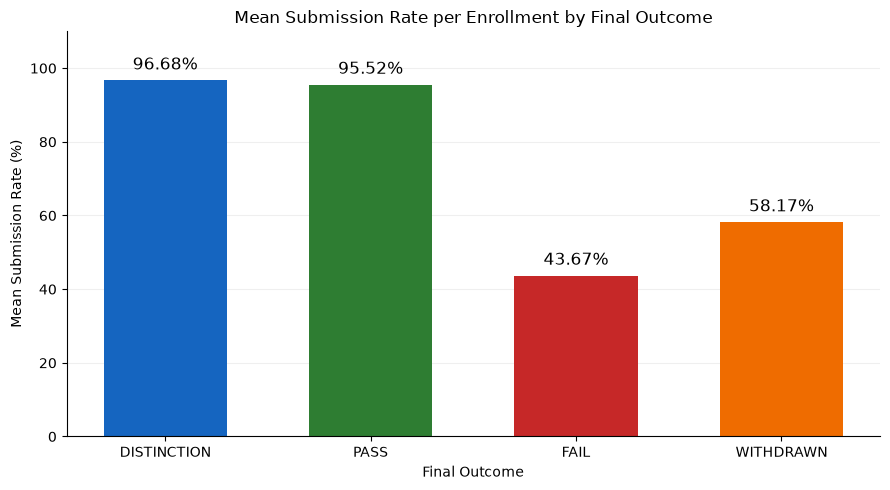

In [53]:
order = ["DISTINCTION", "PASS", "FAIL", "WITHDRAWN"]

plot_data = (
    outcome_summary
    .set_index("FinalResult")
    .reindex(order)
)

fig, ax = plt.subplots(figsize=(9, 5))

bars = ax.bar(
    plot_data.index,
    plot_data["MeanSubmissionRatePct"],
    color=["#1565C0", "#2E7D32", "#C62828", "#EF6C00"],
    width=0.6
)

ax.bar_label(
    bars,
    labels=[
        f"{value:.2f}%"
        for value in plot_data["MeanSubmissionRatePct"]
    ],
    padding=5,
    fontsize=12
)

ax.set_title("Mean Submission Rate per Enrollment by Final Outcome")
ax.set_xlabel("Final Outcome")
ax.set_ylabel("Mean Submission Rate (%)")

ax.set_ylim(0, 110)
ax.set_yticks(range(0, 101, 20))
ax.set_axisbelow(True)
ax.grid(axis="y", alpha=0.2)
ax.spines[["top", "right"]].set_visible(False)

plt.tight_layout()
plt.show()

Findings: Assessment Submission and Final Outcomes

More complete assessment submission and higher scores are associated with pass and distinction, while failed and withdrawn enrollments have lower submission completion.

Missing submissions and low performance are therefore potential indicators of difficulty that warrant follow-up and may help target early academic support.

##### On-time assessment submission by module and final outcome

In [54]:
from IPython.display import display

# 1) بيانات التسجيلات
enrollments = df_analysis[[
    "StudentID",
    "CourseOfferingCode",
    "ModuleCode",
    "Outcome",
    "RegistrationDay",
    "UnregistrationDay",
    "PresentationLengthDays"
]].copy()

enrollments["Outcome"] = (
    enrollments["Outcome"]
    .astype("string")
    .str.strip()
    .str.upper()
    .fillna("UNKNOWN")
)

# 2) التقييمات المطلوبة لكل مقرر وتقديم
# ربط كل تقييم بالمقرر والتقديم من ODS
with engine.connect() as connection:
    assessment_course_map = pd.read_sql_query(
        text("""
            SELECT
                AssessmentID,
                CourseOfferingCode
            FROM ods.Assessment
        """),
        connection
    )

# الاحتفاظ ببيانات التقييم من جدول الـDimension
assessments = (
    tables["DimAssessment"][[
        "AssessmentID",
        "AssessmentDay"
    ]]
    .merge(
        assessment_course_map,
        on="AssessmentID",
        how="left",
        validate="one_to_one"
    )
)

# التأكد من وجود مقرر وتقديم لكل تقييم
if assessments["CourseOfferingCode"].isna().any():
    raise ValueError(
        "Some assessments have no matching course offering in ods.Assessment."
    )

# 3) التسليمات المسجلة
submissions = tables["FactStudentAssessment"][[
    "StudentID",
    "AssessmentID",
    "SubmittedDay",
    "IsBanked"
]].copy()

if enrollments.duplicated(
    ["StudentID", "CourseOfferingCode"]
).any():
    raise ValueError("Duplicate enrollment keys.")

if assessments["AssessmentID"].duplicated().any():
    raise ValueError("Duplicate assessment keys.")

if submissions.duplicated(["StudentID", "AssessmentID"]).any():
    raise ValueError("Duplicate submission keys.")

# شبكة التقييمات المتوقعة، بما فيها التقييمات التي لم تُسلّم
expected = enrollments.merge(
    assessments,
    on="CourseOfferingCode",
    how="inner",
    validate="many_to_many"
)

q_timing = expected.merge(
    submissions,
    on=["StudentID", "AssessmentID"],
    how="left",
    validate="one_to_one",
    indicator="SubmissionMatch"
)

# 4) تجهيز أعمدة التوقيت
numeric_columns = [
    "RegistrationDay",
    "UnregistrationDay",
    "PresentationLengthDays",
    "AssessmentDay",
    "SubmittedDay",
    "IsBanked"
]

for column in numeric_columns:
    q_timing[column] = pd.to_numeric(
        q_timing[column],
        errors="raise"
    )

reg = q_timing["RegistrationDay"]
unreg = q_timing["UnregistrationDay"]
length = q_timing["PresentationLengthDays"]
due = q_timing["AssessmentDay"]
submitted = q_timing["SubmittedDay"]

withdrawn = q_timing["Outcome"].eq("WITHDRAWN")
has_submission = q_timing["SubmissionMatch"].eq("both")

# توقيت تسجيل صالح ومتسق مع النتيجة
valid_enrollment = (
    reg.notna()
    & length.gt(0)
    & reg.le(length)
    & (
        unreg.isna()
        | (unreg.ge(reg) & unreg.le(length))
    )
    & q_timing["Outcome"].isin([
        "PASS", "DISTINCTION", "FAIL", "WITHDRAWN"
    ])
    & (
        (withdrawn & unreg.notna())
        | (~withdrawn & unreg.isna())
    )
)

# التقييم مستحق أثناء فترة تسجيل الطالب
eligible = (
    valid_enrollment
    & due.notna()
    & due.between(0, length)
    & due.ge(reg)
    & (~withdrawn | unreg.gt(due))
)

# نستبعد المنقول، أو التسليم ذي حالة IsBanked غير المعروفة
current_assessment = (
    ~has_submission
    | q_timing["IsBanked"].eq(0)
)

q_timing = q_timing.loc[
    (eligible & current_assessment).fillna(False)
].copy()

# 5) تصنيف توقيت التسليم
has_submission = q_timing["SubmissionMatch"].eq("both")
submitted = q_timing["SubmittedDay"]

valid_submission_day = (
    has_submission
    & submitted.notna()
    & submitted.ge(0)
    & submitted.ge(q_timing["RegistrationDay"])
    & submitted.le(q_timing["PresentationLengthDays"])
    & (
        q_timing["UnregistrationDay"].isna()
        | submitted.lt(q_timing["UnregistrationDay"])
    )
).fillna(False)

q_timing["OnTime"] = (
    valid_submission_day
    & submitted.le(q_timing["AssessmentDay"])
)

q_timing["Late"] = (
    valid_submission_day
    & submitted.gt(q_timing["AssessmentDay"])
)

q_timing["NoCurrentSubmission"] = ~has_submission

q_timing["ReviewSubmissionTiming"] = (
    has_submission & ~valid_submission_day
)

# 6) التلخيص لكل مقرر ونتيجة، مع فصل النجاح عن التفوق
module_outcome_timing = (
    q_timing
    .groupby(["ModuleCode", "Outcome"], as_index=False)
    .agg(
        Enrollments=("StudentID", "nunique"),
        EligibleAssessments=("AssessmentID", "size"),
        OnTime=("OnTime", "sum"),
        Late=("Late", "sum"),
        NoCurrentSubmission=("NoCurrentSubmission", "sum"),
        ReviewSubmissionTiming=("ReviewSubmissionTiming", "sum")
    )
)

module_outcome_timing["OnTimeRateEligiblePct"] = (
    module_outcome_timing["OnTime"]
    .div(module_outcome_timing["EligibleAssessments"])
    .mul(100)
)

valid_submissions = (
    module_outcome_timing["OnTime"]
    + module_outcome_timing["Late"]
)

module_outcome_timing["OnTimeRateSubmittedPct"] = (
    module_outcome_timing["OnTime"]
    .div(valid_submissions.replace(0, np.nan))
    .mul(100)
)

outcome_order = ["PASS", "DISTINCTION", "FAIL", "WITHDRAWN"]

module_outcome_timing["Outcome"] = pd.Categorical(
    module_outcome_timing["Outcome"],
    categories=outcome_order,
    ordered=True
)

module_outcome_timing = (
    module_outcome_timing
    .sort_values(["ModuleCode", "Outcome"])
    .reset_index(drop=True)
)

# 7) عرض منسق
rate_columns = [
    "OnTimeRateEligiblePct",
    "OnTimeRateSubmittedPct"
]

count_columns = [
    "Enrollments",
    "EligibleAssessments",
    "OnTime",
    "Late",
    "NoCurrentSubmission",
    "ReviewSubmissionTiming"
]

display(
    module_outcome_timing
    .set_index(["ModuleCode", "Outcome"])
    .style
    .format({
        **{column: "{:,.0f}" for column in count_columns},
        **{column: "{:.1f}%" for column in rate_columns}
    }, na_rep="—")
    .background_gradient(
        subset=rate_columns,
        cmap="Greens",
        vmin=0,
        vmax=100
    )
    .set_caption("On-Time Assessment Submission by Module and Outcome")
)

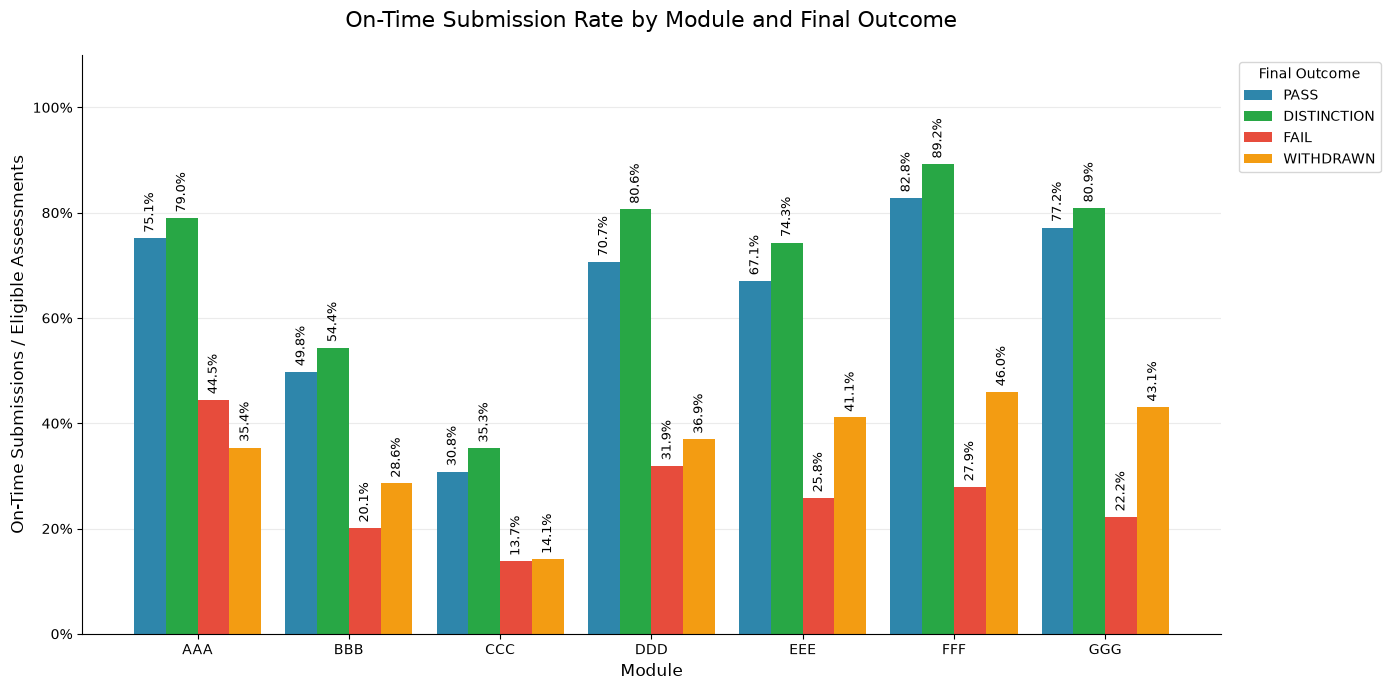

In [55]:
from matplotlib.ticker import PercentFormatter

outcome_order = ["PASS", "DISTINCTION", "FAIL", "WITHDRAWN"]

colors = {
    "PASS": "#2E86AB",
    "DISTINCTION": "#28A745",
    "FAIL": "#E74C3C",
    "WITHDRAWN": "#F39C12"
}

# تجهيز بيانات الرسم
chart_data = (
    module_outcome_timing
    .pivot(
        index="ModuleCode",
        columns="Outcome",
        values="OnTimeRateEligiblePct"
    )
    .reindex(columns=outcome_order)
    .sort_index()
)

x = np.arange(len(chart_data))
group_width = 0.84
bar_width = group_width / len(outcome_order)

fig, ax = plt.subplots(figsize=(14, 7))

for index, outcome in enumerate(outcome_order):

    positions = (
        x - group_width / 2
        + bar_width / 2
        + index * bar_width
    )

    values = chart_data[outcome]

    bars = ax.bar(
        positions,
        values,
        width=bar_width,
        color=colors[outcome],
        label=outcome
    )

    ax.bar_label(
        bars,
        labels=[
            f"{value:.1f}%" if np.isfinite(value) else ""
            for value in values
        ],
        padding=4,
        fontsize=9,
        rotation=90
    )

ax.set_xticks(x)
ax.set_xticklabels(chart_data.index)

ax.set_title(
    "On-Time Submission Rate by Module and Final Outcome",
    fontsize=16,
    pad=20
)

ax.set_xlabel("Module", fontsize=12)
ax.set_ylabel("On-Time Submissions / Eligible Assessments", fontsize=12)

ax.set_ylim(0, 110)
ax.set_yticks(np.arange(0, 101, 20))
ax.yaxis.set_major_formatter(PercentFormatter(xmax=100))

ax.set_axisbelow(True)
ax.grid(axis="y", alpha=0.25)
ax.spines[["top", "right"]].set_visible(False)

ax.legend(
    title="Final Outcome",
    loc="upper left",
    bbox_to_anchor=(1.01, 1)
)

plt.tight_layout()
plt.show()

Findings: Assessment Submission Among Failed and Withdrawn Enrollments by Module

- **AAA:** Withdrawn enrollments have lower on-time submission rates than failed enrollments, both relative to assessments due and among submissions with usable timing.
- **BBB:** Failed enrollments have lower on-time submission rates than withdrawn enrollments, with many assessment opportunities lacking a submission record in both groups.
- **CCC:** Both groups have low on-time submission rates. Withdrawn enrollments show more lateness among recorded submissions, while failed enrollments have a larger share of opportunities without a submission record.
- **DDD:** Failed enrollments have a lower on-time rate relative to all assessments due, whereas withdrawn enrollments have poorer timeliness when considering recorded submissions alone.
- **EEE:** The lower on-time rate among failed enrollments primarily reflects a larger share of opportunities without a submission record than among withdrawn enrollments.
- **FFF:** Failed enrollments have a larger submission-completion gap, even though most of their submissions with usable timing were on time. The same pattern appears to a lesser extent among withdrawn enrollments.
- **GGG:** Failed enrollments complete a smaller share of assessments than withdrawn enrollments, while timeliness among recorded submissions is relatively similar between the two groups.

> An absent submission record does not confirm non-submission until data completeness has been checked. For withdrawn enrollments, the comparison includes only assessments due before withdrawal.

### <h3 style="color: yellow; font : bold;">5. Analysis Three: Engagement with Learning Resources and Final Outcomes</h3>

##### Aggregate interaction records to enrollment level and validate the results

This query reads and aggregates the data in SQL Server, then transfers one row per enrollment with interaction records to Python, rather than loading millions of interaction rows.

In [56]:
query_engagement = """
SELECT
    StudentID,
    CourseOfferingCode,

    COUNT_BIG(*) AS InteractionRows,

    -- فحوصات الجودة
    SUM(CAST(
        CASE WHEN InteractionDay IS NULL THEN 1 ELSE 0 END
        AS BIGINT
    )) AS MissingDayRows,

    SUM(CAST(
        CASE WHEN SumClicks IS NULL THEN 1 ELSE 0 END
        AS BIGINT
    )) AS MissingClicksRows,

    SUM(CAST(
        CASE WHEN SumClicks < 0 THEN 1 ELSE 0 END
        AS BIGINT
    )) AS NegativeClicksRows,

    -- نطاق الأيام الموجودة في البيانات
    MIN(InteractionDay) AS FirstObservedInteractionDay,
    MAX(InteractionDay) AS LastObservedInteractionDay,

    -- التفاعل قبل بداية المقرر
    SUM(
        CASE WHEN InteractionDay < 0
             THEN CAST(SumClicks AS BIGINT)
             ELSE CAST(0 AS BIGINT)
        END
    ) AS ClicksBeforeStart,

    COUNT(DISTINCT
        CASE WHEN InteractionDay < 0 AND SumClicks > 0
             THEN InteractionDay
        END
    ) AS ActiveDaysBeforeStart,

    -- التفاعل من اليوم صفر عبر جميع الأيام المتاحة
    SUM(
        CASE WHEN InteractionDay >= 0
             THEN CAST(SumClicks AS BIGINT)
             ELSE CAST(0 AS BIGINT)
        END
    ) AS ClicksFromStart,

    COUNT(DISTINCT
        CASE WHEN InteractionDay >= 0 AND SumClicks > 0
             THEN InteractionDay
        END
    ) AS ActiveDaysFromStart,

    -- التفاعل خلال الأيام 0 إلى 27 شاملًا
    SUM(
        CASE WHEN InteractionDay BETWEEN 0 AND 27
             THEN CAST(SumClicks AS BIGINT)
             ELSE CAST(0 AS BIGINT)
        END
    ) AS ClicksDays0_27,

    COUNT(DISTINCT
        CASE WHEN InteractionDay BETWEEN 0 AND 27
                  AND SumClicks > 0
             THEN InteractionDay
        END
    ) AS ActiveDays0_27

FROM dw.FactDailyInteraction
GROUP BY
    StudentID,
    CourseOfferingCode;
"""

df_engagement = pd.read_sql_query(
    query_engagement,
    engine
)

display(df_engagement.head())

,StudentID,CourseOfferingCode,InteractionRows,MissingDayRows,MissingClicksRows,NegativeClicksRows,FirstObservedInteractionDay,LastObservedInteractionDay,ClicksBeforeStart,ActiveDaysBeforeStart,ClicksFromStart,ActiveDaysFromStart,ClicksDays0_27,ActiveDays0_27
0,475893,E2013J,76,0,0,0,2,233,0,0,466,23,116,3
1,614650,D2014B,156,0,0,0,-5,39,33,1,555,28,535,23
2,595655,C2014J,29,0,0,0,-3,22,10,3,58,6,58,6
3,143741,B2013B,168,0,0,0,-8,240,70,4,547,49,110,9
4,631492,B2014B,292,0,0,0,-3,220,22,2,629,72,132,10


Check the aggregation results.

In [57]:

engagement_keys = ["StudentID", "CourseOfferingCode"]

engagement_checks = pd.Series({
    "EnrollmentsWithInteractionRows": len(df_engagement),

    "SourceInteractionRows": (
        df_engagement["InteractionRows"].sum()
    ),

    "DuplicateEnrollmentKeys": (
        df_engagement.duplicated(subset=engagement_keys).sum()
    ),

    "RowsWithMissingEnrollmentKey": (
        df_engagement[engagement_keys].isna().any(axis=1).sum()
    ),

    "MissingDayRows": df_engagement["MissingDayRows"].sum(),

    "MissingClicksRows": df_engagement["MissingClicksRows"].sum(),

    "NegativeClicksRows": df_engagement["NegativeClicksRows"].sum(),

    "EnrollmentsAbove28ActiveDays": (
        df_engagement["ActiveDays0_27"] > 28
    ).sum()
}, name="Value")
display(
    engagement_checks
    .rename_axis("Check")
    .reset_index(name="Value")
    .style
    .hide(axis="index")
    .format({"Value": "{:,.0f}"})
    .set_properties(
        subset=["Check"],
        **{
            "text-align": "left",
            "white-space": "nowrap"
        }
    )
)


Check,Value
EnrollmentsWithInteractionRows,"29,228"
SourceInteractionRows,"8,459,320"
DuplicateEnrollmentKeys,0
RowsWithMissingEnrollmentKey,0
MissingDayRows,0
MissingClicksRows,0
NegativeClicksRows,0
EnrollmentsAbove28ActiveDays,0


Verify key matches between datasets.

In [58]:
engagement_keys = ["StudentID", "CourseOfferingCode"]

# مقارنة المفاتيح في الاتجاهين
df_engagement_key_audit = df_analysis[engagement_keys].merge(
    df_engagement[engagement_keys],
    on=engagement_keys,
    how="outer",
    validate="one_to_one",
    indicator="KeyMatch"
)

key_match_counts = (
    df_engagement_key_audit["KeyMatch"]
    .value_counts()
    .reindex(["both", "left_only", "right_only"], fill_value=0)
    .rename_axis("KeyMatch")
    .to_frame("EnrollmentCount")
)

display(key_match_counts)

# عرض أي مفاتيح تفاعل غير موجودة في بيانات التسجيل
df_unmatched_interaction_keys = df_engagement_key_audit.loc[
    df_engagement_key_audit["KeyMatch"].eq("right_only"),
    engagement_keys
]

display(df_unmatched_interaction_keys.head(10))

assert df_unmatched_interaction_keys.empty, (
    "توجد مفاتيح تفاعل غير موجودة في df_analysis؛ "
    "يجب مراجعتها قبل الدمج."
)

,EnrollmentCount
KeyMatch,
both,29228
left_only,3365
right_only,0


,StudentID,CourseOfferingCode


Merge the datasets.

In [59]:
# حماية من إعادة دمج أعمدة سبق إضافتها
overlapping_columns = (
    set(df_analysis.columns) & set(df_engagement.columns)
) - set(engagement_keys)

assert not overlapping_columns, (
    f"توجد أعمدة تفاعل مضافة بالفعل: {sorted(overlapping_columns)}"
)

# نسخة للتحليل مع الاحتفاظ بجميع التسجيلات
df_analysis_engagement = df_analysis.merge(
    df_engagement,
    on=engagement_keys,
    how="left",
    validate="one_to_one",
    indicator="EngagementMatch"
)

# وجود سجلات تفاعل، حتى لو كانت نقراتها صفرًا
df_analysis_engagement["HasInteractionRecords"] = (
    df_analysis_engagement["EngagementMatch"].eq("both")
)

assert len(df_analysis_engagement) == len(df_analysis), (
    "عدد التسجيلات تغير بعد الدمج."
)

assert not df_analysis_engagement.duplicated(
    subset=engagement_keys
).any(), "حدث تكرار في مفتاح التسجيل."

merge_summary = pd.Series({
    "RowsBeforeMerge": len(df_analysis),
    "RowsAfterMerge": len(df_analysis_engagement),
    "WithInteractionRecords": (
        df_analysis_engagement["HasInteractionRecords"].sum()
    ),
    "WithoutInteractionRecords": (
        (~df_analysis_engagement["HasInteractionRecords"]).sum()
    )
}, name="Value")

engagement_keys = ["StudentID", "CourseOfferingCode"]

engagement_checks = pd.Series({
    "EnrollmentsWithInteractionRows": len(df_engagement),

    "SourceInteractionRows": (
        df_engagement["InteractionRows"].sum()
    ),

    "DuplicateEnrollmentKeys": (
        df_engagement.duplicated(subset=engagement_keys).sum()
    ),

    "RowsWithMissingEnrollmentKey": (
        df_engagement[engagement_keys].isna().any(axis=1).sum()
    ),

    "MissingDayRows": df_engagement["MissingDayRows"].sum(),

    "MissingClicksRows": df_engagement["MissingClicksRows"].sum(),

    "NegativeClicksRows": df_engagement["NegativeClicksRows"].sum(),

    "EnrollmentsAbove28ActiveDays": (
        df_engagement["ActiveDays0_27"] > 28
    ).sum()
}, name="Value")
display(
    merge_summary
    .rename_axis("Check")
    .reset_index(name="Value")
    .style
    .hide(axis="index")
    .format({"Value": "{:,.0f}"})
    .set_properties(
        subset=["Check"],
        **{
            "text-align": "left",
            "white-space": "nowrap"
        }
    )
)



Check,Value
RowsBeforeMerge,"32,593"
RowsAfterMerge,"32,593"
WithInteractionRecords,"29,228"
WithoutInteractionRecords,"3,365"


##### Initial comparison of recorded engagement by final outcome

,TotalEnrollments,PositiveClicksCount,PositiveClicksPct,ZeroClicksWithRecordsCount,ZeroClicksWithRecordsPct,NoRecordsCount,NoRecordsPct
OutcomeAnalysis,,,,,,,
DISTINCTION,3024,3024,100.00,0,0.00,0,0.00
PASS,12361,12358,99.98,0,0.00,3,0.02
FAIL,7052,6585,93.38,93,1.32,374,5.30
WITHDRAWN,10156,6533,64.33,635,6.25,2988,29.42


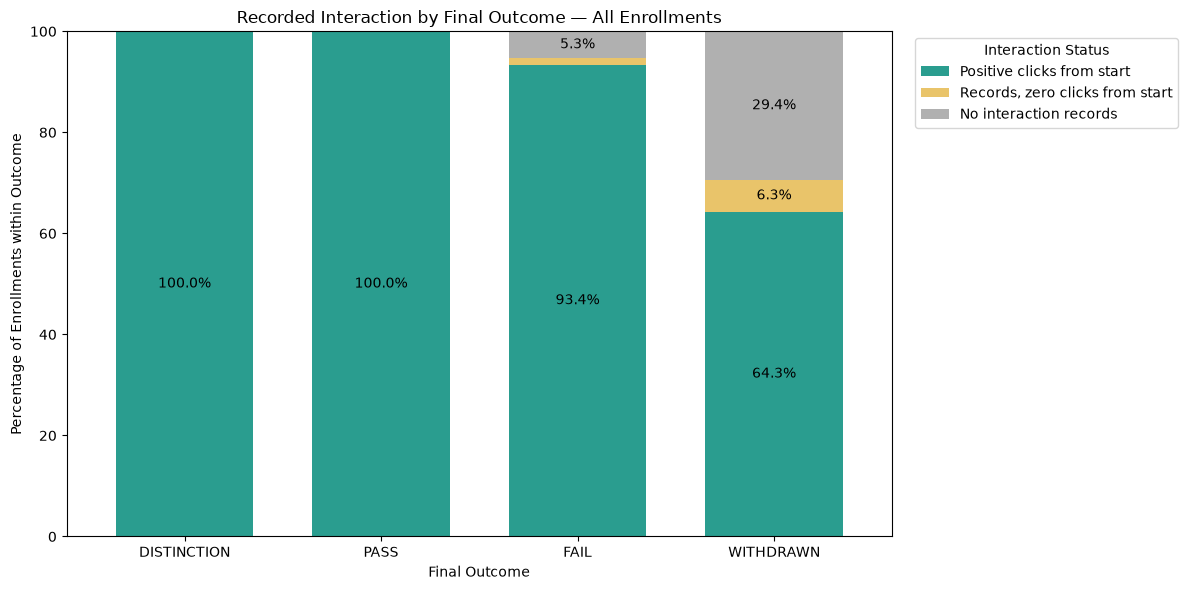

In [60]:
# نسخة مستقلة من جدول التسجيلات بعد دمج التفاعل
interaction_analysis = df_analysis_engagement.copy()

# تأكيد أن كل صف يمثل تسجيلًا واحدًا
assert not interaction_analysis.duplicated(
    ["StudentID", "CourseOfferingCode"]
).any(), "يوجد تكرار في مفتاح التسجيل."

# النتيجة النهائية
interaction_analysis["OutcomeAnalysis"] = (
    interaction_analysis["FinalResult"]
    .astype("string")
    .str.strip()
    .str.upper()
    .fillna("UNKNOWN")
    .replace("", "UNKNOWN")
)

# المؤشر المستخدم: إجمالي النقرات من اليوم صفر
metric = "ClicksFromStart"

has_records = interaction_analysis["HasInteractionRecords"].eq(True)
clicks = interaction_analysis[metric]

assert clicks.loc[has_records].notna().all(), \
    "توجد نقرات مفقودة داخل التسجيلات التي لها سجلات تفاعل."

assert clicks.loc[has_records].ge(0).all(), \
    "توجد قيم نقرات سالبة."
# تصنيف حالات التفاعل
# تصنيف التسجيلات دون تعويض القيم المفقودة
interaction_analysis["InteractionStatus"] = "No interaction records"

interaction_analysis.loc[
    has_records & clicks.eq(0),
    "InteractionStatus"
] = "Records, zero clicks from start"                    # إذا كان الطالب لديه سجل تفاعل مسجل ولكن عدد النقرات يساوي صفر

interaction_analysis.loc[ 
    has_records & clicks.gt(0),
    "InteractionStatus"
] = "Positive clicks from start"                         # تفاعل ونقرات فعلية

# عدد التسجيلات حسب النتيجة وحالة التفاعل
status_order = [                                         
    "Positive clicks from start",
    "Records, zero clicks from start",
    "No interaction records"                             # لا توجد أي سجلات تفاعل من الأساس
]

counts = pd.crosstab(
    interaction_analysis["OutcomeAnalysis"],
    interaction_analysis["InteractionStatus"]
).reindex(columns=status_order, fill_value=0)

# ترتيب النتائج مع الاحتفاظ بأي تصنيفات إضافية
outcome_order = ["DISTINCTION", "PASS", "FAIL", "WITHDRAWN", "UNKNOWN"]

counts = counts.reindex(
    [x for x in outcome_order if x in counts.index]
    + [x for x in counts.index if x not in outcome_order]
)

# النسب داخل كل نتيجة نهائية
totals = counts.sum(axis=1)

percentages = counts.div(totals, axis=0).mul(100)

# جدول يجمع الأعداد والنسب
summary = pd.DataFrame({
    "TotalEnrollments": totals,

    "PositiveClicksCount": counts[status_order[0]],
    "PositiveClicksPct": percentages[status_order[0]],

    "ZeroClicksWithRecordsCount": counts[status_order[1]],
    "ZeroClicksWithRecordsPct": percentages[status_order[1]],

    "NoRecordsCount": counts[status_order[2]],
    "NoRecordsPct": percentages[status_order[2]]
})

display(summary.round(2))

# رسم نسب التفاعل داخل كل نتيجة
ax = percentages.plot(
    kind="bar",
    stacked=True,
    figsize=(12, 6),
    color=["#2A9D8F", "#E9C46A", "#B0B0B0"],
    width=0.7
)

# إظهار النسبة داخل كل جزء إذا كانت مساحته مناسبة
for container in ax.containers:
    labels = [
        f"{bar.get_height():.1f}%"
        if bar.get_height() >= 3 else ""
        for bar in container
    ]
    ax.bar_label(
        container,
        labels=labels,
        label_type="center",
        fontsize=10
    )

ax.set_title("Recorded Interaction by Final Outcome — All Enrollments")
ax.set_xlabel("Final Outcome")
ax.set_ylabel("Percentage of Enrollments within Outcome")
ax.set_ylim(0, 100)
ax.tick_params(axis="x", rotation=0)

ax.legend(
    title="Interaction Status",
    bbox_to_anchor=(1.02, 1),
    loc="upper left"
)

plt.tight_layout()
plt.show()

**Findings**

**Failure:** Although 93.38% of failed enrollments recorded clicks, they still ended in failure. The presence of engagement alone is therefore insufficient to distinguish pass from failure. Further comparisons should consider engagement volume, consistency and assessment submission.

**Withdrawal:** There are 2,988 withdrawn enrollments, or 29.42% of all withdrawn enrollments, without matching interaction records. A further 635, or 6.25%, have records but no clicks from day 0 onward; their engagement may have occurred only before the course started.

**Pass and distinction:** All distinction enrollments, and almost all pass enrollments, recorded clicks from the course start onward.

##### Are early click intensity and active days associated with the final outcome?

Restricting the comparison to enrollments eligible for the full window excludes early withdrawals. The results therefore describe enrollments that remained eligible throughout the window. Early withdrawal will be considered separately, and this comparison will not be generalized to all enrollments.

In [61]:
df = df_analysis_engagement

# متغيرات مساعدة؛ لا نستبدل الأعمدة الأصلية
registration = pd.to_numeric(df["RegistrationDay"], errors="raise")
unregistration = pd.to_numeric(df["UnregistrationDay"], errors="raise")
course_length = pd.to_numeric(df["PresentationLengthDays"], errors="raise")

result = df["FinalResult"].astype("string").str.strip().str.upper()

# بيانات توقيت متناقضة أو طول مقرر غير صالح
# تعارضات زمنية أو تناقض بين النتيجة ويوم الانسحاب
timing_issue = (
    course_length.le(0)
    | registration.gt(course_length)
    | unregistration.lt(registration)
    | unregistration.gt(course_length)
    | (
        result.isin(["PASS", "DISTINCTION", "FAIL"])
        & unregistration.notna()
    )
).fillna(False)

# دليل على الاستمرار طوال النافذة
continued_through_window = (
    (unregistration > 27)
    | (
        unregistration.isna()
        & result.isin(["PASS", "DISTINCTION", "FAIL"])
    )
).fillna(False)

# شروط الأهلية الكاملة
full_window = (
    (registration <= 0)
    & (course_length >= 28)
    & continued_through_window
).fillna(False)

# سبب معلوم لعدم إتاحة النافذة كاملة
partial_window = (
    (registration > 0)
    | (unregistration <= 27)
    | ((course_length > 0) & (course_length < 28))
).fillna(False)

df["EligibilityDays0_27"] = np.select(
    [
        timing_issue.to_numpy(dtype=bool),
        full_window.to_numpy(dtype=bool),
        partial_window.to_numpy(dtype=bool)
    ],
    [
        "REVIEW_TIMING",                               # يوجد تعارض زمني أو طول مقرر غير صالح يحتاج مراجعة  
        "FULL_WINDOW",                                 # التسجيل مؤهل لفترة الأيام 0–27 كاملة
        "NOT_FULL_WINDOW"                              # يوجد سبب معلوم لعدم إتاحة الفترة كاملة
    ],
    default="UNKNOWN"                                  # البيانات المتاحة لا تكفي لتحديد الأهلية
)

eligibility_summary = (
    df["EligibilityDays0_27"]
    .value_counts()
    .reindex(
        ["FULL_WINDOW", "NOT_FULL_WINDOW", "UNKNOWN", "REVIEW_TIMING"],
        fill_value=0
    )
    .rename_axis("EligibilityDays0_27")
    .to_frame("EnrollmentCount")
)

# توزيع وجود سجلات التفاعل داخل كل فئة أهلية
interaction_counts = pd.crosstab(
    df["EligibilityDays0_27"],
    df["HasInteractionRecords"]
).reindex(
    columns=[False, True],
    fill_value=0
).rename(columns={
    False: "WithoutInteractionRecords",
    True: "WithInteractionRecords"
})

# دمج الملخص مع توزيع سجلات التفاعل
eligibility_display = (
    eligibility_summary
    .join(interaction_counts)
    .fillna(0)
    .astype(int)
    .rename_axis("Eligibility")
    .reset_index()
)

# عرض موحد ومنسق
display(
    eligibility_display.style
    .hide(axis="index")
    .format({
        column: "{:,.0f}"
        for column in eligibility_display.columns
        if column != "Eligibility"
    })
    .set_properties(
        subset=["Eligibility"],
        **{
            "text-align": "left",
            "white-space": "nowrap"
        }
    )
    .set_caption("Eligibility and Interaction Records")
)

Eligibility,EnrollmentCount,WithoutInteractionRecords,WithInteractionRecords
FULL_WINDOW,"27,229",475,"26,754"
NOT_FULL_WINDOW,"5,256","2,864","2,392"
UNKNOWN,98,25,73
REVIEW_TIMING,10,1,9


**Compare early engagement by final outcome**

In [62]:
# 1) جميع التسجيلات المؤهلة لنافذة الأيام 0–27
early_eligible = df.loc[
    df["EligibilityDays0_27"].eq("FULL_WINDOW")
].copy()

early_eligible["OutcomeAnalysis"] = (
    early_eligible["FinalResult"]
    .astype("string")
    .str.strip()
    .str.upper()
    .fillna("UNKNOWN")
    .replace("", "UNKNOWN")
)

# توضيح عدد التسجيلات المستخدمة والمستبعدة من حساب المؤشرات
coverage = (
    early_eligible
    .groupby("OutcomeAnalysis")
    .agg(
        EligibleEnrollments=("StudentID", "size"),
        WithInteractionRecords=("HasInteractionRecords", "sum")
    )
)

coverage["WithoutInteractionRecords"] = (
    coverage["EligibleEnrollments"]
    - coverage["WithInteractionRecords"]
)

# 2) حساب المؤشرات للتسجيلات ذات سجلات التفاعل فقط
# نحتفظ بالأصفار الموجودة فعليًا في المؤشرات
early_observed = early_eligible.loc[
    early_eligible["HasInteractionRecords"]
].copy()

metrics = ["ClicksDays0_27", "ActiveDays0_27"]

assert early_observed[metrics].notna().all().all(), \
    "توجد مؤشرات تفاعل مفقودة تحتاج مراجعة."

early_summary = (
    early_observed
    .groupby("OutcomeAnalysis")
    .agg(
        MeanClicks=("ClicksDays0_27", "mean"),
        MedianClicks=("ClicksDays0_27", "median"),
        MeanActiveDays=("ActiveDays0_27", "mean"),
        MedianActiveDays=("ActiveDays0_27", "median")
    )
)

# 3) عرض التغطية والمؤشرات في جدول واحد
early_outcome_summary = coverage.join(early_summary)

outcome_order = ["DISTINCTION", "PASS", "FAIL", "WITHDRAWN", "UNKNOWN"]

early_outcome_summary = early_outcome_summary.reindex(
    [x for x in outcome_order if x in early_outcome_summary.index]
)

display(early_outcome_summary.round(2))

,EligibleEnrollments,WithInteractionRecords,WithoutInteractionRecords,MeanClicks,MedianClicks,MeanActiveDays,MedianActiveDays
OutcomeAnalysis,,,,,,,
DISTINCTION,3008,3008,0,413.91,287.0,14.24,14.0
PASS,12258,12256,2,308.26,210.0,12.12,11.0
FAIL,6971,6609,362,181.21,109.0,8.08,7.0
WITHDRAWN,4992,4881,111,225.54,144.0,9.64,8.0


**Plot the relationship between early engagement by final outcome**

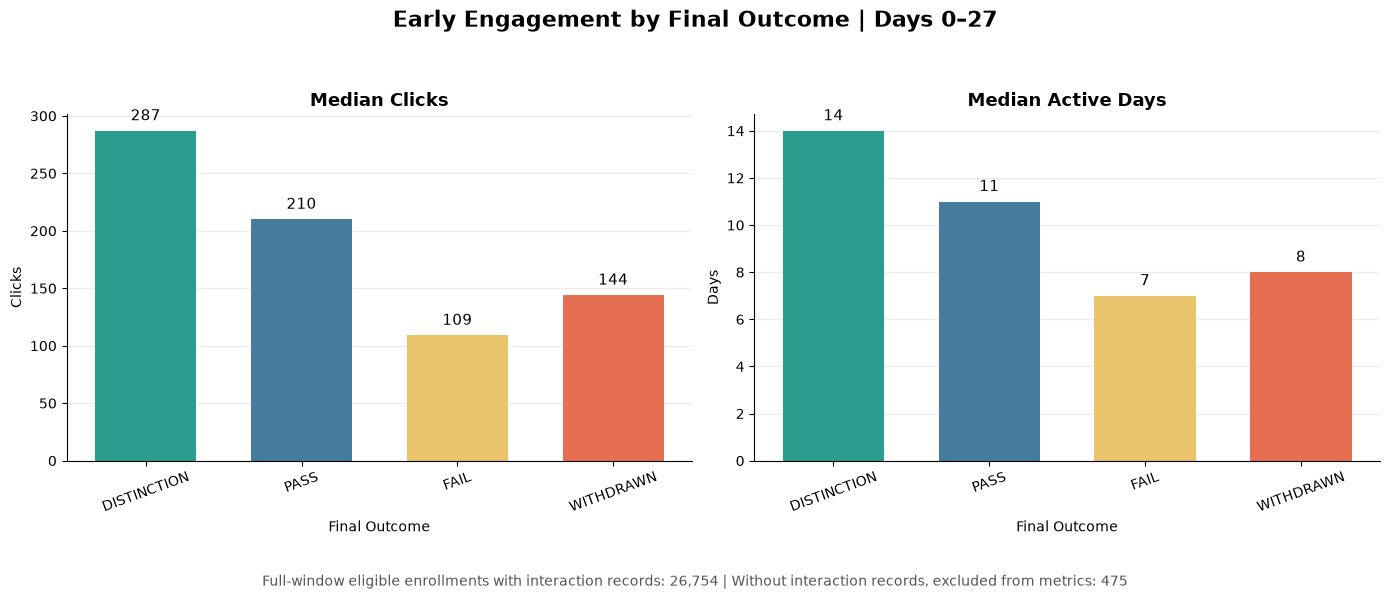

In [63]:
# ترتيب النتائج وألوان ثابتة لها
outcome_colors = {
    "DISTINCTION": "#2A9D8F",
    "PASS": "#457B9D",
    "FAIL": "#E9C46A",
    "WITHDRAWN": "#E76F51",
    "UNKNOWN": "#9E9E9E"
}

plot_data = early_outcome_summary.copy()

colors = [
    outcome_colors.get(outcome, "#9E9E9E")
    for outcome in plot_data.index
]

fig, axes = plt.subplots(1, 2, figsize=(14, 6))

chart_settings = [
    ("MedianClicks", "Median Clicks", "Clicks", axes[0]),
    ("MedianActiveDays", "Median Active Days", "Days", axes[1])
]

for column, title, ylabel, ax in chart_settings:
    bars = ax.bar(
        plot_data.index,
        plot_data[column],
        color=colors,
        width=0.65
    )

    # قيمة المؤشر أعلى كل عمود
    labels = [
        f"{value:,.1f}".rstrip("0").rstrip(".")
        if pd.notna(value) else ""
        for value in plot_data[column]
    ]

    ax.bar_label(bars, labels=labels, padding=5, fontsize=11)

    ax.set_title(title, fontsize=13, fontweight="bold")
    ax.set_xlabel("Final Outcome")
    ax.set_ylabel(ylabel)
    ax.tick_params(axis="x", rotation=20)

    ax.set_ylim(bottom=0)
    ax.margins(y=0.18)
    ax.set_axisbelow(True)
    ax.grid(axis="y", alpha=0.25)

    ax.spines[["top", "right"]].set_visible(False)

fig.suptitle(
    "Early Engagement by Final Outcome | Days 0–27",
    fontsize=16,
    fontweight="bold"
)

# توضيح نطاق التسجيلات المستخدمة
observed_count = int(plot_data["WithInteractionRecords"].sum())
excluded_count = int(plot_data["WithoutInteractionRecords"].sum())

fig.text(
    0.5, 0.02,
    f"Full-window eligible enrollments with interaction records: "
    f"{observed_count:,} | "
    f"Without interaction records, excluded from metrics: {excluded_count:,}",
    ha="center",
    fontsize=10,
    color="#555555"
)

plt.tight_layout(rect=[0, 0.08, 1, 0.93])
plt.show()

Among enrollments eligible for days 0–27 and with interaction records, pass and distinction were associated with more clicks and active days than failure and withdrawal. However, early engagement among withdrawn enrollments exceeded that among failed enrollments, indicating that engagement alone does not explain the final outcome.

**Limitations:** The means and medians exclude 475 eligible enrollments without interaction records, including 362 failed enrollments. The comparison also excludes enrollments ineligible for the full window and establishes neither causality nor statistical significance.

**Compare clicks and active days by final outcome within each module**

In [64]:
# ملخص التفاعل المبكر حسب المقرر والنتيجة النهائية
course_engagement_summary = (
    early_observed
    .groupby(["ModuleCode", "OutcomeAnalysis"])
    .agg(
        EnrollmentCount=("StudentID", "size"),
        MedianClicks=("ClicksDays0_27", "median"),
        MeanClicks=("ClicksDays0_27", "mean"),
        MedianActiveDays=("ActiveDays0_27", "median"),
        MeanActiveDays=("ActiveDays0_27", "mean")
    )
    .reset_index()
)

display(course_engagement_summary.round(2))

,ModuleCode,OutcomeAnalysis,EnrollmentCount,MedianClicks,MeanClicks,MedianActiveDays,MeanActiveDays
0,AAA,DISTINCTION,44,488.5,616.20,19.5,18.39
1,AAA,FAIL,87,125.0,172.08,7.0,8.18
2,AAA,PASS,484,279.5,361.31,14.0,13.98
3,AAA,WITHDRAWN,95,275.0,383.72,12.0,13.22
4,BBB,DISTINCTION,668,147.0,224.03,10.0,11.60
5,BBB,FAIL,1597,58.0,102.94,5.0,6.45
6,BBB,PASS,3023,107.0,168.08,8.0,9.23
7,BBB,WITHDRAWN,844,78.0,129.73,6.0,7.41
8,CCC,DISTINCTION,496,321.5,428.29,14.0,14.08
9,CCC,FAIL,749,147.0,197.03,7.0,7.91


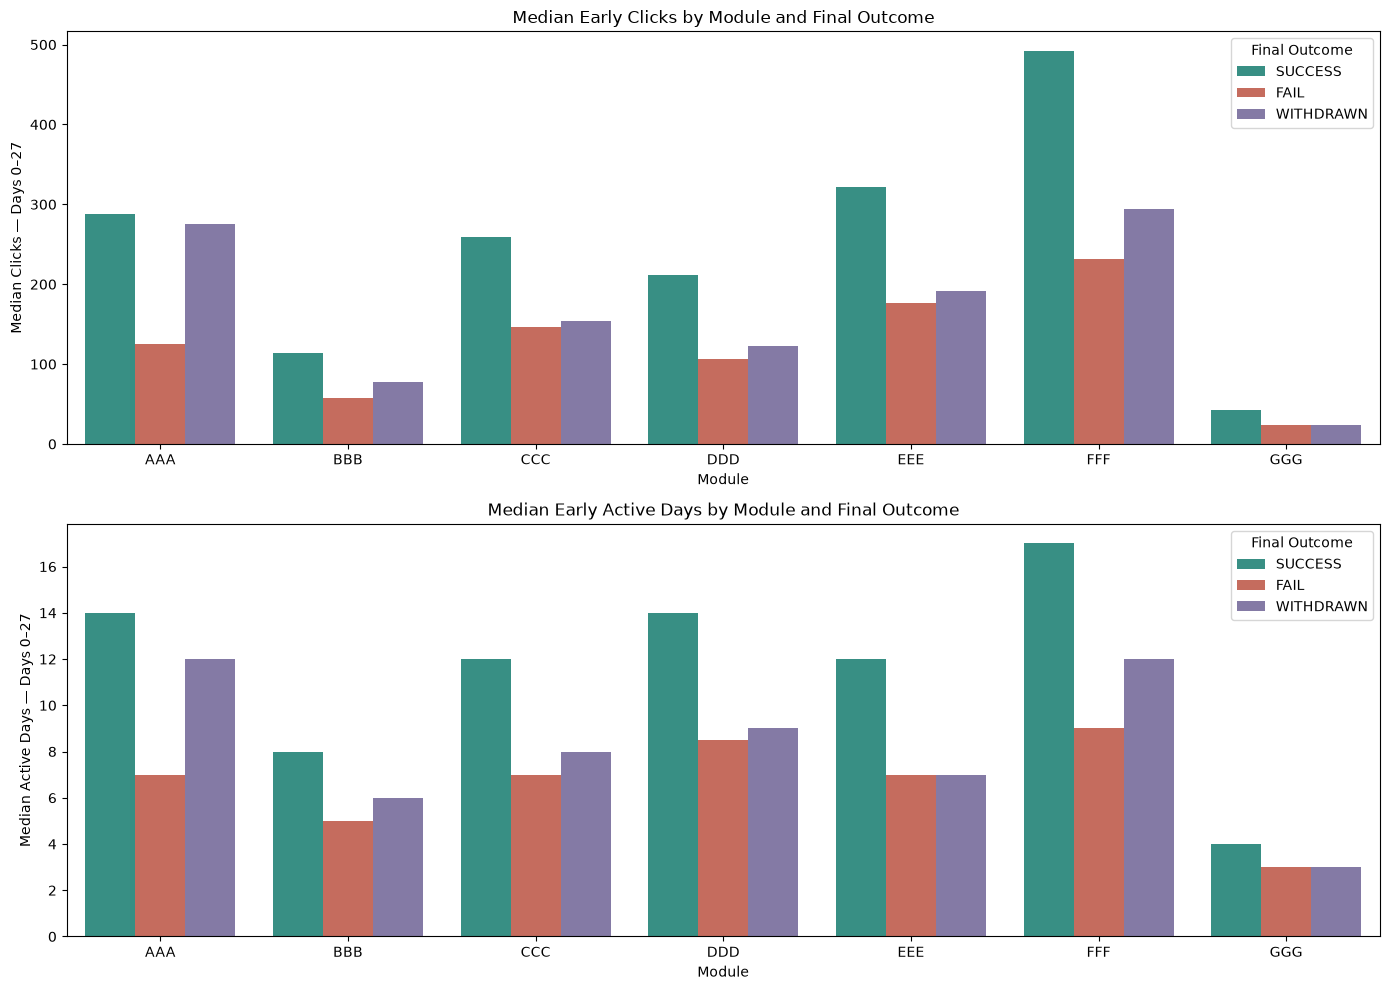

In [65]:
# دمج النجاح والتفوق في فئة واحدة
plot_data = early_observed.copy()

plot_data["OutcomeGroup"] = plot_data["OutcomeAnalysis"].replace({
    "PASS": "SUCCESS",
    "DISTINCTION": "SUCCESS"
})

# إعادة حساب المؤشرات بعد دمج الفئتين
course_engagement_summary = (
    plot_data
    .groupby(["ModuleCode", "OutcomeGroup"])
    .agg(
        EnrollmentCount=("StudentID", "size"),
        MedianClicks=("ClicksDays0_27", "median"),
        MedianActiveDays=("ActiveDays0_27", "median")
    )
    .reset_index()
)

# الرسم
outcome_order = ["SUCCESS", "FAIL", "WITHDRAWN"]

colors = {
    "SUCCESS": "#2A9D8F",
    "FAIL": "#D6604D",
    "WITHDRAWN": "#8073AC"
}

fig, axes = plt.subplots(2, 1, figsize=(14, 10))

for ax, metric, title, ylabel in [
    (
        axes[0],
        "MedianClicks",
        "Median Early Clicks by Module and Final Outcome",
        "Median Clicks — Days 0–27"
    ),
    (
        axes[1],
        "MedianActiveDays",
        "Median Early Active Days by Module and Final Outcome",
        "Median Active Days — Days 0–27"
    )
]:
    sns.barplot(
        data=course_engagement_summary,
        x="ModuleCode",
        y=metric,
        hue="OutcomeGroup",
        hue_order=outcome_order,
        palette=colors,
        errorbar=None,
        ax=ax
    )

    ax.set_title(title)
    ax.set_xlabel("Module")
    ax.set_ylabel(ylabel)
    ax.legend(title="Final Outcome")

plt.tight_layout()
plt.show()

In the charts above, PASS and DISTINCTION are combined into a single SUCCESS group.

Higher engagement volume and more sustained activity during the first four weeks were associated with better final outcomes. The success group had higher median clicks and active days than the failed and withdrawn groups within all seven modules. However, early engagement alone did not clearly distinguish some groups, particularly failure and withdrawal.

##### Weekly engagement analysis

In [66]:
# أساس مستقل للتحليل الأسبوعي لجميع التسجيلات
df_weekly_base = df_analysis.copy()

enrollment_keys = ["StudentID", "CourseOfferingCode"]

required_columns = [
    "StudentID",
    "CourseOfferingCode",
    "FinalResult",
    "RegistrationDay",
    "UnregistrationDay",
    "PresentationLengthDays"
]

missing_columns = [
    column
    for column in required_columns
    if column not in df_weekly_base.columns
]

if missing_columns:
    raise ValueError(f"Missing columns: {missing_columns}")

if df_weekly_base[enrollment_keys].isna().any().any():
    raise ValueError("Missing enrollment keys.")

if df_weekly_base.duplicated(enrollment_keys).any():
    raise ValueError("Duplicate enrollment keys.")

print(f"Base enrollments: {len(df_weekly_base):,}")

Base enrollments: 32,593


**Combine pass and distinction into a single success group**

In [67]:
outcome = (
    df_weekly_base["FinalResult"]
    .astype("string")
    .str.strip()
    .str.upper()
)

df_weekly_base["OutcomeGroup"] = outcome.replace({
    "PASS": "SUCCESS",
    "DISTINCTION": "SUCCESS"
}).fillna("UNKNOWN")

outcome_order = ["SUCCESS", "WITHDRAWN", "FAIL"]

display(
    df_weekly_base["OutcomeGroup"]
    .value_counts()
    .rename_axis("OutcomeGroup")
    .to_frame("EnrollmentCount")
)

,EnrollmentCount
OutcomeGroup,
SUCCESS,15385
WITHDRAWN,10156
FAIL,7052


**Load weekly engagement aggregates from SQL Server**

In [68]:
query_weekly = """
SELECT
    StudentID,
    CourseOfferingCode,

    CASE
        WHEN InteractionDay < 0 THEN 0
        ELSE (InteractionDay / 7) + 1
    END AS StudyWeek,

    COUNT_BIG(*) AS InteractionRows,

    SUM(CAST(SumClicks AS BIGINT)) AS WeeklyClicks,

    COUNT(DISTINCT
        CASE WHEN SumClicks > 0 THEN InteractionDay END
    ) AS WeeklyActiveDays

FROM dw.FactDailyInteraction

GROUP BY
    StudentID,
    CourseOfferingCode,
    CASE
        WHEN InteractionDay < 0 THEN 0
        ELSE (InteractionDay / 7) + 1
    END;
"""

df_weekly_all = pd.read_sql_query(query_weekly, engine)

weekly_keys = enrollment_keys + ["StudyWeek"]

assert not df_weekly_all[weekly_keys].isna().any().any(), \
    "توجد مفاتيح أو أيام تفاعل مفقودة."

assert not df_weekly_all.duplicated(weekly_keys).any(), \
    "يوجد تكرار في مفتاح التسجيل والأسبوع."

# الاحتفاظ بالتفاعل السابق للبداية منفصلًا
df_before_start = df_weekly_all.loc[
    df_weekly_all["StudyWeek"].eq(0)
].copy()

df_weekly_engagement = df_weekly_all.loc[
    df_weekly_all["StudyWeek"].ge(1)
].copy()

assert df_weekly_engagement["WeeklyActiveDays"].between(0, 7).all()

display(df_weekly_engagement.head())

,StudentID,CourseOfferingCode,StudyWeek,InteractionRows,WeeklyClicks,WeeklyActiveDays
0,1611842,D2013B,4,53,111,6
1,116808,F2013J,21,33,211,5
2,233752,B2013J,19,30,196,7
3,567754,B2013J,18,14,28,6
4,370839,C2014J,13,27,83,2


**Validate the joins and identify enrollments with any interaction records**

In [69]:
enrollment_keys = ["StudentID", "CourseOfferingCode"]

# مفاتيح التسجيلات التي لها سجلات تفاعل
interaction_keys = (
    df_engagement[enrollment_keys]
    .drop_duplicates()
    .copy()
)
interaction_flags = interaction_keys.assign(
    HasInteractionRecords=True
)

# يسمح بإعادة تنفيذ الخلية دون تكرار العمود
df_weekly_base = (
    df_weekly_base
    .drop(columns="HasInteractionRecords", errors="ignore")
    .merge(
        interaction_flags,
        on=enrollment_keys,
        how="left",
        validate="one_to_one"
    )
)

df_weekly_base["HasInteractionRecords"] = (
    df_weekly_base["HasInteractionRecords"].eq(True)
)

print(f"Weekly interaction rows: {len(df_weekly_engagement):,}")

Weekly interaction rows: 579,438


**Create the weekly measurement periods and determine eligibility**

An enrollment is eligible for a full week only if it has started by the beginning of that week, continues beyond the end of the week, and the entire week falls within the course duration.

In [70]:
base_columns = [
    "StudentID", "CourseOfferingCode", "OutcomeGroup",
    "RegistrationDay", "UnregistrationDay",
    "PresentationLengthDays", "HasInteractionRecords"
]

base = df_weekly_base[base_columns].copy()

lengths = pd.to_numeric(
    base["PresentationLengthDays"], errors="raise"
)

valid_lengths = lengths[lengths.gt(0)]

assert not valid_lengths.empty, "لا توجد أطوال مقررات صالحة."

max_week = max(
    int(np.ceil(valid_lengths.max() / 7)),
    int(df_weekly_engagement["StudyWeek"].max())
)

calendar = pd.DataFrame({
    "StudyWeek": np.arange(1, max_week + 1)
})

calendar["WeekStartDay"] = (calendar["StudyWeek"] - 1) * 7
calendar["WeekEndDay"] = calendar["WeekStartDay"] + 6

df_weekly_panel = base.merge(calendar, how="cross")

reg = pd.to_numeric(
    df_weekly_panel["RegistrationDay"], errors="raise"
)
unreg = pd.to_numeric(
    df_weekly_panel["UnregistrationDay"], errors="raise"
)
length = pd.to_numeric(
    df_weekly_panel["PresentationLengthDays"], errors="raise"
)

start = df_weekly_panel["WeekStartDay"]
end = df_weekly_panel["WeekEndDay"]

timing_issue = (
    length.le(0)
    | unreg.lt(reg)
    | unreg.gt(length)
).fillna(False)

outside_course = start.ge(length).fillna(False)

not_full_week = (
    reg.gt(start)
    | unreg.le(end)
    | length.le(end)
).fillna(False)

continued = (
    unreg.gt(end)
    | (
        unreg.isna()
        & df_weekly_panel["OutcomeGroup"].isin(["SUCCESS", "FAIL"])
    )
).fillna(False)

full_week = (
    reg.le(start)
    & length.gt(end)
    & continued
).fillna(False)

df_weekly_panel["WeekEligibility"] = np.select(
    [
        timing_issue.to_numpy(dtype=bool),
        outside_course.to_numpy(dtype=bool),
        not_full_week.to_numpy(dtype=bool),
        full_week.to_numpy(dtype=bool)
    ],
    [
        "REVIEW_TIMING",
        "OUTSIDE_COURSE",
        "NOT_FULL_WEEK",
        "FULL_WEEK"
    ],
    default="UNKNOWN"
)

display(
    df_weekly_panel["WeekEligibility"]
    .value_counts()
    .to_frame("EnrollmentWeekRows")
)

,EnrollmentWeekRows
WeekEligibility,
FULL_WEEK,894233
NOT_FULL_WEEK,314592
OUTSIDE_COURSE,58550
UNKNOWN,3713
REVIEW_TIMING,39


**Merge the measures and calculate weekly engagement**

In [71]:
weekly_keys = ["StudentID", "CourseOfferingCode", "StudyWeek"]

df_weekly_panel = df_weekly_panel.merge(
    df_weekly_engagement[
        weekly_keys + ["WeeklyClicks", "WeeklyActiveDays"]
    ],
    on=weekly_keys,
    how="left",
    validate="one_to_one",
    indicator="WeeklyMatch"
)

df_full_week = df_weekly_panel.loc[
    df_weekly_panel["WeekEligibility"].eq("FULL_WEEK")
].copy()

# الحفاظ على المؤشرات الأصلية
df_full_week["RecordedClicks"] = df_full_week["WeeklyClicks"]
df_full_week["RecordedActiveDays"] = df_full_week["WeeklyActiveDays"]

# غياب الأسبوع داخل تسجيل له سجلات في أوقات أخرى
zero_recorded = (
    df_full_week["WeeklyMatch"].eq("left_only")
    & df_full_week["HasInteractionRecords"]
)

df_full_week.loc[
    zero_recorded,
    ["RecordedClicks", "RecordedActiveDays"]
] = 0

# التسجيلات دون أي سجلات تظل مفقودة
assert df_full_week.loc[
    ~df_full_week["HasInteractionRecords"],
    ["RecordedClicks", "RecordedActiveDays"]
].isna().all().all()

weekly_by_outcome = (
    df_full_week
    .groupby(["StudyWeek", "OutcomeGroup"])
    .agg(
        EligibleEnrollments=("StudentID", "size"),
        MeasuredEnrollments=("RecordedClicks", "count"),
        MeanRecordedClicks=("RecordedClicks", "mean"),
        MedianRecordedClicks=("RecordedClicks", "median"),
        MeanRecordedActiveDays=("RecordedActiveDays", "mean")
    )
    .reset_index()
)

weekly_by_outcome["UnmeasuredEnrollments"] = (
    weekly_by_outcome["EligibleEnrollments"]
    - weekly_by_outcome["MeasuredEnrollments"]
)

display(weekly_by_outcome.head(12).round(2))

,StudyWeek,OutcomeGroup,EligibleEnrollments,MeasuredEnrollments,MeanRecordedClicks,MedianRecordedClicks,MeanRecordedActiveDays,UnmeasuredEnrollments
0,1,FAIL,6972,6610,45.93,18.0,2.05,362
1,1,SUCCESS,15266,15264,85.02,47.0,3.07,2
2,1,WITHDRAWN,6623,6137,52.58,21.0,2.28,486
3,2,FAIL,7008,6643,39.53,14.0,1.87,365
4,2,SUCCESS,15344,15342,76.75,42.0,3.02,2
5,2,WITHDRAWN,5583,5381,49.05,20.0,2.25,202
6,3,FAIL,7022,6657,57.22,24.0,2.20,365
7,3,SUCCESS,15360,15358,94.53,57.0,3.32,2
8,3,WITHDRAWN,5374,5188,70.42,38.0,2.57,186
9,4,FAIL,7031,6664,38.40,11.0,1.96,367


The denominator for each weekly mean consists of enrollments eligible for that week and with interaction records at any time, including their weeks with zero recorded clicks. Enrollments with no interaction records remain outside the mean; their count is reported in `UnmeasuredEnrollments`.

**Visualize the results**

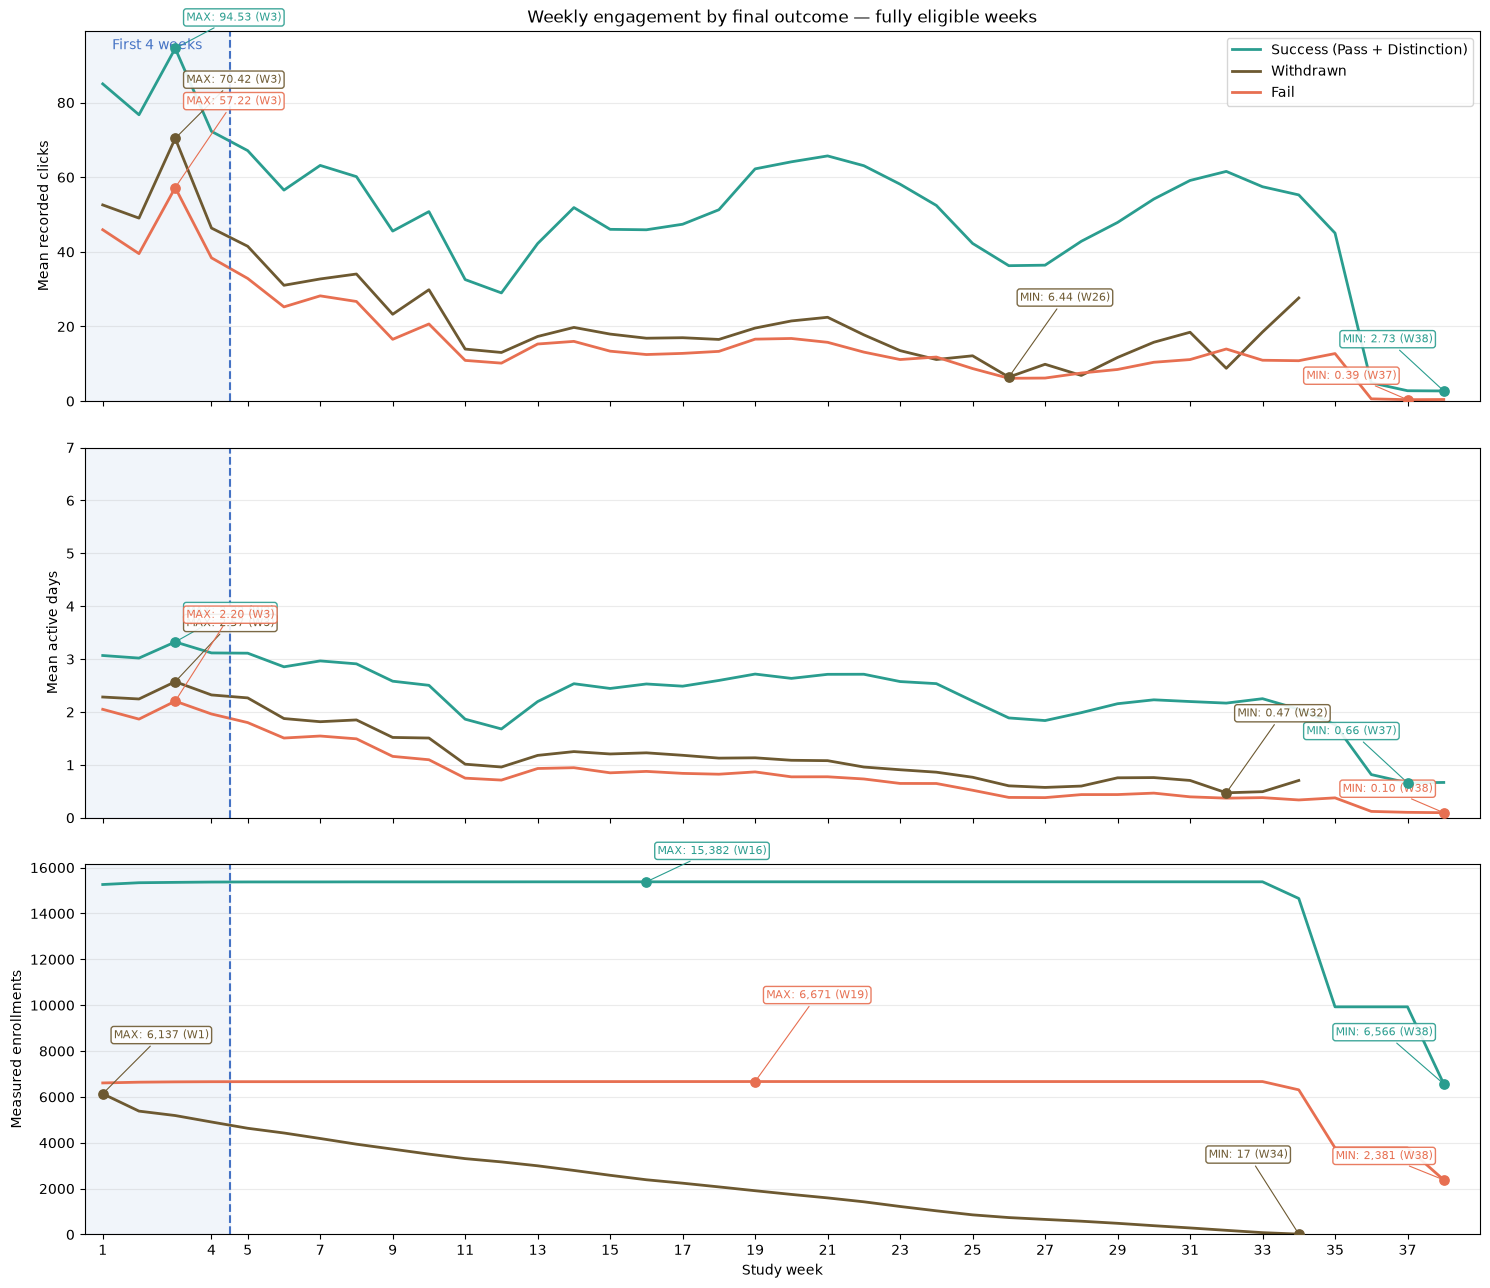

In [72]:
outcome_order = ["SUCCESS", "WITHDRAWN", "FAIL"]

colors = {
    "SUCCESS": "#2A9D8F",
    "WITHDRAWN": "#6D5931",
    "FAIL": "#E76F51"
}

labels = {
    "SUCCESS": "Success (Pass + Distinction)",
    "WITHDRAWN": "Withdrawn",
    "FAIL": "Fail"
}

weeks = pd.Index(
    np.arange(1, int(weekly_by_outcome["StudyWeek"].max()) + 1),
    name="StudyWeek"
)

fig, axes = plt.subplots(
    3, 1,
    figsize=(15, 13),
    sharex=True
)

metrics = [
    ("MeanRecordedClicks", "Mean recorded clicks"),
    ("MeanRecordedActiveDays", "Mean active days"),
    ("MeasuredEnrollments", "Measured enrollments")
]

# إزاحات مختلفة لتقليل تداخل الأرقام
offsets = {
    "SUCCESS": {"max": (8, 20), "min": (8, 35)},
    "WITHDRAWN": {"max": (8, 40), "min": (8, 55)},
    "FAIL": {"max": (8, 60), "min": (8, 15)}
}

for outcome in outcome_order:
    data = (
        weekly_by_outcome.loc[
            weekly_by_outcome["OutcomeGroup"].eq(outcome)
        ]
        .set_index("StudyWeek")
        .reindex(weeks)
    )

    measured = data["MeasuredEnrollments"].gt(0)

    for ax, (column, ylabel) in zip(axes, metrics):
        values = data[column].copy()

        if column != "MeasuredEnrollments":
            values = values.where(measured)

        ax.plot(
            weeks,
            values,
            color=colors[outcome],
            label=labels[outcome],
            linewidth=2
        )

        ax.set_ylabel(ylabel)

        valid = values.dropna()
        if valid.empty:
            continue

        extrema = [
            ("max", valid.idxmax(), valid.max()),
            ("min", valid.idxmin(), valid.min())
        ]

        for kind, week, value in extrema:
            dx, dy = offsets[outcome][kind]

            # توجيه التعليق للداخل قرب الحافة اليمنى
            if week >= weeks.max() - 4:
                dx = -8
                alignment = "right"
            else:
                alignment = "left"

            number = (
                f"{value:,.0f}"
                if column == "MeasuredEnrollments"
                else f"{value:.2f}"
            )

            ax.scatter(
                week, value,
                color=colors[outcome],
                s=45,
                zorder=5
            )

            ax.annotate(
                f"{kind.upper()}: {number} (W{week})",
                xy=(week, value),
                xytext=(dx, dy),
                textcoords="offset points",
                ha=alignment,
                fontsize=8,
                color=colors[outcome],
                bbox=dict(
                    boxstyle="round,pad=0.25",
                    facecolor="white",
                    edgecolor=colors[outcome],
                    alpha=0.9
                ),
                arrowprops=dict(
                    arrowstyle="-",
                    color=colors[outcome],
                    linewidth=0.8
                )
            )

# تحديد أول أربعة أسابيع
for ax in axes:
    ax.axvspan(
        0.5, 4.5,
        color="#4472C4",
        alpha=0.07
    )

    ax.axvline(
        4.5,
        color="#4472C4",
        linestyle="--",
        linewidth=1.5
    )

    ax.set_xlim(0.5, weeks.max() + 1)
    ax.set_ylim(bottom=0)
    ax.margins(y=0.30)
    ax.grid(axis="y", alpha=0.25)

axes[0].text(
    2.5, 0.98,
    "First 4 weeks",
    transform=axes[0].get_xaxis_transform(),
    ha="center",
    va="top",
    color="#4472C4",
    fontsize=10
)

axes[0].set_title(
    "Weekly engagement by final outcome — fully eligible weeks"
)

axes[0].legend(loc="upper right")

axes[1].set_ylim(0, 7)

axes[2].set_xlabel("Study week")
axes[2].set_xticks(
    sorted(set([1, 4] + list(range(5, int(weeks.max()) + 1, 2))))
)

plt.tight_layout()
plt.show()

The first two panels show engagement, while the third shows the number of measured enrollments. The withdrawal line ends when no further eligible weeks remain; it is not extended with zeros after withdrawal.

##### Which activity types are used most, and how does their use differ by final outcome?

**Validate resource joins and activity types**

In [93]:
# 1) فحص تكرار مفتاح المورد قبل الربط
query_resource_duplicates = """
SELECT
    SiteID,
    COUNT_BIG(*) AS ResourceRows
FROM dw.DimLearningResource
GROUP BY SiteID
HAVING COUNT_BIG(*) > 1;
"""

df_resource_duplicates = pd.read_sql_query(
    query_resource_duplicates,
    engine
)

assert df_resource_duplicates.empty, \
    "يوجد SiteID مكرر؛ يجب مراجعته قبل ربط التفاعلات."


# 2) فحص ربط جميع سجلات التفاعل بالموارد ونوع النشاط
query_activity_check = """
SELECT
    COUNT_BIG(*) AS InteractionRows,

    SUM(CAST(
        CASE
            WHEN r.SiteID IS NULL THEN 1
            ELSE 0
        END AS BIGINT
    )) AS UnmatchedResourceRows,

    SUM(CAST(
        CASE
            WHEN r.SiteID IS NOT NULL
             AND NULLIF(LTRIM(RTRIM(r.ActivityType)), '') IS NULL
            THEN 1
            ELSE 0
        END AS BIGINT
    )) AS MissingActivityTypeRows

FROM dw.FactDailyInteraction AS i

LEFT JOIN dw.DimLearningResource AS r
    ON i.SiteID = r.SiteID;
"""

df_activity_check = pd.read_sql_query(
    query_activity_check,
    engine
)

display(df_activity_check)


# 3) التحقق قبل استكمال تحليل أنواع الأنشطة
assert df_activity_check["UnmatchedResourceRows"].iloc[0] == 0, \
    "توجد سجلات تفاعل غير مرتبطة بمورد؛ راجعها قبل التحليل."

assert df_activity_check["MissingActivityTypeRows"].iloc[0] == 0, \
    "توجد موارد دون نوع نشاط؛ راجعها قبل التحليل."


,InteractionRows,UnmatchedResourceRows,MissingActivityTypeRows
0,8459320,0,0


**Aggregate engagement by enrollment and activity type**

In [94]:
query_activity_engagement = """
SELECT
    i.StudentID,
    i.CourseOfferingCode,
    r.ActivityType,

    COUNT_BIG(*) AS InteractionRows,

    SUM(CAST(i.SumClicks AS BIGINT)) AS ActivityClicks,

    COUNT(DISTINCT
        CASE WHEN i.SumClicks > 0 THEN i.InteractionDay END
    ) AS ActivityActiveDays

FROM dw.FactDailyInteraction AS i

INNER JOIN dw.DimLearningResource AS r
    ON i.SiteID = r.SiteID

GROUP BY
    i.StudentID,
    i.CourseOfferingCode,
    r.ActivityType;
"""

df_activity_engagement = pd.read_sql_query(
    query_activity_engagement,
    engine
)

activity_keys = [
    "StudentID",
    "CourseOfferingCode",
    "ActivityType"
]

# فحص عدم تكرار مفتاح التجميع
assert not df_activity_engagement.duplicated(activity_keys).any(), \
    "يوجد تكرار في مفتاح التسجيل ونوع النشاط."

# فحص القيم المفقودة
assert df_activity_engagement[
    activity_keys + ["ActivityClicks"]
].notna().all().all(), \
    "توجد مفاتيح أو نقرات مفقودة."

# فحص عدم وجود مجاميع نقرات سالبة
assert df_activity_engagement["ActivityClicks"].ge(0).all(), \
    "توجد مجاميع نقرات سالبة."

# مطابقة عدد السجلات مع فحص جميع أيام التفاعل
assert (
    df_activity_engagement["InteractionRows"].sum()
    == df_activity_check.loc[0, "InteractionRows"]
), "عدد سجلات التفاعل بعد التجميع لا يطابق الفحص السابق."

display(df_activity_engagement.head())

,StudentID,CourseOfferingCode,ActivityType,InteractionRows,ActivityClicks,ActivityActiveDays
0,8462,D2013J,OUCONTENT,21,63,16
1,8462,D2014J,FORUMNG,1,1,1
2,23629,B2013B,QUIZ,4,25,4
3,23629,B2013B,RESOURCE,2,2,1
4,23698,C2014J,OUCONTENT,3,3,3


**Define the analysis sample and link final outcomes**

Prepare a separate base dataset for this analysis using the same eligibility rules as before.

In [96]:
enrollment_keys = ["StudentID", "CourseOfferingCode"]

# جميع التسجيلات ذات سجلات التفاعل، دون شرط نافذة 0–27
df_activity_base = df_analysis_engagement.loc[
    df_analysis_engagement["HasInteractionRecords"],
    enrollment_keys + [
        "FinalResult",
        "ClicksBeforeStart",
        "ClicksFromStart"
    ]
].copy()

# إجمالي النقرات عبر جميع الأيام
# لا نعوض أي قيم مفقودة بصفر
df_activity_base["TotalClicksAllDays"] = (
    df_activity_base["ClicksBeforeStart"]
    + df_activity_base["ClicksFromStart"]
)

# دمج النجاح والتفوق في مجموعة واحدة
df_activity_base["OutcomeGroup"] = (
    df_activity_base["FinalResult"]
    .astype("string")
    .str.strip()
    .str.upper()
    .replace({
        "PASS": "SUCCESS",
        "DISTINCTION": "SUCCESS"
    })
)

assert not df_activity_base.duplicated(enrollment_keys).any(), \
    "يوجد تكرار في مفتاح التسجيل."

assert df_activity_base["OutcomeGroup"].isin(
    ["SUCCESS", "FAIL", "WITHDRAWN"]
).all(), "توجد نتيجة مفقودة أو غير متوقعة."

assert df_activity_base["TotalClicksAllDays"].notna().all(), \
    "توجد قيم مفقودة في إجمالي النقرات."


# ربط تفاعلات الأنشطة بمجموعة التحليل
df_activity_analysis = df_activity_engagement.merge(
    df_activity_base,
    on=enrollment_keys,
    how="inner",
    validate="many_to_one"
)


# تجميع نقرات جميع الأنشطة لكل تسجيل
activity_clicks_per_enrollment = (
    df_activity_analysis
    .groupby(enrollment_keys, as_index=False)["ActivityClicks"]
    .sum()
)

clicks_check = df_activity_base.merge(
    activity_clicks_per_enrollment,
    on=enrollment_keys,
    how="left",
    validate="one_to_one"
)

# كل تسجيل مختار له سجلات تفاعل؛ يجب أن يظهر في تجميع الأنشطة
assert clicks_check["ActivityClicks"].notna().all(), \
    "توجد تسجيلات ذات تفاعل لم تظهر في تجميع الأنشطة."

# مطابقة نقرات الأنشطة بإجمالي النقرات عبر جميع الأيام
assert clicks_check["ActivityClicks"].eq(
    clicks_check["TotalClicksAllDays"]
).all(), "نقرات أنواع الأنشطة لا تطابق إجمالي جميع الأيام."

print(f"Analysis enrollments: {len(df_activity_base):,}")

Analysis enrollments: 29,228


**Rank activity types by recorded use**

In [97]:
activity_ranking = (
    df_activity_analysis
    .groupby("ActivityType")
    .agg(
        TotalClicks=("ActivityClicks", "sum"),

        UsingEnrollments=(
            "ActivityClicks",
            lambda x: x.gt(0).sum()
        )
    )
    .sort_values("TotalClicks", ascending=False)
)

total_clicks = activity_ranking["TotalClicks"].sum()

activity_ranking["ClickSharePct"] = (
    activity_ranking["TotalClicks"]
    / total_clicks * 100
    if total_clicks > 0
    else np.nan
)

display(activity_ranking.round(2))

,TotalClicks,UsingEnrollments,ClickSharePct
ActivityType,,,
OUCONTENT,11078195,26922,28.89
FORUMNG,7272356,26006,18.97
HOMEPAGE,6949064,29185,18.12
QUIZ,6635922,19973,17.31
SUBPAGE,3411582,28210,8.90
RESOURCE,1074948,27596,2.80
OUWIKI,869443,10616,2.27
URL,566702,23901,1.48
OUCOLLABORATE,100304,10890,0.26


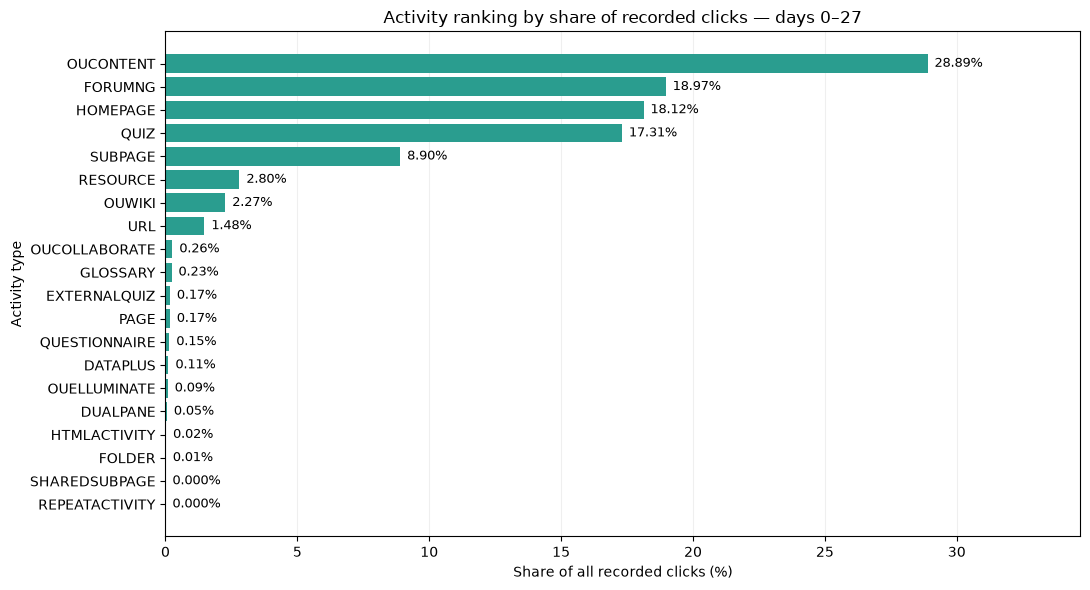

In [98]:
ranking_plot = activity_ranking.sort_values(
    "TotalClicks",
    ascending=True
)

fig, ax = plt.subplots(figsize=(11, 6
))

bars = ax.barh(
    ranking_plot.index,
    ranking_plot["ClickSharePct"],
    color="#2A9D8F"
)

# إظهار النسب الصغيرة دون تقريبها إلى صفر
percentage_labels = [
    f"{value:.2f}%" if value >= 0.01 else f"{value:.3f}%"
    for value in ranking_plot["ClickSharePct"]
]

ax.bar_label(
    bars,
    labels=percentage_labels,
    padding=5,
    fontsize=9
)

ax.set_title("Activity ranking by share of recorded clicks — days 0–27")
ax.set_xlabel("Share of all recorded clicks (%)")
ax.set_ylabel("Activity type")

ax.set_xlim(
    0,
    ranking_plot["ClickSharePct"].max() * 1.20
)

ax.grid(axis="x", alpha=0.2)
ax.set_axisbelow(True)

plt.tight_layout()
plt.show()

**Compare activity types as a share of clicks within each outcome group**

In [99]:
activity_by_outcome = (
    df_activity_analysis
    .groupby(["OutcomeGroup", "ActivityType"])
    .agg(
        TotalClicks=("ActivityClicks", "sum"),

        UsingEnrollments=(
            "ActivityClicks",
            lambda x: x.gt(0).sum()
        )
    )
    .reset_index()
)

# المقام: جميع نقرات مجموعة النتيجة عبر جميع أنواع الأنشطة
group_total_clicks = (
    activity_by_outcome
    .groupby("OutcomeGroup")["TotalClicks"]
    .transform("sum")
)

activity_by_outcome["WithinOutcomeClickSharePct"] = (
    activity_by_outcome["TotalClicks"]
    / group_total_clicks.replace(0, np.nan)
    * 100
)

# أعلى 8 أنواع إجمالًا؛ مقام النسب يشمل جميع الأنواع
top_activities = activity_ranking.head(8).index.tolist()
outcome_order = ["SUCCESS", "WITHDRAWN", "FAIL"]

activity_share_comparison = (
    activity_by_outcome
    .pivot(
        index="ActivityType",
        columns="OutcomeGroup",
        values="WithinOutcomeClickSharePct"
    )
    .reindex(
        index=top_activities,
        columns=outcome_order
    )
)

activity_users_comparison = (
    activity_by_outcome
    .pivot(
        index="ActivityType",
        columns="OutcomeGroup",
        values="UsingEnrollments"
    )
    .reindex(
        index=top_activities,
        columns=outcome_order
    )
)

display(activity_share_comparison.round(2))
display(activity_users_comparison)

OutcomeGroup,SUCCESS,WITHDRAWN,FAIL
ActivityType,,,
OUCONTENT,29.58,24.48,27.23
FORUMNG,19.29,19.65,16.23
HOMEPAGE,17.81,20.49,18.62
QUIZ,17.29,15.22,18.85
SUBPAGE,8.37,11.41,10.83
RESOURCE,2.57,3.94,3.65
OUWIKI,2.40,1.69,1.72
URL,1.42,1.80,1.64


OutcomeGroup,SUCCESS,WITHDRAWN,FAIL
ActivityType,,,
OUCONTENT,14924,6126,5872
FORUMNG,14930,5483,5593
HOMEPAGE,15381,7140,6664
QUIZ,12107,3735,4131
SUBPAGE,15358,6525,6327
RESOURCE,15353,6192,6051
OUWIKI,6817,1832,1967
URL,13411,5370,5120


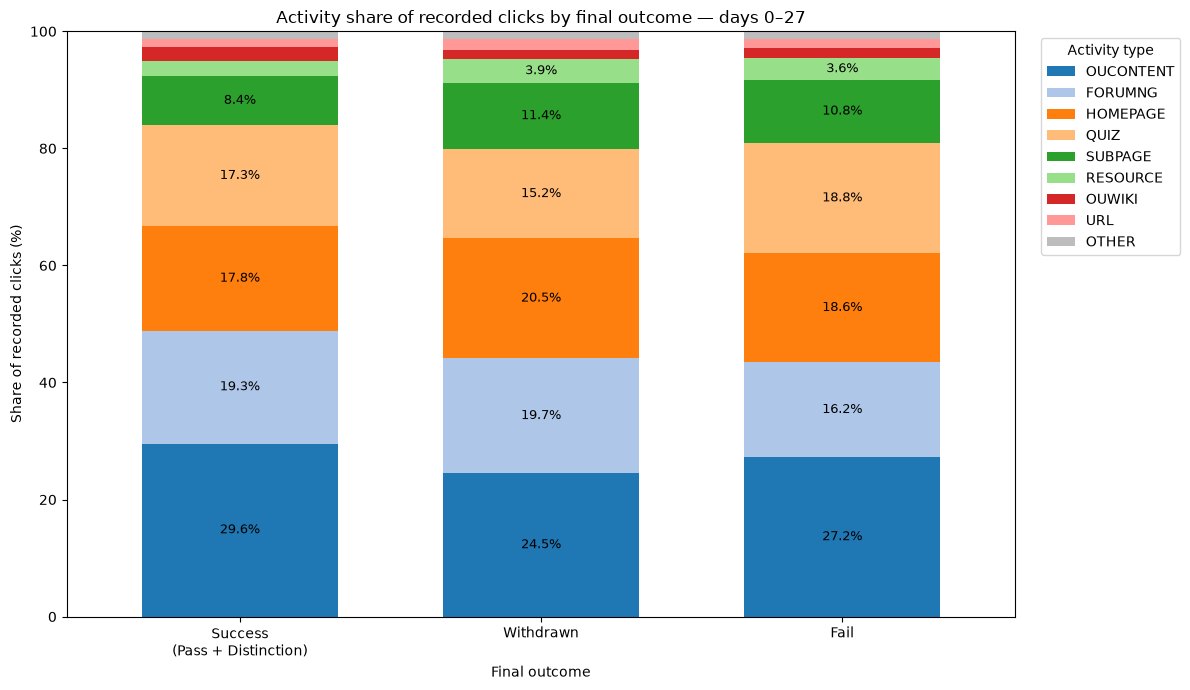

In [100]:
outcome_order = ["SUCCESS", "WITHDRAWN", "FAIL"]

outcome_labels = {
    "SUCCESS": "Success\n(Pass + Distinction)",
    "WITHDRAWN": "Withdrawn",
    "FAIL": "Fail"
}

top_activities = activity_ranking.head(8).index.tolist()

# إجمالي النقرات لكل نتيجة ونوع نشاط
activity_clicks_matrix = (
    activity_by_outcome
    .pivot(
        index="OutcomeGroup",
        columns="ActivityType",
        values="TotalClicks"
    )
    .reindex(index=outcome_order)
    .fillna(0)
)

# الأنواع الثمانية الأولى + بقية الأنواع
stacked_clicks = activity_clicks_matrix.reindex(
    columns=top_activities,
    fill_value=0
).copy()

stacked_clicks["OTHER"] = (
    activity_clicks_matrix
    .drop(columns=top_activities, errors="ignore")
    .sum(axis=1)
)

outcome_totals = stacked_clicks.sum(axis=1)

assert outcome_totals.gt(0).all(), \
    "توجد مجموعة نتائج دون نقرات؛ لا يمكن حساب حصتها."

stacked_shares = (
    stacked_clicks
    .div(outcome_totals, axis=0)
    .mul(100)
)

assert np.allclose(stacked_shares.sum(axis=1), 100)

# لون ثابت لكل نوع نشاط
palette = plt.get_cmap("tab20")
activity_colors = [
    palette(i) for i in range(len(top_activities))
] + ["#BDBDBD"]

ax = stacked_shares.plot(
    kind="bar",
    stacked=True,
    figsize=(12, 7),
    color=activity_colors,
    width=0.65,
    rot=0
)

# كتابة نسب الأجزاء الكبيرة فقط لتجنب تداخل النصوص
for container in ax.containers:
    ax.bar_label(
        container,
        labels=[
            f"{bar.get_height():.1f}%"
            if bar.get_height() >= 3 else ""
            for bar in container
        ],
        label_type="center",
        fontsize=9
    )

ax.set_xticklabels([
    outcome_labels[outcome]
    for outcome in stacked_shares.index
])

ax.set_title("Activity share of recorded clicks by final outcome — days 0–27")
ax.set_xlabel("Final outcome")
ax.set_ylabel("Share of recorded clicks (%)")
ax.set_ylim(0, 100)

ax.legend(
    title="Activity type",
    bbox_to_anchor=(1.02, 1),
    loc="upper left"
)

plt.tight_layout()
plt.show()

### <h3 style="color: yellow; font : bold;">6. Joint Analysis of Engagement and Assessment Submission</h3>

##### Do high-engagement, low-submission enrollments have different outcomes from enrollments that are high on both measures?

**Align engagement and submission measures to the same observation window**

In [101]:
keys = ["StudentID", "CourseOfferingCode"]

# التسجيلات المؤهلة للأيام 0–27 ولها سجلات تفاعل
joint_base = df_analysis_engagement.loc[
    df_analysis_engagement["EligibilityDays0_27"].eq("FULL_WINDOW")
    & df_analysis_engagement["HasInteractionRecords"],
    keys + ["ModuleCode", "FinalResult", "ClicksDays0_27"]
].copy()

assert not joint_base.duplicated(keys).any()
assert joint_base["ClicksDays0_27"].notna().all()

# التقييمات المستحقة خلال الفترة نفسها
early_assessments = expected_assessments.loc[
    expected_assessments["AssessmentDay"].between(0, 27)
    & expected_assessments["EligibilityStatus"].eq("Eligible")
].copy()

# حصرها في التسجيلات المؤهلة لتحليل التفاعل
early_assessments = early_assessments.merge(
    joint_base[keys],
    on=keys,
    how="inner",
    validate="many_to_one"
)

# الحالات غير المحسومة تحتاج استبعاد التسجيل من هذه المقارنة
current = early_assessments["RecordStatus"].eq("Current submission")

valid_submission_timing = (
    early_assessments["CanUseSubmissionDelay"].eq(True)
    & early_assessments["SubmittedDay"].ge(
        early_assessments["RegistrationDay"]
    )
).fillna(False)

early_assessments["UncertainAssessment"] = (
    early_assessments["RecordStatus"].eq("Unknown IsBanked")
    | (current & ~valid_submission_timing)
)

uncertain_enrollment = (
    early_assessments.groupby(keys)["UncertainAssessment"]
    .any()
    .rename("HasUncertainAssessment")
    .reset_index()
)

# استبعاد المرحّل والحالات غير المحسومة من متطلبات التسليم
required = early_assessments.loc[
    early_assessments["RecordStatus"].isin([
        "Current submission",
        "No submission record"
    ])
].copy()

# التسليم يُحتسب فقط لو تم بحلول نهاية اليوم 27
required["SubmittedByDay27"] = (
    required["RecordStatus"].eq("Current submission")
    & required["CanUseSubmissionDelay"].eq(True)
    & required["SubmittedDay"].ge(required["RegistrationDay"])
    & required["SubmittedDay"].le(27)
).fillna(False)

early_submission = (
    required.groupby(keys, as_index=False)
    .agg(
        RequiredAssessments=("AssessmentID", "size"),
        SubmittedByDay27=("SubmittedByDay27", "sum")
    )
    .merge(
        uncertain_enrollment,
        on=keys,
        how="left",
        validate="one_to_one"
    )
)

early_submission = early_submission.loc[
    ~early_submission["HasUncertainAssessment"]
].copy()

early_submission["SubmissionRateByDay27Pct"] = (
    early_submission["SubmittedByDay27"]
    / early_submission["RequiredAssessments"]
    * 100
)

# الدمج على مستوى التسجيل
df_joint = joint_base.merge(
    early_submission,
    on=keys,
    how="inner",
    validate="one_to_one"
)

df_joint["Outcome"] = (
    df_joint["FinalResult"]
    .astype("string")
    .str.strip()
    .str.upper()
)

df_joint = df_joint.loc[
    df_joint["Outcome"].isin(["PASS", "DISTINCTION", "FAIL", "WITHDRAWN"])
].copy()

if df_joint.empty:
    raise ValueError("لا توجد تسجيلات مؤهلة للمقارنة خلال الأيام 0–27.")

# التغطية: مهم لمعرفة المقررات الممثلة في التحليل
coverage = (
    joint_base.groupby("ModuleCode").size()
    .rename("EligibleWithInteractionRecords")
    .to_frame()
    .join(
        df_joint.groupby("ModuleCode").size()
        .rename("IncludedInJointAnalysis")
    )
    .fillna(0)
    .astype(int)
)

display(coverage)

,EligibleWithInteractionRecords,IncludedInJointAnalysis
ModuleCode,,
AAA,710,693
BBB,6132,6058
CCC,3441,3407
DDD,5184,5039
EEE,2496,0
FFF,6492,6336
GGG,2299,0


**Define the comparison groups and calculate outcome rates**

In [102]:
# وسيط النقرات داخل كل تقديم بين التسجيلات الداخلة في المقارنة
df_joint["OfferingMedianClicks"] = (
    df_joint.groupby("CourseOfferingCode")["ClicksDays0_27"]
    .transform("median")
)

df_joint["HighEngagement"] = (
    df_joint["ClicksDays0_27"].gt(0)
    & df_joint["ClicksDays0_27"].ge(df_joint["OfferingMedianClicks"])
)

df_joint["HighSubmission"] = (
    df_joint["SubmissionRateByDay27Pct"].ge(80)
)

df_joint["JointGroup"] = np.select(
    [
        df_joint["HighEngagement"] & df_joint["HighSubmission"],
        df_joint["HighEngagement"] & ~df_joint["HighSubmission"],
        ~df_joint["HighEngagement"] & df_joint["HighSubmission"]
    ],
    [
        "High engagement / High submission",
        "High engagement / Low submission",
        "Low engagement / High submission"
    ],
    default="Low engagement / Low submission"
)

df_joint["IsSuccess"] = df_joint["Outcome"].isin(["PASS", "DISTINCTION"])
df_joint["IsFail"] = df_joint["Outcome"].eq("FAIL")
df_joint["IsWithdrawn"] = df_joint["Outcome"].eq("WITHDRAWN")

group_order = [
    "High engagement / High submission",
    "High engagement / Low submission",
    "Low engagement / High submission",
    "Low engagement / Low submission"
]

joint_summary = (
    df_joint.groupby("JointGroup")
    .agg(
        EnrollmentCount=("StudentID", "size"),
        SuccessCount=("IsSuccess", "sum"),
        FailCount=("IsFail", "sum"),
        WithdrawnCount=("IsWithdrawn", "sum")
    )
    .reindex(group_order, fill_value=0)
)

denominator = joint_summary["EnrollmentCount"].replace(0, np.nan)

for count_column, rate_column in [
    ("SuccessCount", "SuccessRatePct"),
    ("FailCount", "FailRatePct"),
    ("WithdrawnCount", "WithdrawalRatePct")
]:
    joint_summary[rate_column] = (
        joint_summary[count_column] / denominator * 100
    )

display(joint_summary.round(2))

,EnrollmentCount,SuccessCount,FailCount,WithdrawnCount,SuccessRatePct,FailRatePct,WithdrawalRatePct
JointGroup,,,,,,,
High engagement / High submission,10567,7328,1646,1593,69.35,15.58,15.08
High engagement / Low submission,241,55,86,100,22.82,35.68,41.49
Low engagement / High submission,8730,4389,2571,1770,50.27,29.45,20.27
Low engagement / Low submission,1995,216,963,816,10.83,48.27,40.9


**Visualize the comparison**

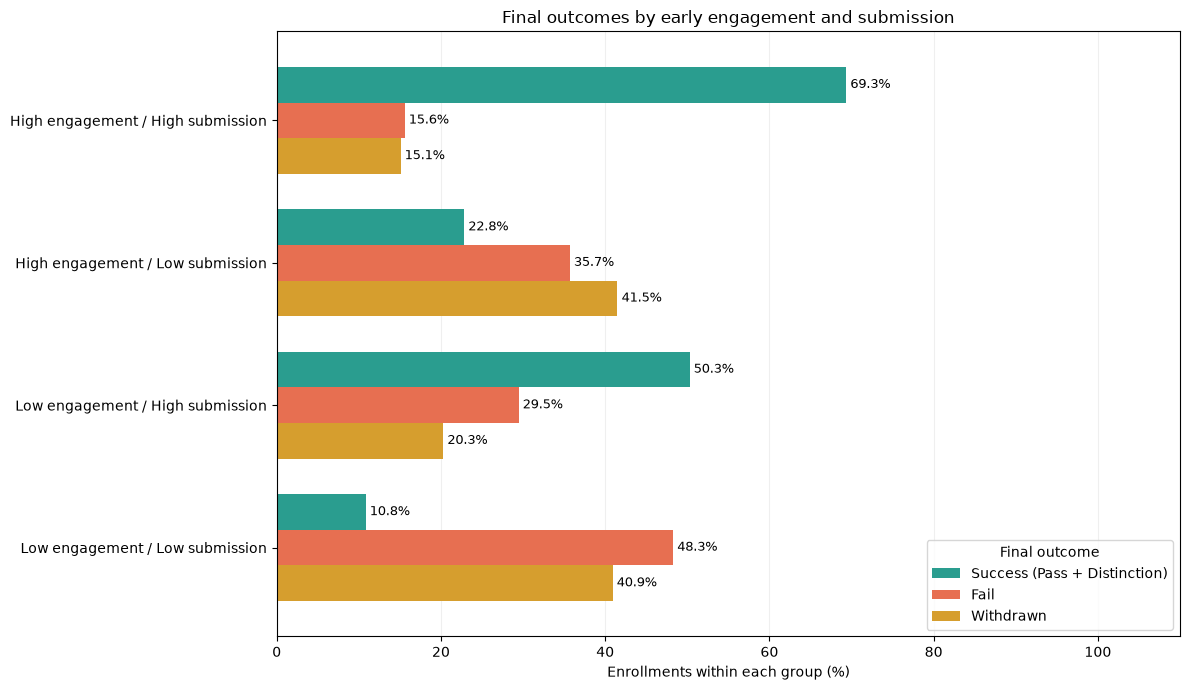

In [103]:
plot_data = joint_summary[
    ["SuccessRatePct", "FailRatePct", "WithdrawalRatePct"]
].rename(columns={
    "SuccessRatePct": "Success (Pass + Distinction)",
    "FailRatePct": "Fail",
    "WithdrawalRatePct": "Withdrawn"
})

ax = plot_data.plot(
    kind="barh",
    figsize=(12, 7),
    color=["#2A9D8F", "#E76F51", "#D69E2E"],
    width=0.75
)

for container in ax.containers:
    ax.bar_label(container, fmt="%.1f%%", padding=3, fontsize=9)

ax.set_title("Final outcomes by early engagement and submission")
ax.set_xlabel("Enrollments within each group (%)")
ax.set_ylabel("")
ax.set_xlim(0, 110)
ax.invert_yaxis()
ax.grid(axis="x", alpha=0.2)
ax.set_axisbelow(True)
ax.legend(title="Final outcome", loc="lower right")

plt.tight_layout()
plt.show()

Combining engagement and assessment submission measures for days 0–27 revealed clear differences in final outcomes. High engagement together with high submission was associated with the highest success rate, while low submission was associated with weaker outcomes even when engagement was high. These findings support monitoring assessment completion alongside clicks when identifying enrollments that may need additional support.

### <h3 style="color: orange;">Create Requirments.txt</h3>


In [1]:
import sys
import subprocess
from pathlib import Path

result = subprocess.run(
    [sys.executable, "-m", "pip", "freeze"],
    capture_output=True,
    text=True,
    check=True
)

Path("requirements.txt").write_text(result.stdout, encoding="utf-8")

994

In [ ]:
# مكان الملف على الجهاز
from pathlib import Path

print(Path("requirements.txt").resolve())

E:\Data Analysis Diploma\Final Project\OULAD Project\@@Final Work\python analytical\requirements.txt


In [ ]:
# عرض أسماء المكتبات وإصداراتها الموجودة فيه
print(Path("requirements.txt").read_text(encoding="utf-8"))

كود تثبيت المكتبات الموجودة فى الملف

python -m pip install -r requirements.txt